# 📊 Modélisation et Mesure du Risque de Portefeuille
### Théorie de Markowitz · VaR / CVaR · Stress Testing
**Application à un échantillon de 10 actions US (2019–2025) — benchmark : S&P 500**

*Projet de Fin d'Année (PFA) — Mohamed El Otmany · Ingénierie Finance & Actuariat, FST Errachidia*

---

### 🎯 Problématique

> **Le portefeuille « optimal » de Markowitz est-il réellement optimal lorsqu'il est confronté à la non-normalité des rendements, à l'incertitude d'estimation des paramètres et aux événements de crise ?**

### 🗺️ Plan et fil conducteur

| Partie | Contenu | Question posée |
|---|---|---|
| **1** | Data & Statistiques | Les rendements sont-ils gaussiens ? Quelle est la structure de dépendance ? |
| **2** | Optimisation de Markowitz | Que produit l'optimiseur, et pourquoi faut-il le *corriger* (Error Maximization) ? |
| **3** | Mesure du risque | Quelle VaR/CVaR est fiable sous queues épaisses ? (Backtesting Kupiec & Christoffersen) |
| **4** | Stress Testing & Résilience | Que se passe-t-il dans les 5 % restants ? Comment le portefeuille se compare-t-il au S&P 500 ? |
| **5** | Conclusion & Limites | Qu'a-t-on démontré, et que reste-t-il à faire ? |

**Chaîne logique du projet :**
`Non-normalité (JB)` → `Markowitz instable / concentré` → `Contrainte de poids (25 %)` → `VaR paramétrique dangereuse` → `CVaR + Student-t` → `Stress tests & Drawdown`.

## ⚙️ Configuration globale et imports

**🎯 Objectif.** Centraliser *tous* les hyper-paramètres du projet (période, univers, taux sans risque, niveau de confiance, contrainte de poids…) dans une seule cellule. Cela garantit la **reproductibilité** et permet de refaire tourner l'ensemble du notebook en changeant une seule valeur.

> ⚠️ **Kaggle** : activer *Settings → Internet → On* pour que `yfinance` puisse télécharger les données.

In [3]:
# ============================================================
# ⚙️ IMPORTS & CONFIGURATION GLOBALE
# ============================================================
import sys, subprocess, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import minimize, linprog
from scipy.special import xlogy, xlog1py
from statsmodels.stats.diagnostic import acorr_ljungbox

try:
    import yfinance as yf
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "yfinance"])
    import yfinance as yf

warnings.filterwarnings("ignore")
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("ggplot")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

# ---------------- Paramètres du projet ----------------
START, END   = "2019-01-01", "2025-01-01"      # END exclu par yfinance (données jusqu'au 31/12/2024)
TICKERS      = ["AAPL", "MSFT", "NVDA", "AMZN", "GOOGL", "META", "JPM", "JNJ", "XOM", "KO"]
BENCHMARK    = "^GSPC"                          # S&P 500
SECTORS      = {"AAPL": "Technologie", "MSFT": "Technologie", "NVDA": "Semi-conducteurs",
                "AMZN": "Conso. discrétionnaire", "GOOGL": "Communication", "META": "Communication",
                "JPM": "Finance", "JNJ": "Santé", "XOM": "Énergie", "KO": "Conso. de base"}

R0           = 0.03        # taux sans risque annuel
TRADING_DAYS = 252         # jours de bourse / an
MAX_WEIGHT   = 0.25        # contrainte de poids maximal par action (correction Error Maximization)
ALPHAS       = (0.95, 0.99)  # niveaux de confiance VaR / CVaR
WINDOW       = 250         # fenêtre glissante du backtesting (≈ 1 an de bourse)
N_SIM        = 100_000     # nombre de scénarios Monte Carlo (VaR statique)
N_SIM_ROLL   = 20_000      # nombre de scénarios Monte Carlo (backtesting roulant)
CAPITAL      = 10_000      # capital initial des simulations de performance
SEED         = 42
np.random.seed(SEED)

print(f"✅ Configuration chargée | {len(TICKERS)} actions | {START} → {END} | R0 = {R0:.1%} | cap = {MAX_WEIGHT:.0%}")

✅ Configuration chargée | 10 actions | 2019-01-01 → 2025-01-01 | R0 = 3.0% | cap = 25%


# 📈 PARTIE 1 — Data & Statistiques
*Prix · log-rendements · non-normalité · corrélations*

Cette première partie construit les **inputs** de tout le projet : le vecteur des rendements espérés $\mu$ et la matrice de covariance $\Sigma$. Elle établit surtout un **fait empirique fondateur** — la non-normalité des rendements — dont découleront les choix méthodologiques des Parties 2, 3 et 4.

## 📥 Étape 1.1 — Collecte des données de marché

**🎯 Objectif.** Constituer un panel de **10 grandes capitalisations US** couvrant **8 secteurs** (technologie, communication, finance, santé, énergie, consommation) sur 2019–2025. La période est volontairement riche en régimes de marché : **bull market**, **krach COVID (mars 2020)**, **resserrement monétaire 2022**, **boom de l'IA (2023-24)**. Le S&P 500 sert de **benchmark** de comparaison.

On utilise les **prix ajustés** (dividendes et splits réinvestis) : ce sont les seuls prix pertinents pour calculer un rendement *total*.

### 📐 Cadre théorique

Le **prix ajusté** $\tilde P_t$ corrige le prix brut $P_t$ des détachements de dividendes et des divisions d'actions, de sorte que
$$\frac{\tilde P_t}{\tilde P_{t-1}} = \frac{P_t + D_t}{P_{t-1}}$$
représente le **rendement total** du titre entre $t-1$ et $t$.

On ne conserve que les dates où **toutes** les séries sont observées (`dropna`) afin que la matrice de covariance soit estimée sur un échantillon cohérent.

In [4]:
# ============================================================
# 📥 COLLECTE DES DONNÉES — yfinance avec mécanisme de retry
# ============================================================
def download_prices(tickers, start, end, max_retries=3, pause=5):
    '''Télécharge les prix ajustés (auto_adjust=True) avec plusieurs tentatives en cas de timeout.'''
    for attempt in range(1, max_retries + 1):
        try:
            print(f"⏳ Tentative {attempt}/{max_retries}...")
            data = yf.download(tickers, start=start, end=end, auto_adjust=True,
                               progress=False, timeout=30, threads=False)["Close"]
            if not data.empty:
                print(f"✅ Téléchargement réussi (tentative {attempt})")
                return data
        except Exception as exc:
            print(f"⚠️ Échec : {exc}")
        time.sleep(pause)
    raise RuntimeError("❌ Échec du téléchargement : vérifiez que l'Internet est activé (Settings → Internet).")

raw_prices = download_prices(TICKERS + [BENCHMARK], START, END)
missing = [t for t in TICKERS + [BENCHMARK] if t not in raw_prices.columns]
assert not missing, f"Tickers manquants : {missing}"

# Alignement des dates : on garde uniquement les jours où TOUS les actifs sont cotés
prices = raw_prices[TICKERS + [BENCHMARK]].dropna(how="any")

print(f"\nPériode effective   : {prices.index[0].date()} → {prices.index[-1].date()}")
print(f"Observations (prix) : {len(prices)}   |   Séries : {prices.shape[1]}   |   Lignes supprimées (NaN) : {len(raw_prices) - len(prices)}")

univers = pd.DataFrame({"Secteur": pd.Series(SECTORS),
                        "Prix initial ($)": prices[TICKERS].iloc[0].round(2),
                        "Prix final ($)":   prices[TICKERS].iloc[-1].round(2)})
univers

⏳ Tentative 1/3...
✅ Téléchargement réussi (tentative 1)

Période effective   : 2019-01-02 → 2024-12-31
Observations (prix) : 1510   |   Séries : 11   |   Lignes supprimées (NaN) : 0


,Secteur,Prix initial ($),Prix final ($)
AAPL,Technologie,37.41,248.43
MSFT,Technologie,94.02,415.78
NVDA,Semi-conducteurs,3.37,133.94
AMZN,Conso. discrétionnaire,76.96,219.39
GOOGL,Communication,52.24,188.20
META,Communication,134.39,582.17
JPM,Finance,80.07,230.31
JNJ,Santé,103.28,138.10
XOM,Énergie,49.04,101.08
KO,Conso. de base,37.12,59.32


### 🧠 Interprétation

- Le panel contient **environ 1 500 observations journalières** (2019 → 2024) pour **10 titres + 1 indice**, ce qui est largement suffisant pour estimer une matrice de covariance $10\times10$ (55 paramètres distincts), mais **insuffisant pour estimer précisément les rendements espérés** (voir Étape 2.4).
- L'univers est **diversifié sectoriellement**, mais **6 titres sur 10 appartiennent au bloc « Big Tech / croissance »** (AAPL, MSFT, NVDA, AMZN, GOOGL, META). On anticipe donc une **corrélation élevée au sein de ce bloc**, et un risque de concentration factorielle déguisée en diversification apparente.
- ⚠️ **Biais de sélection (survivorship / look-ahead)** : ces 10 titres sont des *gagnants ex-post* de la décennie. Les performances in-sample de la Partie 2 sont donc **optimistes** — limite à rappeler en conclusion.

## 📉 Étape 1.2 — Du prix au log-rendement : stationnarité et *volatility clustering*

**🎯 Objectif.** Les prix suivent une tendance et ne sont **pas stationnaires** : aucun modèle statistique sérieux ne peut s'appliquer directement dessus. On travaille donc sur les **log-rendements**, qui oscillent autour de zéro. On vérifie ensuite visuellement **et statistiquement** le fait stylisé central des séries financières : le **regroupement de volatilité** (*volatility clustering*).

### 📐 Cadre théorique

**Log-rendement :**
$$r_t = \ln\!\left(\frac{P_t}{P_{t-1}}\right)$$

Propriétés : **additivité temporelle** ($r_{t\to t+k}=\sum_{i} r_{t+i}$), symétrie, et proximité avec le rendement simple pour de petites variations.

**Faits stylisés** (Cont, 2001) : absence d'autocorrélation des $r_t$, **queues épaisses**, **clusters de volatilité** (les $r_t^2$ sont autocorrélés).

**Test de Ljung-Box** sur $r_t^2$ ($H_0$ : pas d'autocorrélation jusqu'au retard $m$) :
$$Q = T(T+2)\sum_{k=1}^{m}\frac{\hat\rho_k^{\,2}}{T-k}\;\sim\;\chi^2(m)$$
Un rejet de $H_0$ sur $r_t^2$ est la signature d'une **variance conditionnelle** (effet ARCH/GARCH).

✅ Log-rendements calculés : 1509 jours × 10 actifs


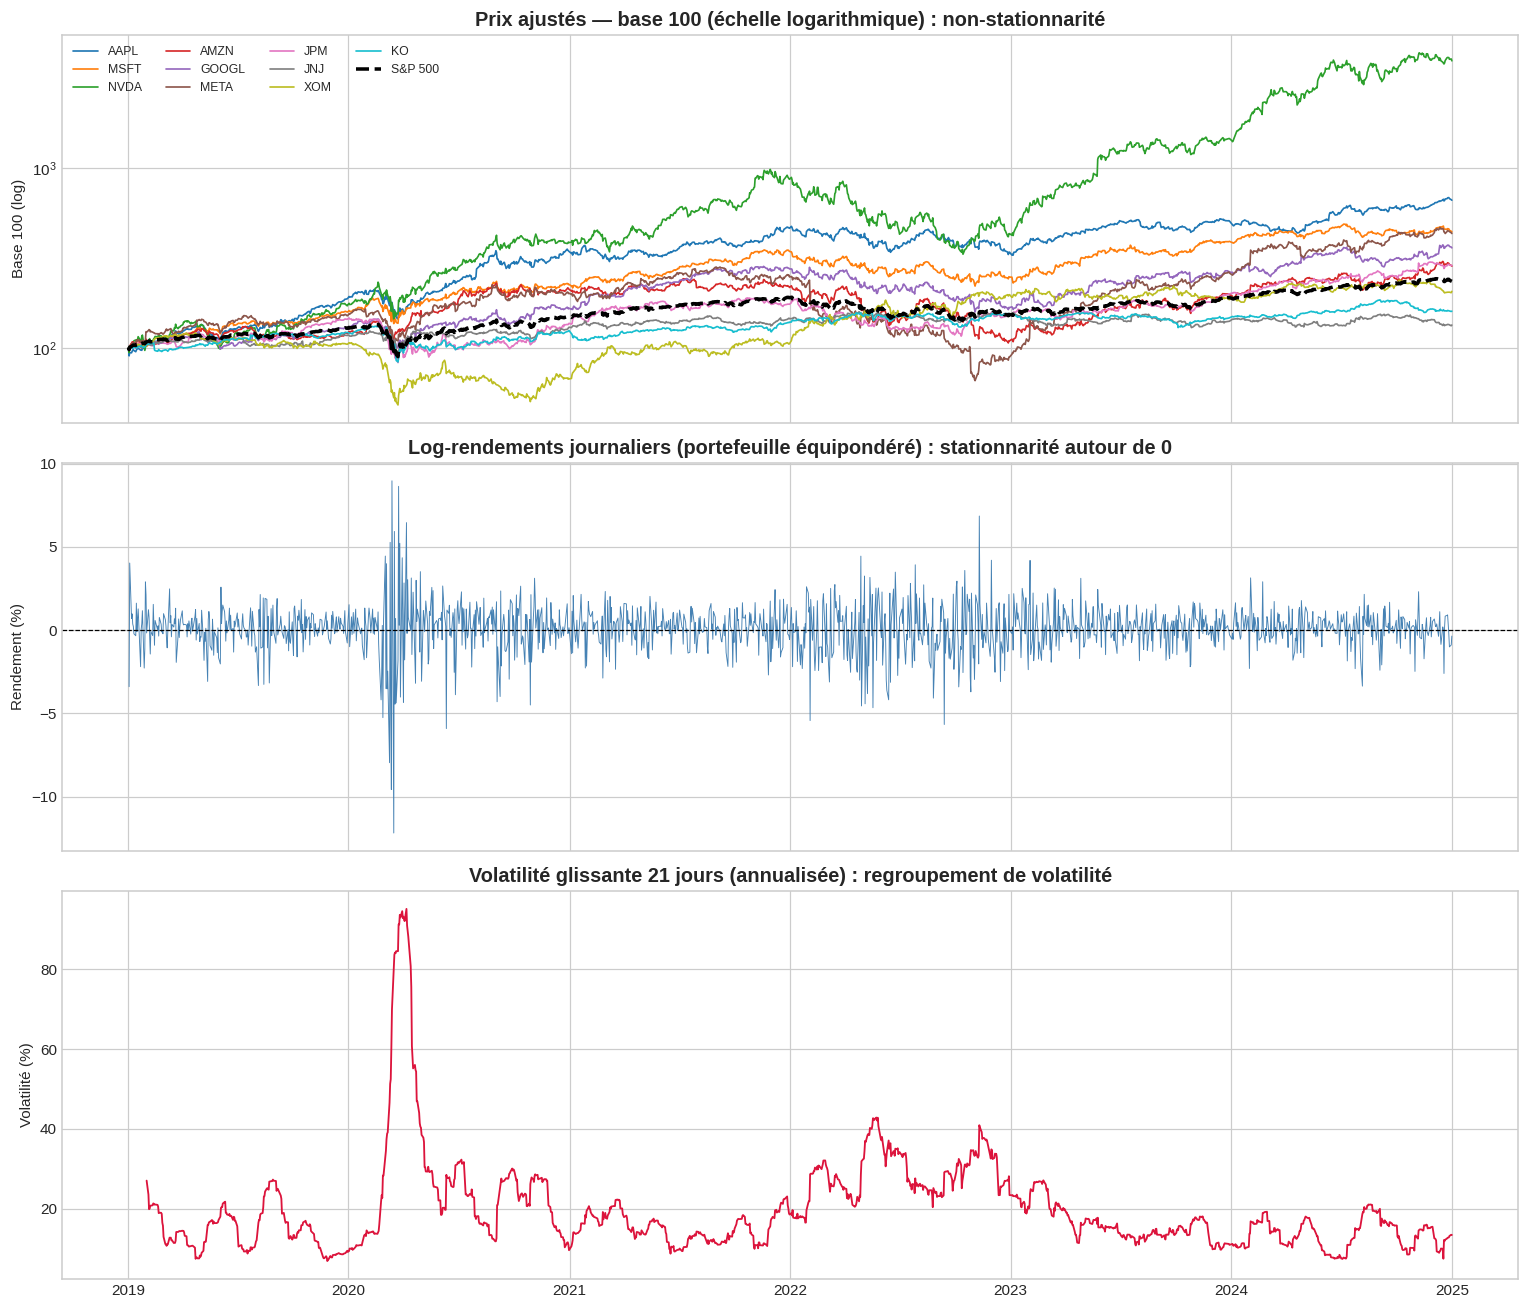

TEST DE LJUNG-BOX SUR r² (H0 : absence d'effet ARCH)
        lb_stat  lb_pvalue
10  1651.160942        0.0
20  1971.920646        0.0

📝 Lecture automatique : H0 REJETÉE → variance conditionnelle (clusters de volatilité)


In [5]:
# ============================================================
# 📉 LOG-RENDEMENTS & VOLATILITY CLUSTERING
# ============================================================
log_ret    = np.log(prices / prices.shift(1)).dropna()   # r_t = ln(P_t / P_{t-1})
ret_assets = log_ret[TICKERS]                            # 10 actions (ordre conservé)
ret_bench  = log_ret[BENCHMARK]                          # S&P 500

print(f"✅ Log-rendements calculés : {ret_assets.shape[0]} jours × {ret_assets.shape[1]} actifs")

# Proxy « marché équipondéré » pour les diagnostics visuels
ew_log_ret = ret_assets.mean(axis=1)
roll_vol   = ew_log_ret.rolling(21).std() * np.sqrt(TRADING_DAYS)   # volatilité glissante 1 mois, annualisée

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

base100 = prices / prices.iloc[0] * 100
base100[TICKERS].plot(ax=axes[0], lw=1.1)
base100[BENCHMARK].plot(ax=axes[0], color="black", lw=2.3, ls="--", label="S&P 500")
axes[0].set_yscale("log")
axes[0].set_title("Prix ajustés — base 100 (échelle logarithmique) : non-stationnarité")
axes[0].set_ylabel("Base 100 (log)")
axes[0].legend(ncol=4, fontsize=8, loc="upper left")

axes[1].plot(ew_log_ret.index, ew_log_ret * 100, lw=0.6, color="steelblue")
axes[1].axhline(0, color="black", lw=0.8, ls="--")
axes[1].set_title("Log-rendements journaliers (portefeuille équipondéré) : stationnarité autour de 0")
axes[1].set_ylabel("Rendement (%)")

axes[2].plot(roll_vol.index, roll_vol * 100, lw=1.2, color="crimson")
axes[2].set_title("Volatilité glissante 21 jours (annualisée) : regroupement de volatilité")
axes[2].set_ylabel("Volatilité (%)")
plt.tight_layout()
plt.show()

# Test de Ljung-Box sur les rendements au carré
lb = acorr_ljungbox(ew_log_ret ** 2, lags=[10, 20], return_df=True)
print("=" * 70)
print("TEST DE LJUNG-BOX SUR r² (H0 : absence d'effet ARCH)")
print("=" * 70)
print(lb.round(6).to_string())
verdict = "REJETÉE → variance conditionnelle (clusters de volatilité)" if (lb["lb_pvalue"] < 0.05).all() else "non rejetée"
print(f"\n📝 Lecture automatique : H0 {verdict}")

### 🧠 Interprétation

- **Panneau 1 — Prix.** Les prix présentent une tendance haussière marquée avec deux creux visibles : le **krach COVID de mars 2020** et le **marché baissier de 2022**. **NVDA** se détache nettement du lot sur l'échelle logarithmique : c'est le titre qui « tirera » l'optimiseur de Markowitz dans la Partie 2.
- **Panneau 2 — Rendements.** Contrairement aux prix, les log-rendements **oscillent autour de zéro** : la série est (faiblement) stationnaire, condition nécessaire pour estimer $\mu$ et $\Sigma$.
- **Panneau 3 — Volatilité.** On observe un **pic de volatilité spectaculaire en mars 2020** suivi d'une décroissance lente : la volatilité **n'est pas constante**, elle est *persistante*. Le test de Ljung-Box sur $r_t^2$ rejette l'absence d'autocorrélation, ce qui confirme l'effet ARCH.
- **Conséquence pour le projet :** l'hypothèse d'une volatilité constante (sous-jacente à la VaR paramétrique classique) est **violée**. Une VaR calibrée sur une fenêtre calme *sous-estimera* le risque en période de crise → motivation du **backtesting** (Partie 3) et de l'**extension GARCH** (Partie 5).

## 📊 Étape 1.3 — Statistiques descriptives et couple rendement/risque

**🎯 Objectif.** Résumer chaque actif par ses quatre premiers moments ($\mu$, $\sigma$, asymétrie, kurtosis) et son ratio de Sharpe individuel. Ces statistiques **alimentent directement** l'optimiseur de Markowitz (Partie 2) : toute erreur à ce stade se propage à l'allocation finale.

### 📐 Cadre théorique

Pour des log-rendements journaliers $r_t$ de moyenne $\bar r$ et d'écart-type $\hat\sigma$ :

$$\mu_{ann}=252\cdot\bar r \qquad\qquad \sigma_{ann}=\sqrt{252}\cdot\hat\sigma$$

(la variance étant additive dans le temps sous hypothèse d'indépendance des rendements : règle du $\sqrt{T}$).

$$\text{Skew}=\mathbb{E}\!\left[\left(\tfrac{r-\bar r}{\hat\sigma}\right)^{3}\right]\qquad \text{Kurt}=\mathbb{E}\!\left[\left(\tfrac{r-\bar r}{\hat\sigma}\right)^{4}\right]\;(=3\text{ si loi normale})$$

$$\text{Sharpe}_i=\frac{\mu_{ann,i}-R^0}{\sigma_{ann,i}}$$

STATISTIQUES DESCRIPTIVES — 10 ACTIONS US (log-rendements journaliers, annualisés)
                      Secteur  Rendement ann. (%)  Volatilité ann. (%)  Skewness  Kurtosis  Pire jour (%)  Meilleur jour (%)  Sharpe (R0=3%)
AAPL              Technologie               31.62                30.84    -0.230     8.697         -13.77              11.32           0.928
MSFT              Technologie               24.83                29.02    -0.305    10.907         -15.95              13.29           0.752
NVDA         Semi-conducteurs               61.50                51.60     0.074     6.735         -20.40              21.81           1.134
AMZN   Conso. discrétionnaire               17.49                34.12    -0.139     7.440         -15.14              12.69           0.425
GOOGL           Communication               21.40                31.22    -0.213     7.271         -12.37               9.73           0.589
META            Communication               24.48                42.94 

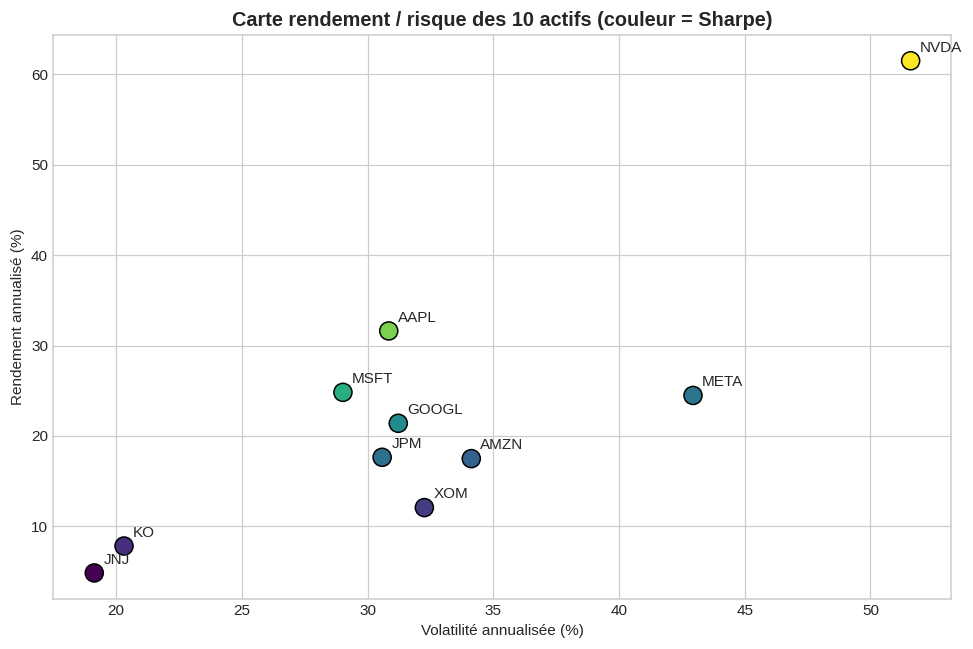

In [6]:
# ============================================================
# 📊 STATISTIQUES DESCRIPTIVES
# ============================================================
mu_ann    = ret_assets.mean() * TRADING_DAYS                 # rendement annualisé (moyenne des log-rendements × 252)
sigma_ann = ret_assets.std()  * np.sqrt(TRADING_DAYS)        # volatilité annualisée

summary = pd.DataFrame({
    "Secteur":              pd.Series(SECTORS),
    "Rendement ann. (%)":   (mu_ann * 100).round(2),
    "Volatilité ann. (%)":  (sigma_ann * 100).round(2),
    "Skewness":             ret_assets.skew().round(3),
    "Kurtosis":             (ret_assets.kurtosis() + 3).round(3),   # pandas renvoie l'excès → +3
    "Pire jour (%)":        (ret_assets.min() * 100).round(2),
    "Meilleur jour (%)":    (ret_assets.max() * 100).round(2),
})
summary["Sharpe (R0=3%)"] = ((mu_ann - R0) / sigma_ann).round(3)

print("=" * 110)
print("STATISTIQUES DESCRIPTIVES — 10 ACTIONS US (log-rendements journaliers, annualisés)")
print("=" * 110)
print(summary.to_string())

# Carte rendement / risque
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(sigma_ann * 100, mu_ann * 100, s=140, c=(mu_ann - R0) / sigma_ann, cmap="viridis", edgecolors="black")
for t in TICKERS:
    ax.annotate(t, (sigma_ann[t] * 100, mu_ann[t] * 100), xytext=(6, 6), textcoords="offset points", fontsize=10)
ax.set_xlabel("Volatilité annualisée (%)"); ax.set_ylabel("Rendement annualisé (%)")
ax.set_title("Carte rendement / risque des 10 actifs (couleur = Sharpe)")
plt.tight_layout(); plt.show()

### 🧠 Interprétation

- **NVDA** affiche le couple rendement/volatilité le plus extrême de l'échantillon : c'est à la fois le **meilleur performeur** et l'un des actifs les plus risqués. Son Sharpe in-sample très élevé en fait le candidat naturel d'un optimiseur « naïf ».
- À l'opposé, **KO et JNJ** (valeurs défensives) combinent faible volatilité et rendement modeste : ils joueront le rôle de **stabilisateurs** dans le portefeuille de variance minimale.
- La **kurtosis est supérieure à 3 pour les 10 actifs** (colonne `Kurtosis`) : les événements extrêmes sont **plus fréquents** que ne le prévoit une loi normale. Les colonnes « pire jour / meilleur jour » affichent des variations souvent supérieures à 10 % en valeur absolue, à comparer à $\sigma_{jour}\approx 1$–$3\,\%$ : ce sont des mouvements de **plusieurs écarts-types** (parfois plus de 5), dont la probabilité est infinitésimale sous la loi normale.
- ⚠️ **Piège méthodologique** : les $\mu_{ann}$ estimés ici sont des moyennes *historiques* sur 6 ans. Leur précision statistique est faible (erreur-type de plusieurs points de pourcentage), ce qui sera quantifié à l'Étape 2.4.

## 🔔 Étape 1.4 — Analyse de la non-normalité (Jarque-Bera & QQ-plots)

**🎯 Objectif.** Tester **formellement** l'hypothèse de normalité des rendements, hypothèse sous-jacente au modèle de Markowitz (variance comme mesure de risque suffisante) et à la VaR paramétrique. **Le résultat de ce test conditionne tout le reste du projet.**

### 📐 Cadre théorique

**Statistique de Jarque-Bera** (1980), construite sur l'asymétrie $S$ et la kurtosis $K$ :
$$JB=\frac{T}{6}\left(S^{2}+\frac{(K-3)^{2}}{4}\right)\;\xrightarrow[T\to\infty]{}\;\chi^{2}(2)\quad\text{sous }H_0:\ r_t\sim\mathcal N(\mu,\sigma^2)$$

Règle de décision : $JB>\chi^2_{0.95}(2)=5.99\ \Rightarrow$ **rejet de la normalité** au seuil de 5 %.

**QQ-plot** : on trace les quantiles empiriques contre les quantiles théoriques $\Phi^{-1}(p)$. Sous normalité, les points s'alignent sur la droite ; une courbe en **« S »** traduit des **queues plus épaisses** que la gaussienne.

TEST DE JARQUE-BERA (H0 : les rendements suivent une loi normale)
       Skewness  Kurtosis  JB (stat)  p-value Normalité (α=5%)
Actif                                                         
AAPL     -0.230      8.70     2037.4      0.0        ❌ Rejetée
MSFT     -0.305     10.91     3924.1      0.0        ❌ Rejetée
NVDA      0.074      6.73      870.6      0.0        ❌ Rejetée
AMZN     -0.139      7.44     1234.2      0.0        ❌ Rejetée
GOOGL    -0.213      7.27     1148.4      0.0        ❌ Rejetée
META     -1.202     27.42    37609.0      0.0        ❌ Rejetée
JPM      -0.009     16.54    11439.6      0.0        ❌ Rejetée
JNJ       0.068     11.11     4106.5      0.0        ❌ Rejetée
XOM      -0.161      8.30     1757.2      0.0        ❌ Rejetée
KO       -0.939     13.30     6844.3      0.0        ❌ Rejetée

📊 10/10 actifs rejettent la normalité | seuil critique χ²(2) à 95% = 5.99
📊 Kurtosis moyenne = 11.77 (loi normale = 3.00)


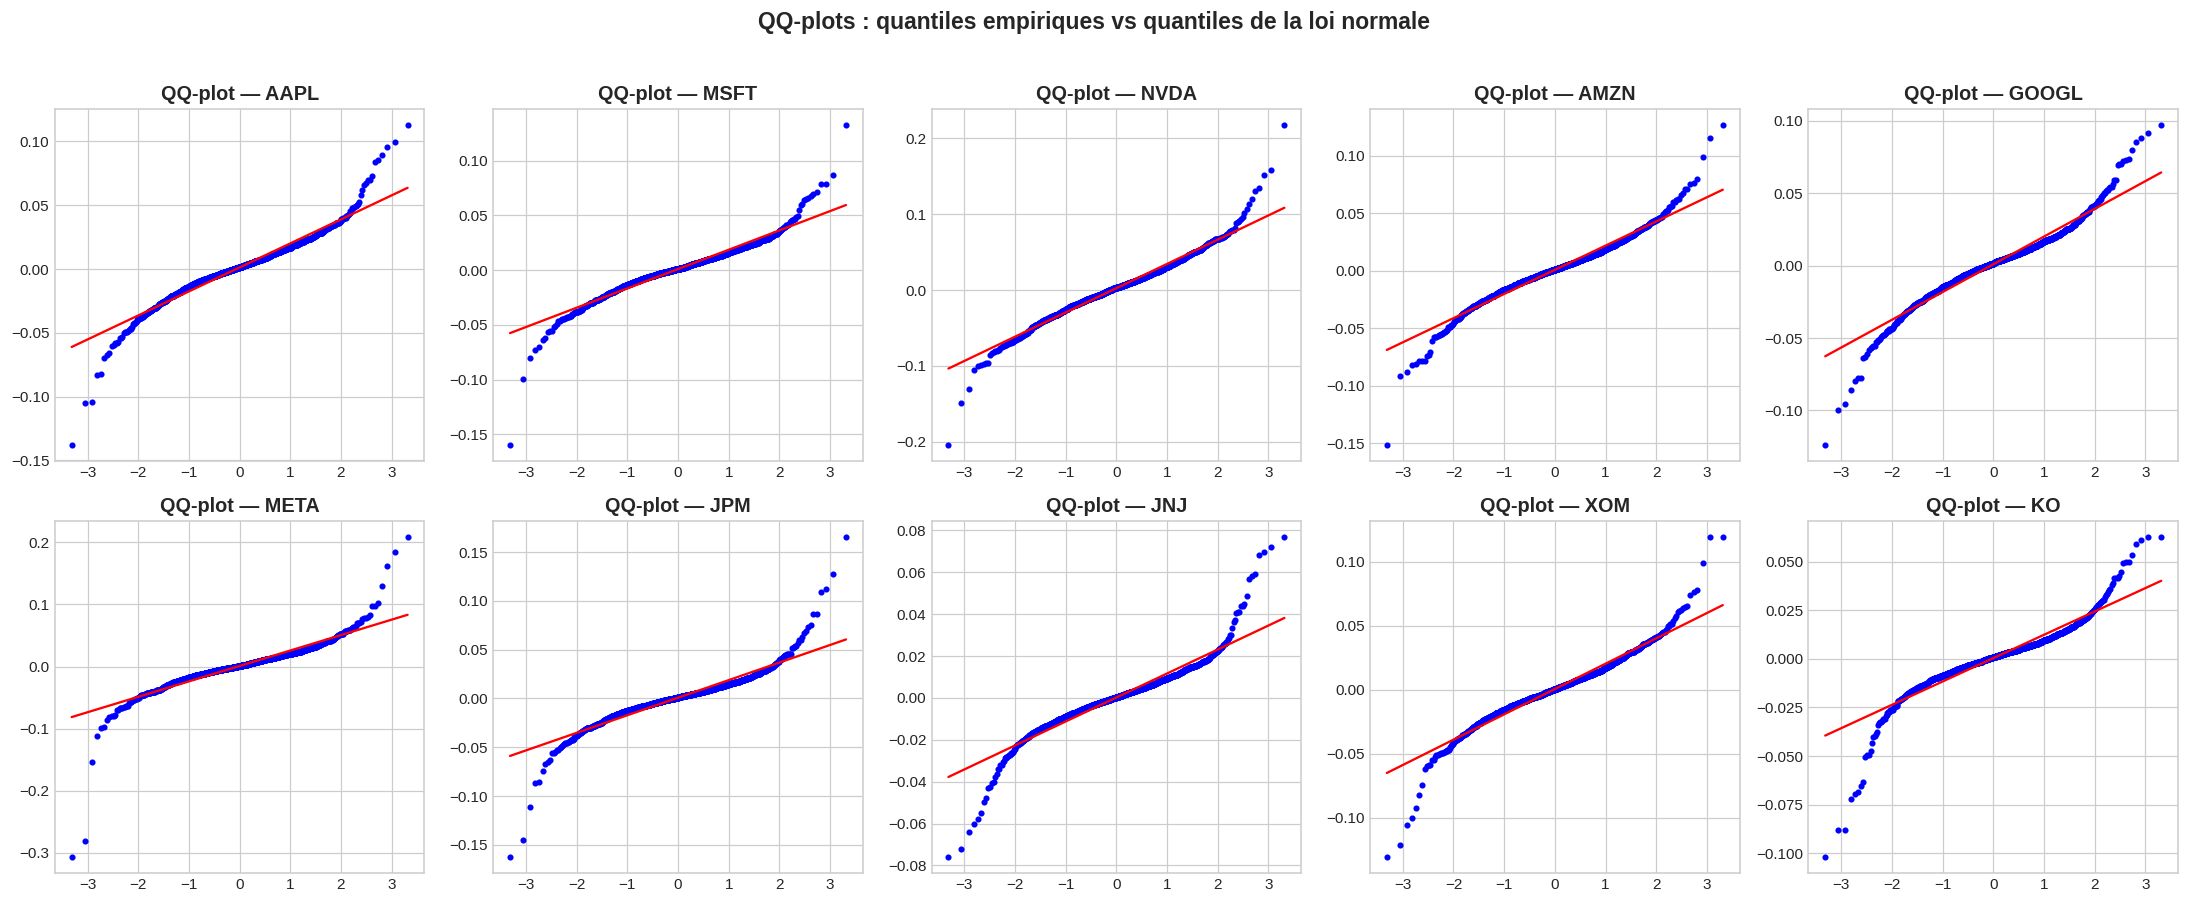

In [7]:
# ============================================================
# 🔔 TEST DE JARQUE-BERA + QQ-PLOTS
# ============================================================
jb_rows = []
for ticker in TICKERS:
    jb_stat, p_val = stats.jarque_bera(ret_assets[ticker])
    jb_rows.append({
        "Actif": ticker,
        "Skewness": ret_assets[ticker].skew(),
        "Kurtosis": ret_assets[ticker].kurtosis() + 3,
        "JB (stat)": jb_stat,
        "p-value": p_val,
        "Normalité (α=5%)": "❌ Rejetée" if p_val < 0.05 else "✅ Non rejetée",
    })
jb_table = pd.DataFrame(jb_rows).set_index("Actif")

print("=" * 85)
print("TEST DE JARQUE-BERA (H0 : les rendements suivent une loi normale)")
print("=" * 85)
print(jb_table.round({"Skewness": 3, "Kurtosis": 2, "JB (stat)": 1, "p-value": 6}).to_string())

n_reject = int((jb_table["p-value"] < 0.05).sum())
print(f"\n📊 {n_reject}/{len(TICKERS)} actifs rejettent la normalité | seuil critique χ²(2) à 95% = {stats.chi2.ppf(0.95, 2):.2f}")
print(f"📊 Kurtosis moyenne = {jb_table['Kurtosis'].mean():.2f} (loi normale = 3.00)")

# QQ-plots
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, ticker in zip(axes.flatten(), TICKERS):
    stats.probplot(ret_assets[ticker], dist="norm", plot=ax)
    ax.get_lines()[0].set_markersize(3)
    ax.set_title(f"QQ-plot — {ticker}")
    ax.set_xlabel(""); ax.set_ylabel("")
plt.suptitle("QQ-plots : quantiles empiriques vs quantiles de la loi normale", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

### 🧠 Interprétation

- **Le test de Jarque-Bera rejette la normalité pour les 10 actions** (p-values pratiquement nulles, statistiques $JB$ très supérieures au seuil critique de 5,99), avec une **kurtosis supérieure à 3 pour chaque titre**.
- Les **QQ-plots** montrent le motif caractéristique en « S » : les points s'écartent de la droite théorique **aux deux extrémités**. Les pertes extrêmes (queue gauche) sont donc **nettement plus lourdes** que ce que prédit la loi normale.
- **Conséquences directes pour la suite du projet :**
  1. 🔴 **VaR paramétrique gaussienne** : elle s'appuie sur une loi dont les queues sont trop fines → elle est **structurellement dangereuse** pour estimer le risque extrême.
  2. 🟠 **Variance comme mesure de risque** (Markowitz) : $\sigma$ ne capture pas le risque de queue → un portefeuille « optimal » en moyenne-variance peut être très risqué en queue.
  3. 🟢 **Réponses retenues** : **CVaR** (mesure sensible à la forme de la queue), **loi de Student-t** (queues épaisses) en Monte Carlo, et **stress testing** historique.

## 🔗 Étape 1.5 — Matrices de covariance et de corrélation

**🎯 Objectif.** Quantifier la **structure de dépendance** entre les actifs. C'est elle — et non la volatilité individuelle — qui détermine le **bénéfice de la diversification**. On mesure aussi le **conditionnement** de $\Sigma$, car une matrice mal conditionnée rend l'optimisation numériquement instable.

### 📐 Cadre théorique

$$\Sigma_{ij}=\text{Cov}(r_i,r_j)\cdot 252\qquad\qquad \rho_{ij}=\frac{\Sigma_{ij}}{\sigma_i\,\sigma_j}\in[-1,1]$$

**Variance d'un portefeuille** de poids $w$ :
$$\sigma_p^{2}=w^{\top}\Sigma\,w=\sum_i w_i^2\sigma_i^2+\sum_{i\neq j}w_iw_j\,\rho_{ij}\sigma_i\sigma_j$$
La diversification est d'autant plus efficace que les $\rho_{ij}$ sont faibles.

**Analyse en composantes principales** : la part de variance expliquée par la 1ʳᵉ valeur propre de la matrice de corrélation $\lambda_1/N$ mesure le poids du **facteur « marché »** commun.

**Nombre de conditionnement** : $\kappa(\Sigma)=\lambda_{max}/\lambda_{min}$. Plus $\kappa$ est élevé, plus l'inverse $\Sigma^{-1}$ (utilisé par Markowitz) **amplifie les erreurs d'estimation**.

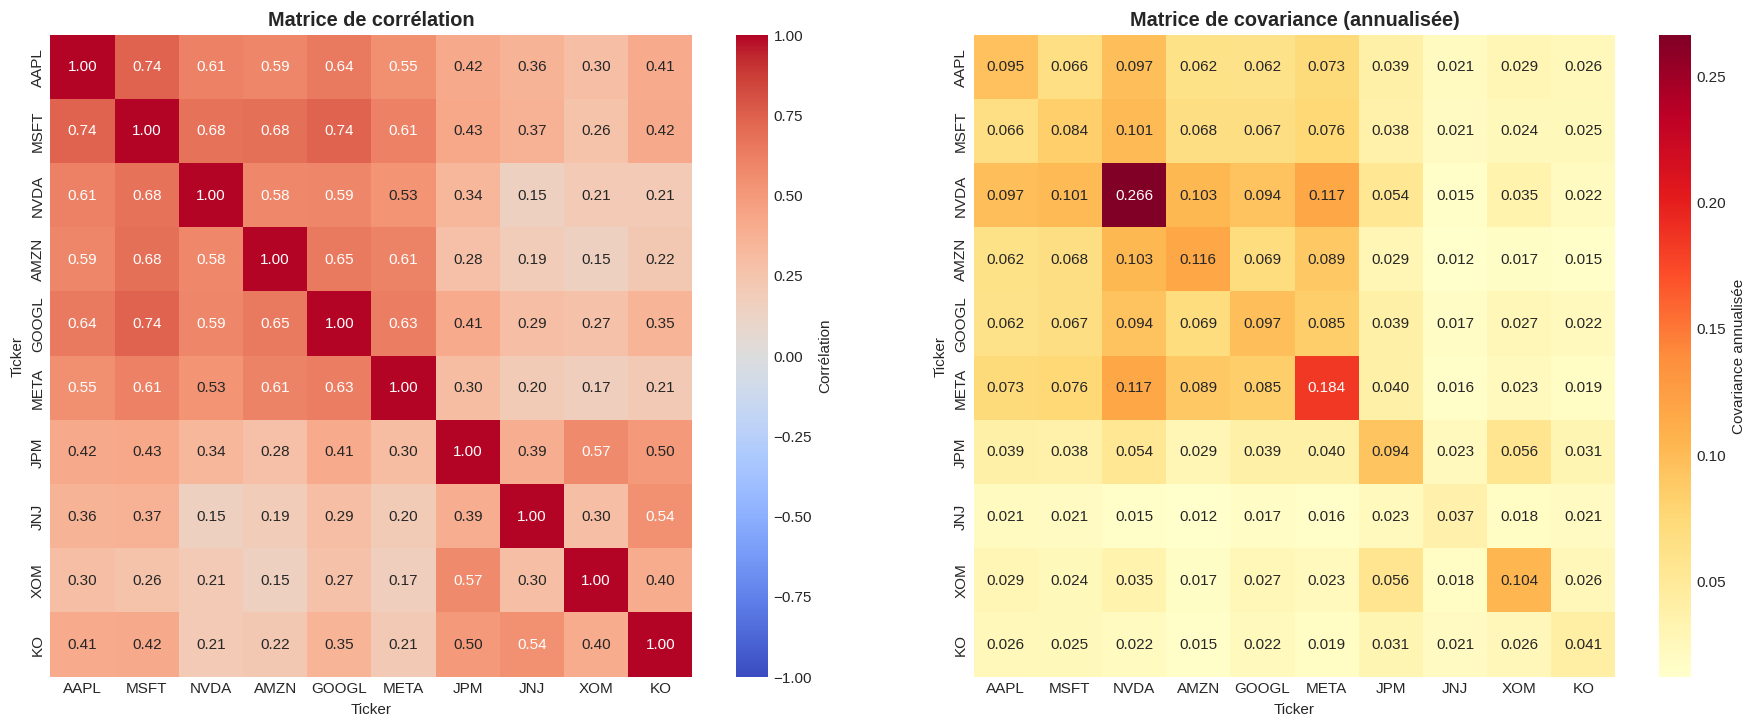

STATISTIQUES DE DÉPENDANCE
Corrélation moyenne          : 0.423
Corrélation min  (AMZN-XOM) : 0.151
Corrélation max  (MSFT-GOOGL) : 0.738
Part de variance du 1er facteur (λ1/N)   : 49.5%
Part cumulée des 3 premiers facteurs     : 74.0%
Nombre de conditionnement κ(Σ)           : 35.6

Corrélation moyenne intra-bloc Big Tech : 0.628
Corrélation moyenne Big Tech ↔ défensives: 0.288


In [8]:
# ============================================================
# 🔗 COVARIANCE, CORRÉLATION, ACP
# ============================================================
Sigma = ret_assets.cov() * TRADING_DAYS     # matrice de covariance annualisée
Corr  = ret_assets.corr()                   # matrice de corrélation

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(Corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, ax=axes[0], cbar_kws={"label": "Corrélation"})
axes[0].set_title("Matrice de corrélation")
sns.heatmap(Sigma, annot=True, fmt=".3f", cmap="YlOrRd", square=True, ax=axes[1],
            cbar_kws={"label": "Covariance annualisée"})
axes[1].set_title("Matrice de covariance (annualisée)")
plt.tight_layout(); plt.show()

# Statistiques sur les corrélations deux à deux
upper   = Corr.where(np.triu(np.ones(Corr.shape), k=1).astype(bool)).stack()
eigvals = np.sort(np.linalg.eigvalsh(Corr.values))[::-1]

print("=" * 65)
print("STATISTIQUES DE DÉPENDANCE")
print("=" * 65)
print(f"Corrélation moyenne          : {upper.mean():.3f}")
print(f"Corrélation min  ({upper.idxmin()[0]}-{upper.idxmin()[1]}) : {upper.min():.3f}")
print(f"Corrélation max  ({upper.idxmax()[0]}-{upper.idxmax()[1]}) : {upper.max():.3f}")
print(f"Part de variance du 1er facteur (λ1/N)   : {eigvals[0] / len(TICKERS):.1%}")
print(f"Part cumulée des 3 premiers facteurs     : {eigvals[:3].sum() / len(TICKERS):.1%}")
print(f"Nombre de conditionnement κ(Σ)           : {np.linalg.cond(Sigma.values):.1f}")

bloc_tech = ["AAPL", "MSFT", "NVDA", "AMZN", "GOOGL", "META"]
bloc_def  = ["JNJ", "KO", "XOM", "JPM"]
print(f"\nCorrélation moyenne intra-bloc Big Tech : {Corr.loc[bloc_tech, bloc_tech].values[np.triu_indices(6, 1)].mean():.3f}")
print(f"Corrélation moyenne Big Tech ↔ défensives: {Corr.loc[bloc_tech, bloc_def].values.mean():.3f}")

### 🧠 Interprétation

- **Les corrélations sont globalement positives** (cf. minimum imprimé) : aucune combinaison *long-only* de ces 10 titres ne permet de couvrir le risque de marché. Le **bloc Big Tech** (AAPL, MSFT, AMZN, GOOGL, META, NVDA) est fortement intercorrélé, tandis que les **valeurs défensives** (JNJ, KO) et **l'énergie** (XOM) présentent des corrélations nettement plus faibles avec le reste du panel : ce sont elles qui apportent l'essentiel du **bénéfice de diversification**.
- La **première composante principale** absorbe une part dominante de la variance totale : un **facteur marché commun** explique une grande partie des co-mouvements. La diversification sur 10 titres est donc réelle mais **limitée**.
- Le **nombre de conditionnement** de $\Sigma$ indique dans quelle mesure l'inversion de la matrice amplifie le bruit d'estimation : c'est un premier signal d'alerte avant l'optimisation.
- ✅ **Bilan de la Partie 1 :** nous disposons d'inputs $\mu$ et $\Sigma$ propres, mais nous savons déjà que (i) les rendements sont **non gaussiens**, (ii) $\mu$ est **estimé avec bruit**, (iii) la volatilité est **conditionnelle**. Ces trois faits motivent la suite.

# 🎯 PARTIE 2 — Optimisation de Markowitz
*Frontière efficiente · portefeuille tangent · correction de l'Error Maximization (contrainte à 25 %)*

**Question de la partie :** que produit réellement un optimiseur moyenne-variance sur nos données, et pourquoi sa solution « optimale » n'est-elle **pas exploitable telle quelle** ?

**Démarche :** (1) construire les portefeuilles de référence → (2) calculer le tangent libre → (3) tracer la frontière → (4) **diagnostiquer** l'*Error Maximization* → (5) **corriger** par une contrainte de poids → (6) **valider hors échantillon**.

## 🧱 Étape 2.1 — Cadre moyenne-variance et portefeuilles de référence

**🎯 Objectif.** Poser le cadre mathématique de Markowitz (1952) et construire deux **portefeuilles de référence** qui serviront de points de comparaison : le portefeuille **équipondéré** (naïf, sans estimation) et le portefeuille de **variance minimale** (n'utilise que $\Sigma$, donc insensible à l'erreur sur $\mu$).

L'intuition financière : *« ne pas mettre tous ses œufs dans le même panier »* — mais de façon **quantifiée** via les corrélations.

### 📐 Cadre théorique

Pour un vecteur de poids $w\in\mathbb R^{N}$ avec $\mathbf 1^\top w=1$ :

$$\mathbb E[R_p]=w^{\top}\mu\qquad\qquad \sigma_p=\sqrt{w^{\top}\Sigma\,w}\qquad\qquad S_p=\frac{w^{\top}\mu-R^0}{\sigma_p}$$

**Portefeuille de variance minimale (long-only) :**
$$\min_{w}\; w^{\top}\Sigma w\quad\text{s.c.}\quad \mathbf 1^{\top}w=1,\;\; w_i\ge 0$$

Sans contrainte de positivité, la solution est analytique : $w_{MV}=\dfrac{\Sigma^{-1}\mathbf 1}{\mathbf 1^{\top}\Sigma^{-1}\mathbf 1}$. Avec $w_i\ge0$, c'est un **programme quadratique** résolu numériquement (SLSQP).

*Approximation :* on estime $\mu$ et $\Sigma$ sur les log-rendements des actifs (standard en pratique à fréquence journalière) ; les rendements *réalisés* des portefeuilles (Parties 3–4) sont ensuite calculés **exactement** par agrégation des rendements simples.

In [ ]:
# ============================================================
# 🧱 FONCTIONS DE BASE & PORTEFEUILLES DE RÉFÉRENCE
# ============================================================
mu_vec     = mu_ann.values.astype(float)
Sigma_mat  = Sigma.values.astype(float)
N_ASSETS   = len(TICKERS)

NAME_EW, NAME_MV, NAME_TAN = "Équipondéré", "Min-variance", "Tangent libre"
NAME_TAN_C = f"Tangent (cap {MAX_WEIGHT:.0%})"

def portfolio_stats(w, mu=mu_vec, Sigma=Sigma_mat, rf=R0):
    '''Retourne (rendement annuel, volatilité annuelle, Sharpe) d'un portefeuille de poids w.'''
    w   = np.asarray(w, dtype=float)
    ret = float(w @ mu)
    vol = float(np.sqrt(w @ Sigma @ w))
    return ret, vol, (ret - rf) / vol

def _solve_long_only(objective, max_weight=1.0):
    '''Minimise `objective(w)` s.c. somme(w)=1 et 0 <= w_i <= max_weight (SLSQP).'''
    res = minimize(objective, np.full(N_ASSETS, 1 / N_ASSETS), method="SLSQP",
                   bounds=[(0.0, max_weight)] * N_ASSETS,
                   constraints=[{"type": "eq", "fun": lambda w: np.sum(w) - 1.0}],
                   options={"maxiter": 1000, "ftol": 1e-12})
    w = np.clip(res.x, 0.0, None)
    return w / w.sum()

def min_variance_weights(Sigma, max_weight=1.0):
    return _solve_long_only(lambda w: w @ Sigma @ w, max_weight)

def max_sharpe_weights(mu, Sigma, max_weight=1.0, rf=R0):
    return _solve_long_only(lambda w: -(w @ mu - rf) / np.sqrt(w @ Sigma @ w), max_weight)

def effective_n(w):
    '''Nombre effectif d'actifs 1/HHI : 10 = parfaitement diversifié, 1 = un seul actif.'''
    return 1.0 / np.sum(np.square(w))

def portfolio_log_returns(w, returns=None):
    '''Log-rendement journalier EXACT d'un portefeuille à poids constants (rebalancé quotidiennement).'''
    returns = ret_assets if returns is None else returns
    simple_port = np.expm1(returns.values) @ np.asarray(w)
    return pd.Series(np.log1p(simple_port), index=returns.index)

# --- Portefeuilles de référence ---
w_eq  = np.full(N_ASSETS, 1 / N_ASSETS)
w_min = min_variance_weights(Sigma_mat)

ref = pd.DataFrame({NAME_EW: w_eq, NAME_MV: w_min}, index=TICKERS)
ref_stats = pd.DataFrame([portfolio_stats(w_eq), portfolio_stats(w_min)],
                         columns=["Rendement", "Volatilité", "Sharpe"], index=[NAME_EW, NAME_MV])
ref_stats["N effectif"] = [effective_n(w_eq), effective_n(w_min)]

print("=" * 60); print("POIDS (%)"); print("=" * 60)
print((ref * 100).round(2).to_string())
print("\n" + "=" * 60); print("PERFORMANCE IN-SAMPLE"); print("=" * 60)
print(ref_stats.round(4).to_string())
print(f"\nVolatilité moyenne des 10 actifs : {sigma_ann.mean():.2%} | min individuelle : {sigma_ann.min():.2%} ({sigma_ann.idxmin()})")

POIDS (%)
       Équipondéré  Min-variance
AAPL          10.0          0.00
MSFT          10.0          0.00
NVDA          10.0          0.00
AMZN          10.0         12.34
GOOGL         10.0          1.26
META          10.0          0.00
JPM           10.0          0.00
JNJ           10.0         47.52
XOM           10.0          7.41
KO            10.0         31.47

PERFORMANCE IN-SAMPLE
              Rendement  Volatilité  Sharpe  N effectif
Équipondéré      0.2237      0.2276  0.8511     10.0000
Min-variance     0.0809      0.1645  0.3096      2.8926

Volatilité moyenne des 10 actifs : 32.20% | min individuelle : 19.13% (JNJ)


### 🧠 Interprétation

- Le **portefeuille équipondéré** a une volatilité **inférieure à la moyenne des volatilités individuelles** : c'est l'effet de diversification pur, obtenu **sans aucune optimisation** ni estimation de $\mu$.
- Le **portefeuille de variance minimale** réduit encore le risque, à un niveau **inférieur à celui de n'importe quel actif pris isolément** (y compris le plus défensif). Il s'obtient en **surpondérant les actifs à faible volatilité et faible corrélation** (valeurs défensives) et en **excluant** les titres les plus volatils.
- Son **nombre effectif d'actifs** est nettement inférieur à 10 : même en minimisant uniquement le risque, l'optimiseur **concentre** l'allocation sur un sous-ensemble de titres. Premier indice que l'optimisation moyenne-variance tend à produire des portefeuilles peu diversifiés en poids.
- Le min-variance est **robuste à l'erreur d'estimation sur $\mu$** (il ne l'utilise pas) : c'est le portefeuille de Markowitz le plus fiable, mais aussi celui qui sacrifie le plus de rendement.

## ⭐ Étape 2.2 — Portefeuille tangent (maximum de Sharpe) non contraint

**🎯 Objectif.** Trouver le portefeuille **optimal au sens de Markowitz** : celui qui offre le **meilleur rendement par unité de risque**. En présence d'un actif sans risque, tout investisseur rationnel (moyenne-variance) détient ce portefeuille combiné avec du cash (**théorème de séparation en deux fonds**, Tobin 1958).

### 📐 Cadre théorique

$$w_{tan}=\arg\max_{w}\;\frac{w^{\top}\mu-R^0}{\sqrt{w^{\top}\Sigma w}}\quad\text{s.c.}\quad \mathbf 1^{\top}w=1,\;w_i\ge0$$

Sans contrainte de positivité, la solution est $w_{tan}\propto\Sigma^{-1}(\mu-R^0\mathbf 1)$.

⚠️ Cette formule révèle le **mécanisme d'amplification** : $\mu$ est multiplié par $\Sigma^{-1}$, matrice dont les valeurs propres inverses amplifient précisément les directions *les moins bien estimées*. Le moindre bruit sur $\mu$ est donc **fortement amplifié** dans $w_{tan}$.

Mesure de concentration : $N_{eff}=1/\sum_i w_i^2$ (inverse de l'indice de Herfindahl).

In [ ]:
# ============================================================
# ⭐ PORTEFEUILLE TANGENT NON CONTRAINT (long-only, w_i ∈ [0, 1])
# ============================================================
w_tan = max_sharpe_weights(mu_vec, Sigma_mat)
r_tan, v_tan, s_tan = portfolio_stats(w_tan)

print("=" * 60)
print("PORTEFEUILLE TANGENT LIBRE (max Sharpe, long-only)")
print("=" * 60)
for ticker, w in sorted(zip(TICKERS, w_tan), key=lambda x: -x[1]):
    if w > 0.005:
        print(f"  {ticker:6s} : {w:7.2%}   {'█' * int(w * 50)}")
print(f"\n  Rendement annuel : {r_tan:.2%}")
print(f"  Volatilité       : {v_tan:.2%}")
print(f"  Sharpe           : {s_tan:.3f}")

top2 = np.sort(w_tan)[::-1][:2].sum()
print(f"\n⚠️ Poids cumulé des 2 premières lignes : {top2:.1%}")
print(f"⚠️ Nombre effectif d'actifs            : {effective_n(w_tan):.2f} / {N_ASSETS}")
print(f"⚠️ Nombre d'actifs avec poids > 1%      : {(w_tan > 0.01).sum()} / {N_ASSETS}")

PORTEFEUILLE TANGENT LIBRE (max Sharpe, long-only)
  NVDA   :  58.30%   █████████████████████████████
  AAPL   :  40.03%   ████████████████████
  JPM    :   1.67%   

  Rendement annuel : 48.80%
  Volatilité       : 39.08%
  Sharpe           : 1.172

⚠️ Poids cumulé des 2 premières lignes : 98.3%
⚠️ Nombre effectif d'actifs            : 2.00 / 10
⚠️ Nombre d'actifs avec poids > 1%      : 3 / 10


### 🧠 Interprétation

- Le portefeuille tangent est **extrêmement concentré** : **NVDA (≈ 58 %) et AAPL (≈ 40 %)** totalisent environ **98 %** de l'allocation, les 8 autres actifs étant quasi exclus. Le **nombre effectif d'actifs vaut ≈ 2** sur 10 : le portefeuille « optimal » est, en pratique, un portefeuille de deux titres.
- Ce résultat est **mathématiquement correct mais économiquement absurde** : il ne signifie pas que NVDA et AAPL sont les meilleurs actifs *ex-ante*, mais qu'ils ont été **les meilleurs ex-post sur 2019-2024**. L'optimiseur confond **performance passée** et **espérance de rendement**.
- Son Sharpe in-sample est très élevé, mais c'est un **Sharpe optimiste** : il est obtenu en *surajustant* (overfitting) $\mu$ et $\Sigma$ estimés sur le même échantillon. Rien ne garantit qu'il se reproduira hors échantillon.
- **Question de recherche pour l'étape 2.4 :** cette concentration reflète-t-elle un signal statistique robuste, ou l'amplification d'un bruit d'estimation ?

## 🌐 Étape 2.3 — Frontière efficiente et Capital Market Line

**🎯 Objectif.** Visualiser l'**ensemble des compromis rendement/risque** atteignables et situer nos portefeuilles. La frontière efficiente est calculée **par optimisation exacte** (et non par simple tirage aléatoire), puis comparée à un nuage de 5 000 portefeuilles aléatoires pour vérifier visuellement que ceux-ci sont bien dominés.

### 📐 Cadre théorique

**Frontière efficiente** : pour chaque rendement cible $m$,
$$\sigma^{*}(m)=\min_{w}\sqrt{w^{\top}\Sigma w}\quad\text{s.c.}\quad w^{\top}\mu=m,\;\;\mathbf 1^{\top}w=1,\;\;w_i\ge 0$$
Sans contrainte de positivité, c'est une **hyperbole** dans le plan $(\sigma,m)$ (parabole dans le plan $(\sigma^2,m)$).

**Capital Market Line (CML)** : en présence d'un actif sans risque, les portefeuilles efficients sont les combinaisons du tangent et du cash :
$$m(\sigma)=R^0+S_{tan}\cdot\sigma\qquad\text{avec } S_{tan}=\frac{r_{tan}-R^0}{v_{tan}}$$
La CML est **tangente** à la frontière au point $(v_{tan},r_{tan})$.

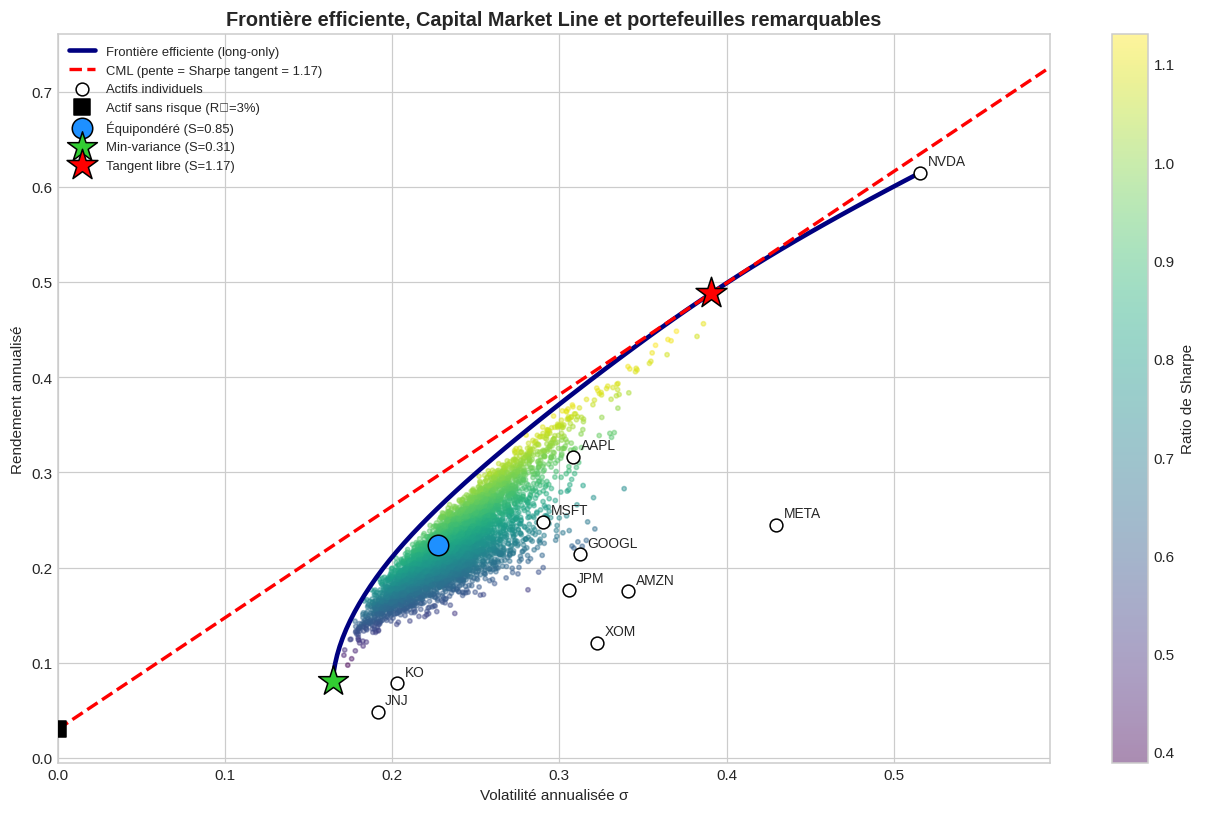

✅ Frontière calculée : 60 points | σ ∈ [16.45%, 51.60%]


In [ ]:
# ============================================================
# 🌐 FRONTIÈRE EFFICIENTE (optimisation exacte) + CML
# ============================================================
def efficient_frontier(mu, Sigma, max_weight=1.0, n_points=60):
    '''Frontière efficiente long-only : pour chaque rendement cible, minimise la variance.'''
    w_mv   = min_variance_weights(Sigma, max_weight)
    r_low  = float(w_mv @ mu)
    lp     = linprog(-mu, A_eq=np.ones((1, N_ASSETS)), b_eq=[1.0], bounds=[(0, max_weight)] * N_ASSETS)
    r_high = float(-lp.fun) - 1e-6                                   # rendement maximal atteignable
    rows = []
    for target in np.linspace(r_low, r_high, n_points):
        res = minimize(lambda w: w @ Sigma @ w, w_mv, method="SLSQP",
                       bounds=[(0, max_weight)] * N_ASSETS,
                       constraints=[{"type": "eq", "fun": lambda w: np.sum(w) - 1.0},
                                    {"type": "eq", "fun": lambda w, t=target: w @ mu - t}],
                       options={"maxiter": 500, "ftol": 1e-12})
        if res.success:
            rows.append((np.sqrt(res.fun), target))
    return pd.DataFrame(rows, columns=["vol", "ret"])

ef_free = efficient_frontier(mu_vec, Sigma_mat)

# Nuage de portefeuilles aléatoires (distribution de Dirichlet : somme à 1 et poids >= 0)
rng = np.random.default_rng(SEED)
W_rand = rng.dirichlet(np.ones(N_ASSETS), size=5000)
rand_ret = W_rand @ mu_vec
rand_vol = np.sqrt(np.einsum("ij,jk,ik->i", W_rand, Sigma_mat, W_rand))
rand_shp = (rand_ret - R0) / rand_vol

r_eq, v_eq, s_eq = portfolio_stats(w_eq)
r_min, v_min, s_min = portfolio_stats(w_min)

fig, ax = plt.subplots(figsize=(12, 7.5))
sc = ax.scatter(rand_vol, rand_ret, c=rand_shp, cmap="viridis", s=8, alpha=0.45)
plt.colorbar(sc, ax=ax, label="Ratio de Sharpe")
ax.plot(ef_free["vol"], ef_free["ret"], color="navy", lw=3, label="Frontière efficiente (long-only)")

sig_grid = np.linspace(0, ef_free["vol"].max() * 1.15, 100)
ax.plot(sig_grid, R0 + s_tan * sig_grid, "r--", lw=2.2, label=f"CML (pente = Sharpe tangent = {s_tan:.2f})")

ax.scatter(sigma_ann, mu_ann, c="white", edgecolors="black", s=70, zorder=8, label="Actifs individuels")
for t in TICKERS:
    ax.annotate(t, (sigma_ann[t], mu_ann[t]), xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.scatter(0, R0, c="black", marker="s", s=120, zorder=10, label=f"Actif sans risque (R⁰={R0:.0%})")
ax.scatter(v_eq,  r_eq,  c="dodgerblue", s=180, edgecolors="black", zorder=10, label=f"Équipondéré (S={s_eq:.2f})")
ax.scatter(v_min, r_min, c="limegreen", marker="*", s=420, edgecolors="black", zorder=10, label=f"Min-variance (S={s_min:.2f})")
ax.scatter(v_tan, r_tan, c="red", marker="*", s=450, edgecolors="black", zorder=10, label=f"Tangent libre (S={s_tan:.2f})")
ax.set_xlabel("Volatilité annualisée σ"); ax.set_ylabel("Rendement annualisé")
ax.set_title("Frontière efficiente, Capital Market Line et portefeuilles remarquables")
ax.legend(loc="upper left", fontsize=8.5); ax.set_xlim(0, sig_grid.max())
plt.tight_layout(); plt.show()

print(f"✅ Frontière calculée : {len(ef_free)} points | σ ∈ [{ef_free['vol'].min():.2%}, {ef_free['vol'].max():.2%}]")

### 🧠 Interprétation

- Les **5 000 portefeuilles aléatoires** forment un nuage entièrement situé **à droite/en dessous** de la frontière efficiente : aucun d'eux ne la domine, ce qui valide numériquement la frontière calculée par optimisation.
- Le **portefeuille équipondéré** se situe **à l'intérieur** de la frontière : il est *sous-optimal* au sens de Markowitz, mais il ne requiert aucune estimation — ce qui en fait un **benchmark redoutable** en pratique (DeMiguel, Garlappi & Uppal, 2009).
- Le **min-variance** est le point le plus à gauche de la frontière ; le **tangent libre** est le point de tangence avec la **CML**. Tous les portefeuilles situés sur la CML dominent la frontière risquée : combiner le tangent avec du cash permet d'ajuster le niveau de risque sans changer la composition risquée.
- La frontière est **tronquée à droite** par la contrainte *long-only* : son extrémité correspond au **titre le plus rentable** de l'échantillon (NVDA). Autrement dit, **la partie haute de la frontière n'est qu'un pari concentré sur un seul actif**.
- ⚠️ La frontière est calculée **avec les paramètres estimés** $(\hat\mu,\hat\Sigma)$ : c'est une frontière *estimée*, pas la vraie. Son incertitude est quantifiée à l'étape suivante.

## 🔬 Étape 2.4 — Diagnostic de l'*Error Maximization* (Michaud, 1989)

**🎯 Objectif.** Démontrer **empiriquement** — et non seulement affirmer — que la concentration du tangent libre est un **artefact d'estimation**. Deux preuves complémentaires :

1. **Précision statistique des rendements espérés** : les écarts de $\mu$ entre actifs sont-ils significatifs ?
2. **Instabilité par rééchantillonnage (bootstrap)** : si l'on perturbe légèrement les données, l'allocation « optimale » change-t-elle beaucoup ?

### 📐 Cadre théorique

**Erreur-type du rendement espérée annualisé** (rendements i.i.d.) :
$$\text{SE}(\hat\mu_i)=\frac{\sigma_i}{\sqrt{Y}}\quad(Y=\text{nombre d'années d'historique})\qquad\qquad t_i=\frac{\hat\mu_i}{\text{SE}(\hat\mu_i)}$$
Avec $\sigma_i\approx 30$–$50\,\%$ et $Y\approx 6$ ans, $\text{SE}(\hat\mu_i)$ atteint **12 à 20 points de pourcentage** : la précision sur $\mu$ est très faible.

**Error Maximization** (Michaud, 1989) : l'optimiseur moyenne-variance **sur-pondère les actifs dont le rendement espérée est surestimé** (erreur positive) et sous-pondère ceux où il est sous-estimé — il *maximise* littéralement l'erreur d'estimation.

**Bootstrap** : on tire $T$ jours **avec remise** dans l'échantillon, on ré-estime $(\hat\mu^{(b)},\hat\Sigma^{(b)})$ et on recalcule $w_{tan}^{(b)}$, pour $b=1,\dots,B$. La **dispersion** des $w^{(b)}$ mesure l'instabilité de l'allocation.

(1) PRÉCISION STATISTIQUE DES RENDEMENTS ESPÉRÉS  (historique = 6.0 ans)
        μ annualisé (%)  Erreur-type SE (pts %)  t-stat       IC 95% (%)
Ticker                                                                  
AAPL              31.62                   12.60    2.51  [  6.9 ;  56.3]
MSFT              24.83                   11.86    2.09  [  1.6 ;  48.1]
NVDA              61.50                   21.09    2.92  [ 20.2 ; 102.8]
AMZN              17.49                   13.95    1.25  [ -9.8 ;  44.8]
GOOGL             21.40                   12.76    1.68  [ -3.6 ;  46.4]
META              24.48                   17.55    1.40  [ -9.9 ;  58.9]
JPM               17.64                   12.50    1.41  [ -6.9 ;  42.1]
JNJ                4.85                    7.82    0.62  [-10.5 ;  20.2]
XOM               12.08                   13.18    0.92  [-13.8 ;  37.9]
KO                 7.83                    8.30    0.94  [ -8.4 ;  24.1]

⏳ Bootstrap (200 rééchantillons) du portefeuille t

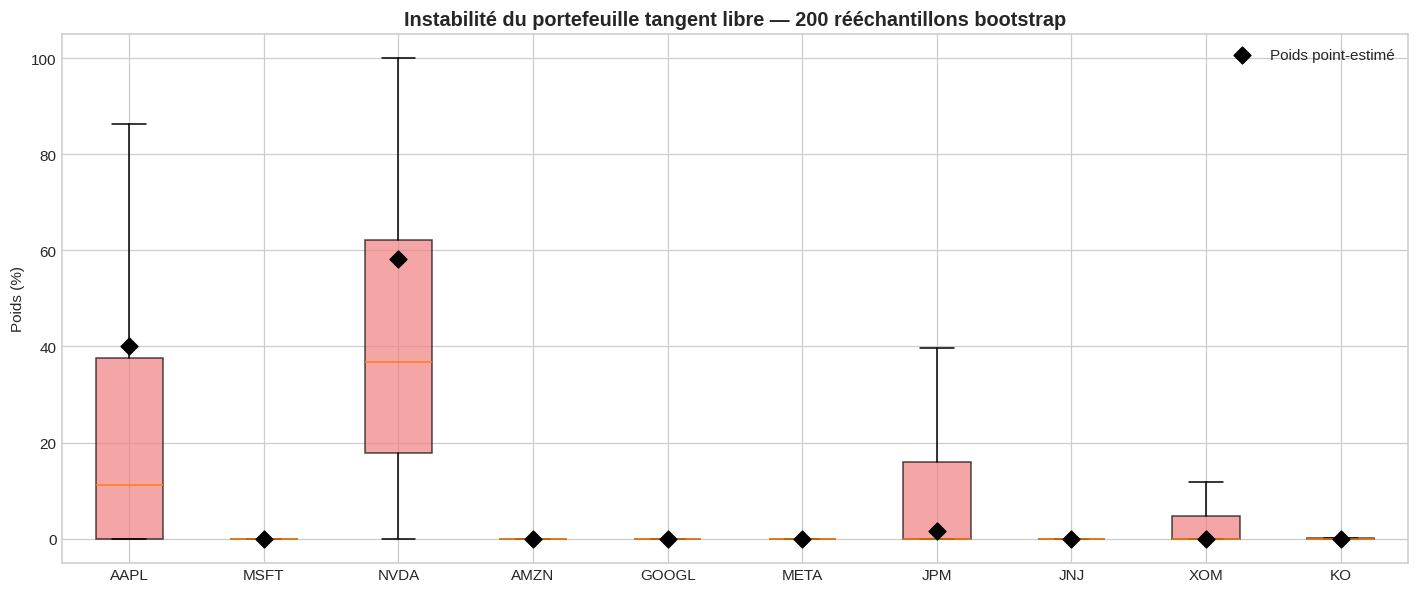

In [ ]:
# ============================================================
# 🔬 DIAGNOSTIC DE L'ERROR MAXIMIZATION
# ============================================================
years = len(ret_assets) / TRADING_DAYS
mu_diag = pd.DataFrame({
    "μ annualisé (%)": mu_ann * 100,
    "Erreur-type SE (pts %)": sigma_ann / np.sqrt(years) * 100,
})
mu_diag["t-stat"] = mu_diag["μ annualisé (%)"] / mu_diag["Erreur-type SE (pts %)"]
mu_diag["IC 95% (%)"] = [f"[{m - 1.96 * s:5.1f} ; {m + 1.96 * s:5.1f}]" for m, s in
                          zip(mu_diag["μ annualisé (%)"], mu_diag["Erreur-type SE (pts %)"])]

print("=" * 80)
print(f"(1) PRÉCISION STATISTIQUE DES RENDEMENTS ESPÉRÉS  (historique = {years:.1f} ans)")
print("=" * 80)
print(mu_diag.round(2).to_string())

# (2) Bootstrap i.i.d. de l'allocation tangente
def bootstrap_tangent_weights(max_weight=1.0, n_boot=200, seed=SEED):
    '''Rééchantillonne les jours avec remise, ré-optimise le tangent à chaque tirage.'''
    rng_b = np.random.default_rng(seed)             # même graine → mêmes rééchantillons (comparaison appariée)
    X, T  = ret_assets.values, len(ret_assets)
    out   = np.zeros((n_boot, N_ASSETS))
    for b in range(n_boot):
        Xb = X[rng_b.integers(0, T, T)]
        out[b] = max_sharpe_weights(Xb.mean(axis=0) * TRADING_DAYS,
                                    np.cov(Xb, rowvar=False) * TRADING_DAYS, max_weight)
    return out

print("\n⏳ Bootstrap (200 rééchantillons) du portefeuille tangent libre...")
boot_free = bootstrap_tangent_weights(max_weight=1.0)
print("✅ Terminé")

boot_stats = pd.DataFrame({
    "Poids point-estimé (%)": w_tan * 100,
    "Poids moyen bootstrap (%)": boot_free.mean(axis=0) * 100,
    "Écart-type bootstrap (pts)": boot_free.std(axis=0) * 100,
    "P5 (%)": np.percentile(boot_free, 5, axis=0) * 100,
    "P95 (%)": np.percentile(boot_free, 95, axis=0) * 100,
}, index=TICKERS)
neff_boot_free = np.array([effective_n(w) for w in boot_free])

print("\n" + "=" * 80)
print("(2) INSTABILITÉ DE L'ALLOCATION TANGENTE LIBRE (bootstrap)")
print("=" * 80)
print(boot_stats.round(1).to_string())
print(f"\nN effectif — moyenne bootstrap : {neff_boot_free.mean():.2f} | min : {neff_boot_free.min():.2f} | max : {neff_boot_free.max():.2f}")
print(f"Part des rééchantillons où le poids maximal dépasse 50% : {(boot_free.max(axis=1) > 0.5).mean():.0%}")

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.boxplot(boot_free * 100, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor="lightcoral", alpha=0.7))
ax.set_xticklabels(TICKERS)
ax.scatter(range(1, N_ASSETS + 1), w_tan * 100, c="black", marker="D", s=60, zorder=5, label="Poids point-estimé")
ax.set_ylabel("Poids (%)"); ax.set_title("Instabilité du portefeuille tangent libre — 200 rééchantillons bootstrap")
ax.legend(); plt.tight_layout(); plt.show()

### 🧠 Interprétation

- **Précision de $\mu$ :** les **intervalles de confiance à 95 %** des rendements espérés sont **très larges** et se **chevauchent largement** d'un actif à l'autre. L'écart de rendement entre NVDA et les autres titres est **du même ordre de grandeur que l'erreur d'estimation elle-même** : l'optimiseur traite comme un signal certain une différence statistiquement fragile.
- **Instabilité :** le bootstrap montre que l'allocation tangente libre est **très dispersée** — les poids de NVDA et d'AAPL fluctuent fortement d'un rééchantillon à l'autre et d'autres actifs peuvent apparaître ou disparaître. Une allocation qui se modifie radicalement pour de **minimes perturbations des données** n'est pas fiable.
- **Verdict :** la concentration à 98 % sur deux titres est bien une manifestation de l'**Error Maximization** : l'optimiseur amplifie l'erreur d'estimation de $\hat\mu$ via $\Sigma^{-1}$. Le portefeuille tangent libre n'est donc **pas** un portefeuille optimal, mais un **portefeuille optimal pour un échantillon particulier**.
- ➡️ **Remède étudié à l'étape suivante :** imposer une **borne supérieure de 25 % par titre**, qui agit comme un **régulariseur** (shrinkage implicite vers l'équipondération).

## 🛡️ Étape 2.5 — Correction par contrainte de poids maximal (25 %)

**🎯 Objectif.** Corriger l'*Error Maximization* en imposant $w_i\le 25\,\%$. L'idée financière est celle de la **gestion prudente** : aucun titre ne doit pouvoir, à lui seul, déterminer le sort du portefeuille. On mesure ensuite **le coût** (perte de Sharpe in-sample) et **le bénéfice** (stabilité) de cette correction.

### 📐 Cadre théorique

$$w_{tan}^{(c)}=\arg\max_{w}\;\frac{w^{\top}\mu-R^0}{\sqrt{w^{\top}\Sigma w}}\quad\text{s.c.}\quad \mathbf 1^{\top}w=1,\quad 0\le w_i\le \bar w=25\%$$

**Pourquoi cela fonctionne** (Jagannathan & Ma, 2003) : imposer des contraintes de poids revient, **mathématiquement**, à **rétrécir (shrink)** la matrice de covariance estimée vers une structure plus stable — *même si la contrainte est « fausse » en population, elle réduit l'erreur d'estimation*. C'est l'arbitrage **biais–variance** appliqué à l'allocation d'actifs.

Les contraintes **actives** (poids exactement égaux à $\bar w$) correspondent aux multiplicateurs de Lagrange strictement positifs : ce sont les actifs que l'optimiseur « voudrait » encore plus pondérer.

PORTEFEUILLE TANGENT CONTRAINT (w_i ≤ 25%)
  NVDA   :  25.00%  ← contrainte ACTIVE
  AAPL   :  25.00%  ← contrainte ACTIVE
  MSFT   :  23.79%
  JPM    :  16.04%
  KO     :   5.33%
  XOM    :   4.84%

  Rendement annuel : 33.02%
  Volatilité       : 27.94%
  Sharpe           : 1.074

COMPARAISON DES 4 PORTEFEUILLES (in-sample)
                   Rendement  Volatilité  Sharpe  N effectif  Poids max
Équipondéré           0.2237      0.2276  0.8511     10.0000     0.1000
Min-variance          0.0809      0.1645  0.3096      2.8926     0.4752
Tangent libre         0.4880      0.3908  1.1722      1.9985     0.5830
Tangent (cap 25%)     0.3302      0.2794  1.0742      4.7059     0.2500

💰 Coût de la robustesse : ΔSharpe = -0.098 (-8.4%) | ΔRendement = -15.79% | ΔVol = -11.13%

⏳ Bootstrap du portefeuille contraint...
✅ Terminé

ÉCART-TYPE BOOTSTRAP DES POIDS (points de %)
       Libre  Cap 25%
AAPL    24.1     10.0
MSFT    10.8     10.5
NVDA    29.1      5.7
AMZN     6.3      7.7
GOOGL    9.5

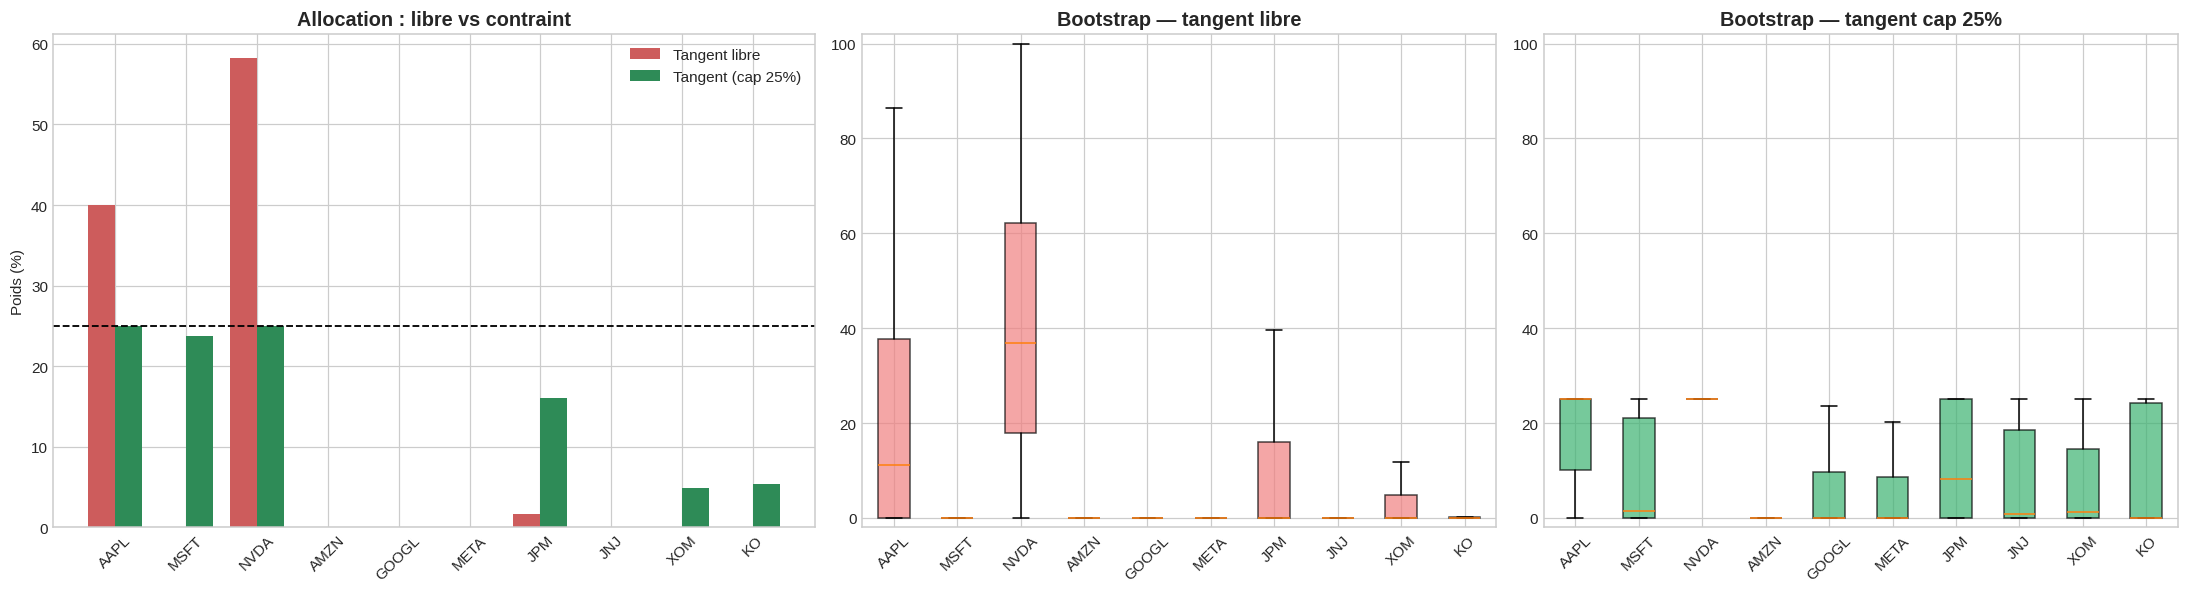

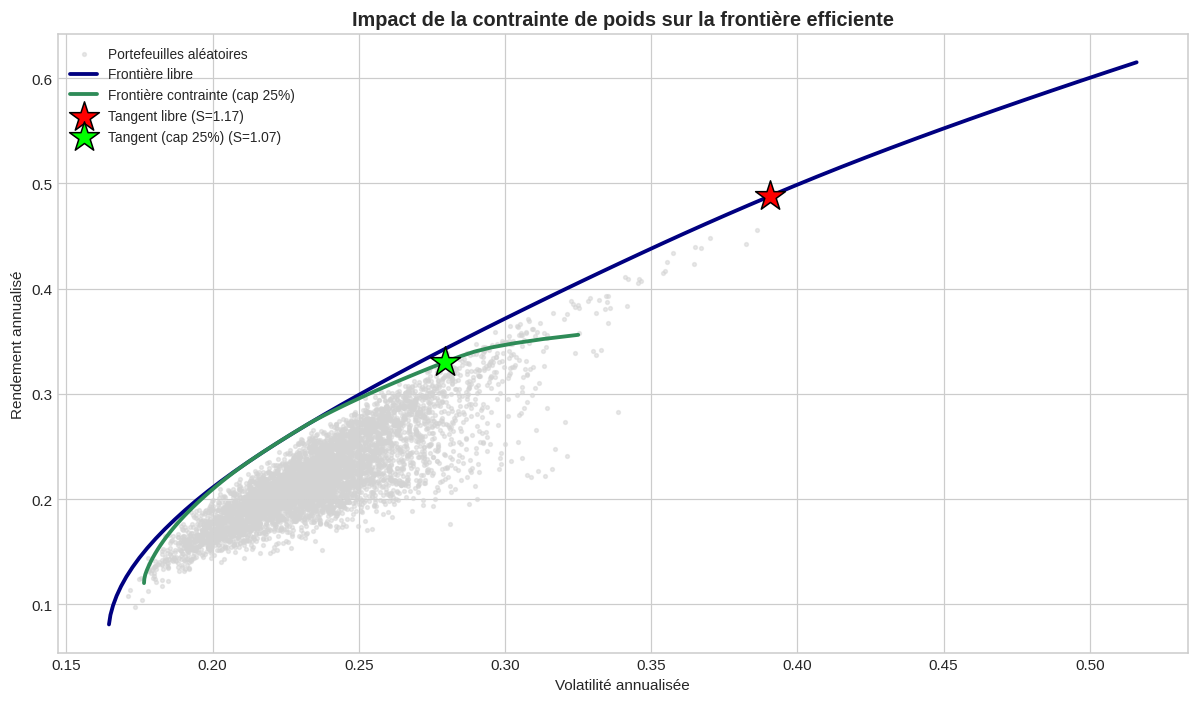

In [ ]:
# ============================================================
# 🛡️ PORTEFEUILLE TANGENT CONTRAINT (w_i <= 25%) + COMPARAISON
# ============================================================
w_tan_c = max_sharpe_weights(mu_vec, Sigma_mat, max_weight=MAX_WEIGHT)
r_tan_c, v_tan_c, s_tan_c = portfolio_stats(w_tan_c)

print("=" * 60)
print(f"PORTEFEUILLE TANGENT CONTRAINT (w_i ≤ {MAX_WEIGHT:.0%})")
print("=" * 60)
for ticker, w in sorted(zip(TICKERS, w_tan_c), key=lambda x: -x[1]):
    if w > 0.005:
        flag = "  ← contrainte ACTIVE" if np.isclose(w, MAX_WEIGHT, atol=1e-4) else ""
        print(f"  {ticker:6s} : {w:7.2%}{flag}")
print(f"\n  Rendement annuel : {r_tan_c:.2%}")
print(f"  Volatilité       : {v_tan_c:.2%}")
print(f"  Sharpe           : {s_tan_c:.3f}")

# Tableau comparatif des 4 portefeuilles
PORTFOLIOS = {NAME_EW: w_eq, NAME_MV: w_min, NAME_TAN: w_tan, NAME_TAN_C: w_tan_c}
comp = pd.DataFrame([portfolio_stats(w) + (effective_n(w), w.max()) for w in PORTFOLIOS.values()],
                    columns=["Rendement", "Volatilité", "Sharpe", "N effectif", "Poids max"], index=PORTFOLIOS.keys())
print("\n" + "=" * 75); print("COMPARAISON DES 4 PORTEFEUILLES (in-sample)"); print("=" * 75)
print(comp.round(4).to_string())
print(f"\n💰 Coût de la robustesse : ΔSharpe = {s_tan_c - s_tan:+.3f} ({(s_tan_c / s_tan - 1):+.1%}) | ΔRendement = {r_tan_c - r_tan:+.2%} | ΔVol = {v_tan_c - v_tan:+.2%}")

# Bootstrap du portefeuille contraint (mêmes rééchantillons que le libre)
print("\n⏳ Bootstrap du portefeuille contraint...")
boot_con = bootstrap_tangent_weights(max_weight=MAX_WEIGHT)
neff_boot_con = np.array([effective_n(w) for w in boot_con])
print("✅ Terminé")
disp = pd.DataFrame({"Libre": boot_free.std(axis=0) * 100, f"Cap {MAX_WEIGHT:.0%}": boot_con.std(axis=0) * 100}, index=TICKERS)
print("\nÉCART-TYPE BOOTSTRAP DES POIDS (points de %)"); print(disp.round(1).to_string())
print(f"\nDispersion moyenne des poids : libre = {disp['Libre'].mean():.1f} pts | contraint = {disp.iloc[:, 1].mean():.1f} pts")
print(f"N effectif moyen (bootstrap) : libre = {neff_boot_free.mean():.2f} | contraint = {neff_boot_con.mean():.2f}")

# --- Visualisation 1 : poids + boxplots bootstrap ---
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={"width_ratios": [1.2, 1, 1]})
x = np.arange(N_ASSETS); bw = 0.38
axes[0].bar(x - bw / 2, w_tan * 100,   bw, label=NAME_TAN,   color="indianred")
axes[0].bar(x + bw / 2, w_tan_c * 100, bw, label=NAME_TAN_C, color="seagreen")
axes[0].axhline(MAX_WEIGHT * 100, color="black", ls="--", lw=1.2)
axes[0].set_xticks(x); axes[0].set_xticklabels(TICKERS, rotation=45)
axes[0].set_ylabel("Poids (%)"); axes[0].set_title("Allocation : libre vs contraint"); axes[0].legend()
for ax, data, title, color in [(axes[1], boot_free, "Bootstrap — tangent libre", "lightcoral"),
                               (axes[2], boot_con,  f"Bootstrap — tangent cap {MAX_WEIGHT:.0%}", "mediumseagreen")]:
    ax.boxplot(data * 100, showfliers=False, patch_artist=True, boxprops=dict(facecolor=color, alpha=0.7))
    ax.set_xticklabels(TICKERS)
    ax.set_ylim(-2, 102); ax.set_title(title); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

# --- Visualisation 2 : frontières libre vs contrainte ---
ef_con = efficient_frontier(mu_vec, Sigma_mat, max_weight=MAX_WEIGHT)
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.scatter(rand_vol, rand_ret, c="lightgrey", s=6, alpha=0.5, label="Portefeuilles aléatoires")
ax.plot(ef_free["vol"], ef_free["ret"], color="navy", lw=2.5, label="Frontière libre")
ax.plot(ef_con["vol"],  ef_con["ret"],  color="seagreen", lw=2.5, label=f"Frontière contrainte (cap {MAX_WEIGHT:.0%})")
ax.scatter(v_tan,   r_tan,   c="red",   marker="*", s=420, edgecolors="black", zorder=10, label=f"{NAME_TAN} (S={s_tan:.2f})")
ax.scatter(v_tan_c, r_tan_c, c="lime",  marker="*", s=420, edgecolors="black", zorder=10, label=f"{NAME_TAN_C} (S={s_tan_c:.2f})")
ax.set_xlabel("Volatilité annualisée"); ax.set_ylabel("Rendement annualisé")
ax.set_title("Impact de la contrainte de poids sur la frontière efficiente")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

### 🧠 Interprétation

- **NVDA et AAPL sont bloqués à 25 %** (contraintes actives) : l'optimiseur voudrait les surpondérer davantage, mais la borne l'en empêche. Les **50 % restants sont redistribués** sur d'autres titres, qui entrent enfin dans le portefeuille. Le **nombre effectif d'actifs** passe d'environ 2 à une valeur nettement plus élevée.
- **Coût de la correction :** le Sharpe in-sample **diminue** (ligne `Coût de la robustesse`). C'est attendu : on retire de la liberté à un optimiseur qui maximise le critère *sur l'échantillon*. Cette baisse est le **prix de l'assurance** contre l'erreur d'estimation, non une perte réelle.
- **Bénéfice :** le bootstrap montre une **dispersion des poids réduite** et un $N_{eff}$ moyen plus stable. Le portefeuille contraint est **structurellement moins sensible** aux fluctuations d'échantillon.
- **Frontière :** la frontière contrainte est **située sous** la frontière libre et **plus courte** (le rendement maximal atteignable est limité par la contrainte) : on échange un peu d'optimalité *apparente* contre de la robustesse.
- ✅ **Décision méthodologique :** le **portefeuille tangent contraint (cap 25 %)** devient le **portefeuille de référence** pour les Parties 3 et 4. Il est plus diversifié, plus stable et plus crédible économiquement que le tangent libre.

## ✅ Étape 2.6 — Validation hors échantillon (*out-of-sample*)

**🎯 Objectif.** Vérifier que la correction apporte bien un bénéfice **hors échantillon**, seule preuve valable en finance quantitative. On **estime** les poids sur une période d'apprentissage (2019-2022), puis on **évalue** leur performance sur une période de test jamais vue (2023-2024).

### 📐 Cadre théorique

On découpe l'historique en deux périodes disjointes à la date $\tau$ :

$$\underbrace{(\hat\mu_{train},\hat\Sigma_{train})\;\longrightarrow\;\hat w}_{\text{apprentissage }[t_0,\tau)}\qquad\qquad \underbrace{S_{test}(\hat w)}_{\text{évaluation }[\tau,T]}$$

**Dégradation du Sharpe** $=S_{train}-S_{test}$ : mesure du **surajustement**. Un bon estimateur d'allocation doit avoir une dégradation plus faible.

*Limite :* un seul découpage donne une puissance statistique faible ; un **walk-forward** (réestimation glissante) serait préférable — voir extensions (Partie 5).

Apprentissage : 2019-01-03 → 2022-12-30 (1007 j) | Test : 2023-01-03 → 2024-12-31 (502 j)

POIDS ESTIMÉS SUR LA PÉRIODE D'APPRENTISSAGE (%)
       Équipondéré  Min-variance  Tangent libre  Tangent (cap 25%)
AAPL          10.0           0.0           75.2               25.0
MSFT          10.0           0.0            0.0               12.6
NVDA          10.0           0.0           10.8               22.2
AMZN          10.0          12.4            0.0                0.0
GOOGL         10.0           0.0            0.0                0.0
META          10.0           0.0            0.0                0.0
JPM           10.0           0.0            0.0                0.0
JNJ           10.0          54.4            1.2               23.9
XOM           10.0           5.6           12.8               16.3
KO            10.0          27.6            0.0                0.0

PERFORMANCE IN-SAMPLE vs OUT-OF-SAMPLE
                   Sharpe train  Sharpe test  Dégradation  Rend. test  Vol test  Ma

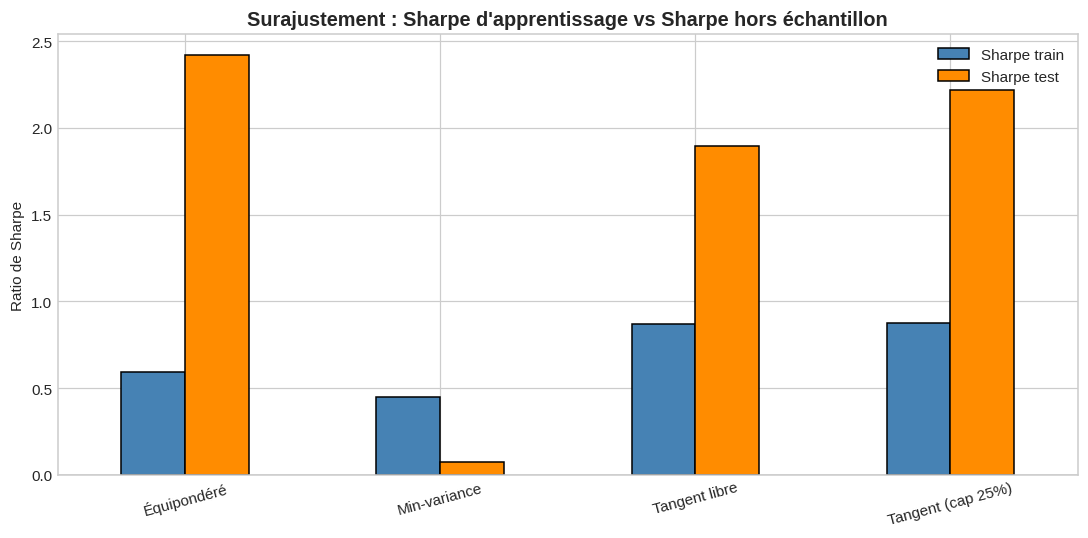

In [ ]:
# ============================================================
# ✅ VALIDATION OUT-OF-SAMPLE : apprentissage 2019-2022 → test 2023-2024
# ============================================================
SPLIT_DATE = pd.Timestamp("2023-01-01")
train, test = ret_assets[ret_assets.index < SPLIT_DATE], ret_assets[ret_assets.index >= SPLIT_DATE]

def basic_performance(r):
    '''Rendement annualisé, volatilité, Sharpe, max drawdown d'une série de log-rendements journaliers.'''
    ann_ret = r.mean() * TRADING_DAYS
    ann_vol = r.std() * np.sqrt(TRADING_DAYS)
    cum = np.exp(r.cumsum())
    mdd = (cum / cum.cummax() - 1).min()
    return pd.Series({"Rendement": ann_ret, "Volatilité": ann_vol, "Sharpe": (ann_ret - R0) / ann_vol, "Max DD": mdd})

mu_tr  = train.mean().values * TRADING_DAYS
Sig_tr = train.cov().values  * TRADING_DAYS
weights_oos = {
    NAME_EW:    w_eq,
    NAME_MV:    min_variance_weights(Sig_tr),
    NAME_TAN:   max_sharpe_weights(mu_tr, Sig_tr),
    NAME_TAN_C: max_sharpe_weights(mu_tr, Sig_tr, max_weight=MAX_WEIGHT),
}

print(f"Apprentissage : {train.index[0].date()} → {train.index[-1].date()} ({len(train)} j) | Test : {test.index[0].date()} → {test.index[-1].date()} ({len(test)} j)\n")
print("POIDS ESTIMÉS SUR LA PÉRIODE D'APPRENTISSAGE (%)")
print((pd.DataFrame(weights_oos, index=TICKERS) * 100).round(1).to_string())

rows = {}
for name, w in weights_oos.items():
    perf_train = basic_performance(portfolio_log_returns(w, train))
    perf_test  = basic_performance(portfolio_log_returns(w, test))
    rows[name] = {"Sharpe train": perf_train["Sharpe"], "Sharpe test": perf_test["Sharpe"],
                  "Dégradation": perf_train["Sharpe"] - perf_test["Sharpe"],
                  "Rend. test": perf_test["Rendement"], "Vol test": perf_test["Volatilité"], "Max DD test": perf_test["Max DD"]}
oos = pd.DataFrame(rows).T

print("\n" + "=" * 90); print("PERFORMANCE IN-SAMPLE vs OUT-OF-SAMPLE"); print("=" * 90)
print(oos.round(3).to_string())

best_oos = oos["Sharpe test"].idxmax()
less_degr = oos["Dégradation"].idxmin()
print(f"\n📝 Lecture automatique : meilleur Sharpe hors échantillon = « {best_oos} » | plus faible dégradation = « {less_degr} »")
print(f"📝 Tangent libre : dégradation = {oos.loc[NAME_TAN, 'Dégradation']:+.3f} | Tangent contraint : dégradation = {oos.loc[NAME_TAN_C, 'Dégradation']:+.3f}")

fig, ax = plt.subplots(figsize=(10, 5))
oos[["Sharpe train", "Sharpe test"]].plot.bar(ax=ax, color=["steelblue", "darkorange"], edgecolor="black")
ax.axhline(0, color="black", lw=0.8); ax.set_ylabel("Ratio de Sharpe"); ax.tick_params(axis="x", rotation=15)
ax.set_title("Surajustement : Sharpe d'apprentissage vs Sharpe hors échantillon")
plt.tight_layout(); plt.show()

### 🧠 Interprétation

- **Lecture du tableau :** la colonne `Dégradation` mesure l'écart entre le Sharpe obtenu **sur les données qui ont servi à construire les poids** et celui obtenu sur des **données nouvelles**. Une dégradation élevée est le symptôme direct du **surajustement** (*overfitting*).
- **Ce qu'il faut regarder :** l'enjeu n'est **pas** de savoir quel portefeuille a le meilleur rendement sur 2023-2024 (période dominée par le boom de l'IA, qui avantage mécaniquement les portefeuilles fortement exposés à la technologie), mais **si la correction réduit l'écart entre performance estimée et performance réalisée**. Si la dégradation du tangent contraint est plus faible que celle du tangent libre, c'est la **signature empirique** de la correction de l'Error Maximization.
- **Prudence :** avec un seul découpage temporel, la puissance statistique est limitée et le résultat dépend du régime de marché de la période de test. Cette validation est un **indice**, pas une preuve définitive : un *walk-forward* sur plusieurs fenêtres serait nécessaire (voir Partie 5).
- ✅ **Bilan de la Partie 2 :** le portefeuille tangent de Markowitz non contraint est **numériquement optimal mais statistiquement fragile** ; la contrainte à 25 % est une correction **simple, interprétable et standard en gestion** (limites réglementaires de concentration type UCITS 5/10/40). Nous retenons le **portefeuille tangent contraint** pour la mesure du risque.

# 🛡️ PARTIE 3 — Mesure du Risque : VaR, CVaR, Backtesting
*VaR (3 méthodes) · CVaR · Backtesting Kupiec & Christoffersen*

**Question de la partie :** quelle mesure de risque est **fiable** lorsque les rendements ont des queues épaisses ?

### 🔗 Le fil logique de cette partie

> **① Jarque-Bera rejette la normalité** (Partie 1) → **② la VaR paramétrique gaussienne repose sur une loi fausse, elle est donc dangereuse** → **③ d'où l'utilité (a) du CVaR**, qui mesure la *gravité* des pertes au-delà de la VaR, **et (b) de la loi de Student-t**, qui modélise explicitement les queues épaisses → **④ le backtesting** (Kupiec, Christoffersen) *tranche* empiriquement entre les méthodes.

**Portefeuille analysé :** le **tangent contraint (cap 25 %)**, retenu à l'issue de la Partie 2 (changeable via la variable `W_RISK_NAME`).

> 💡 **Note de reproductibilité.** La mesure du risque est ici appliquée au portefeuille **corrigé** (contraint) car il est cohérent de mesurer le risque du portefeuille que l'on recommanderait réellement. Pour reproduire une analyse sur le **tangent libre**, il suffit de remplacer `W_RISK_NAME = NAME_TAN_C` par `W_RISK_NAME = NAME_TAN` dans la cellule suivante. Les rendements du portefeuille sont calculés par agrégation **exacte** des rendements simples quotidiens (poids constants), ce qui peut induire de légers écarts décimaux avec une approximation $\sum_i w_i r_i$.

## 🔍 Étape 3.1 — Distribution du portefeuille : la non-normalité survit-elle à la diversification ?

**🎯 Objectif.** Avant de calculer une VaR, il faut savoir **quelle loi** décrit les rendements du portefeuille. On teste si la diversification (agrégation de 10 titres) **ramène** la distribution vers la normalité, et on compare l'ajustement d'une loi **normale** à celui d'une loi de **Student-t**.

### 📐 Cadre théorique

**Loi de Student-t** à $\nu$ degrés de liberté, paramètres de position $m$ et d'échelle $s$ :
$$f(r)=\frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}{s\sqrt{\nu\pi}\,\Gamma\!\left(\frac\nu2\right)}\left(1+\frac{1}{\nu}\Big(\frac{r-m}{s}\Big)^{2}\right)^{-\frac{\nu+1}{2}}$$
Plus $\nu$ est petit, plus les queues sont épaisses ; $\nu\to\infty$ redonne la loi normale. La kurtosis (en excès) vaut $\frac{6}{\nu-4}$ pour $\nu>4$.

**Critère d'information d'Akaike** (plus bas = meilleur compromis ajustement/parcimonie) :
$$AIC=2k-2\ln\hat L$$
avec $k=2$ pour la normale et $k=3$ pour la Student-t.

PORTEFEUILLE ANALYSÉ : Tangent (cap 25%)
Observations      : 1509
Rendement moyen   : 0.1419% / jour   | Volatilité : 1.7621% / jour
Skewness          : -0.491
Kurtosis          : 11.842  (normale = 3)
Jarque-Bera       : 4976.2  (p-value = 0.00e+00)  → normalité REJETÉE ❌

                     Log-vraisemblance  Paramètres k     AIC
Normale                         3953.7             2 -7903.3
Student-t (ν̂=3.49)             4106.7             3 -8207.4

📝 Lecture automatique : meilleur modèle selon l'AIC = Student-t (ν̂=3.49) | ΔAIC = 304.0


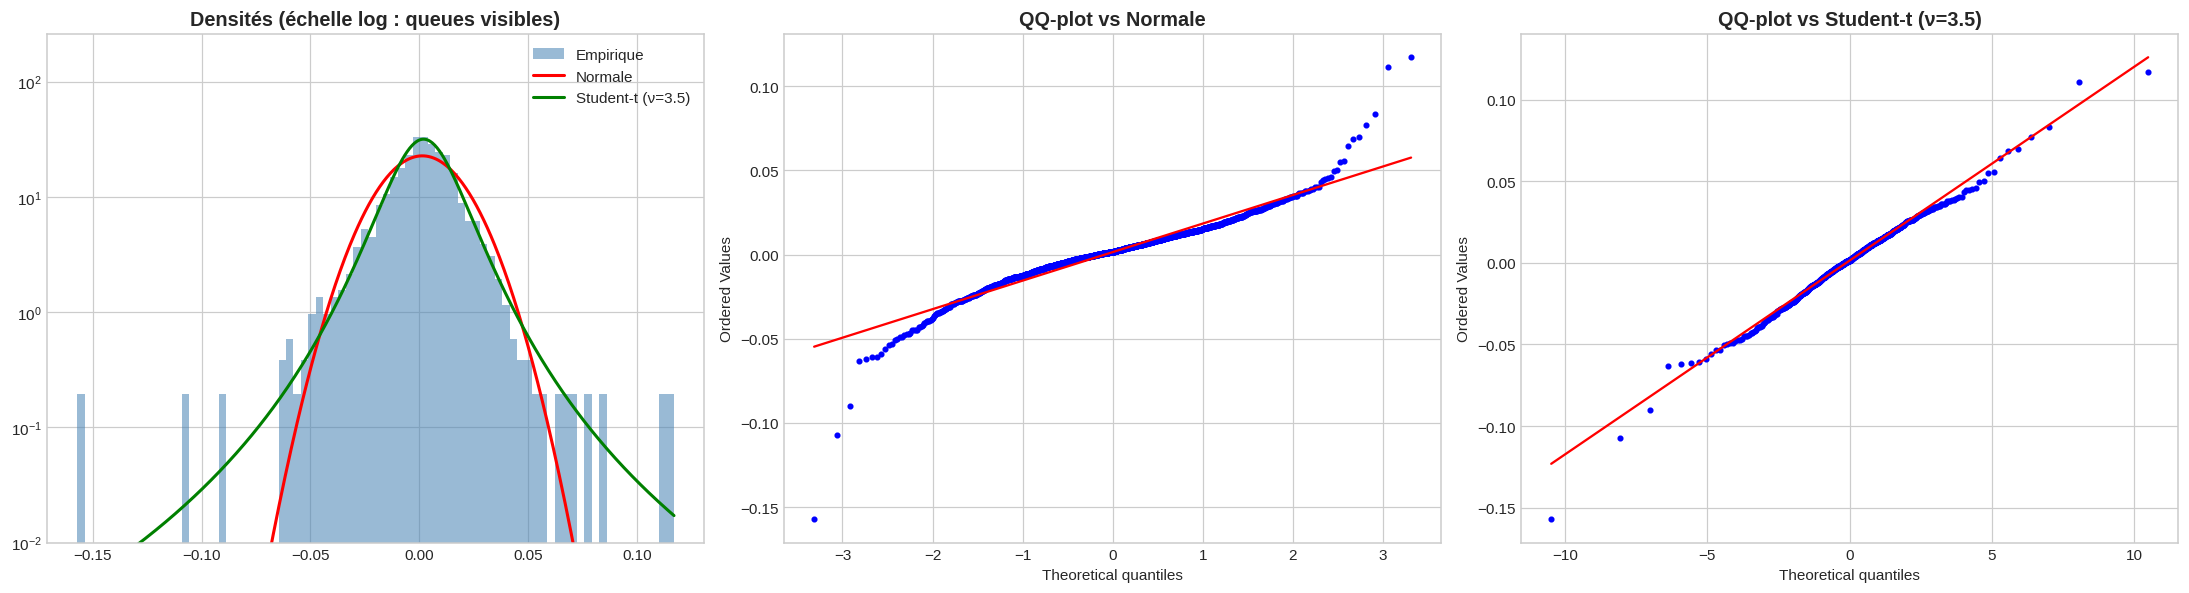

In [ ]:
# ============================================================
# 🔍 RENDEMENTS DU PORTEFEUILLE & AJUSTEMENT NORMALE vs STUDENT-t
# ============================================================
W_RISK_NAME = NAME_TAN_C                      # ← portefeuille analysé (cf. note de reproductibilité)
w_risk      = PORTFOLIOS[W_RISK_NAME]

port_ret = portfolio_log_returns(w_risk)      # log-rendements journaliers exacts
port_ret.name = W_RISK_NAME
r = port_ret.values

jb_p, p_jb = stats.jarque_bera(r)
print("=" * 65); print(f"PORTEFEUILLE ANALYSÉ : {W_RISK_NAME}"); print("=" * 65)
print(f"Observations      : {len(r)}")
print(f"Rendement moyen   : {r.mean():.4%} / jour   | Volatilité : {r.std(ddof=1):.4%} / jour")
print(f"Skewness          : {stats.skew(r):.3f}")
print(f"Kurtosis          : {stats.kurtosis(r, fisher=False):.3f}  (normale = 3)")
print(f"Jarque-Bera       : {jb_p:.1f}  (p-value = {p_jb:.2e})  → normalité {'REJETÉE ❌' if p_jb < 0.05 else 'non rejetée ✅'}")

# Ajustement par maximum de vraisemblance
mu_n, sig_n       = stats.norm.fit(r)
nu_t, loc_t, sc_t = stats.t.fit(r)
ll_n = stats.norm.logpdf(r, mu_n, sig_n).sum()
ll_t = stats.t.logpdf(r, nu_t, loc_t, sc_t).sum()
fit_tab = pd.DataFrame({"Log-vraisemblance": [ll_n, ll_t], "Paramètres k": [2, 3],
                        "AIC": [4 - 2 * ll_n, 6 - 2 * ll_t]}, index=["Normale", f"Student-t (ν̂={nu_t:.2f})"])
print("\n" + fit_tab.round(1).to_string())
print(f"\n📝 Lecture automatique : meilleur modèle selon l'AIC = {fit_tab['AIC'].idxmin()} | ΔAIC = {fit_tab['AIC'].max() - fit_tab['AIC'].min():.1f}")

# Graphiques
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
grid = np.linspace(r.min(), r.max(), 500)
axes[0].hist(r, bins=80, density=True, alpha=0.55, color="steelblue", label="Empirique")
axes[0].plot(grid, stats.norm.pdf(grid, mu_n, sig_n), "r-", lw=2, label="Normale")
axes[0].plot(grid, stats.t.pdf(grid, nu_t, loc_t, sc_t), "g-", lw=2, label=f"Student-t (ν={nu_t:.1f})")
axes[0].set_yscale("log"); axes[0].set_ylim(1e-2, None)
axes[0].set_title("Densités (échelle log : queues visibles)"); axes[0].legend()
stats.probplot(r, dist="norm", plot=axes[1]); axes[1].set_title("QQ-plot vs Normale")
stats.probplot(r, dist=stats.t, sparams=(nu_t,), plot=axes[2]); axes[2].set_title(f"QQ-plot vs Student-t (ν={nu_t:.1f})")
for ax in axes[1:]: ax.get_lines()[0].set_markersize(3)
plt.tight_layout(); plt.show()

### 🧠 Interprétation

- **La diversification ne suffit pas à restaurer la normalité.** Même après agrégation de 10 titres, le test de Jarque-Bera **rejette** la normalité du portefeuille, avec une kurtosis nettement supérieure à 3 : les **événements extrêmes de marché sont communs à tous les actifs** (corrélations qui montent en crise), la diversification ne les « moyenne » donc pas.
- **L'échelle logarithmique** du premier graphique révèle l'écart : dans les **queues**, la densité empirique est **bien au-dessus** de la gaussienne, alors que la Student-t la suit de près.
- **QQ-plots :** la normale s'écarte nettement de la diagonale aux extrémités (courbe en « S »), la Student-t **la longe beaucoup mieux**. Le **critère AIC** confirme quantitativement la supériorité de la Student-t, avec un nombre de degrés de liberté $\hat\nu$ faible (de l'ordre de quelques unités), signe de queues très épaisses.
- ➡️ **Conclusion de l'étape :** modéliser les rendements du portefeuille par une loi normale est **statistiquement injustifié**. Cela prépare l'argument central : *la VaR paramétrique gaussienne repose sur une hypothèse rejetée par les données.*

## 📏 Étape 3.2 — VaR et CVaR : trois méthodes, deux niveaux de confiance

**🎯 Objectif.** Quantifier la perte maximale « normale » (VaR) et la **perte moyenne dans les cas extrêmes** (CVaR) par trois approches aux hypothèses opposées :

| Méthode | Hypothèse sur la loi | Force | Faiblesse |
|---|---|---|---|
| **Historique** | Aucune (quantile empirique) | Capture les queues réelles | Dépend de l'échantillon |
| **Paramétrique** | Normale | Formule fermée, rapide | **Queues trop fines** |
| **Monte Carlo (Student-t)** | Student-t calibrée par MV | Queues épaisses, flexible | Risque de modèle, bruit sur $\nu$ |

On calcule à **95 %** (usage interne) et à **99 %** (usage réglementaire Bâle), car c'est à 99 % que les différences entre méthodes se révèlent.

### 📐 Cadre théorique

On note $L=-R$ la perte. Pour un niveau de confiance $\alpha$ :

$$\text{VaR}_\alpha=\inf\{\ell:\ \mathbb P(L>\ell)\le 1-\alpha\}=-Q_{1-\alpha}(R)\qquad\qquad \text{CVaR}_\alpha=\mathbb E\big[L\mid L\ge \text{VaR}_\alpha\big]$$

**1. Historique :** $\widehat{\text{VaR}}_\alpha=-Q^{emp}_{1-\alpha}(R)$ ; $\widehat{\text{CVaR}}_\alpha=-\frac{1}{|\mathcal T|}\sum_{r_t\le -\widehat{\text{VaR}}_\alpha}r_t$.

**2. Paramétrique (normale), $z_{1-\alpha}=\Phi^{-1}(1-\alpha)$ :**
$$\text{VaR}_\alpha=-(\mu+z_{1-\alpha}\,\sigma)\qquad\text{CVaR}_\alpha=-\mu+\sigma\,\frac{\varphi(z_{1-\alpha})}{1-\alpha}$$

**3. Monte Carlo Student-t :** on estime $(\hat\nu,\hat m,\hat s)$ par maximum de vraisemblance, on simule $N$ rendements $r^{(k)}=\hat m+\hat s\,T_{\hat\nu}^{(k)}$, puis on applique les estimateurs historiques à l'échantillon simulé.

**Cohérence (Artzner et al., 1999) :** la CVaR est une mesure de risque **cohérente** (sous-additive), pas la VaR ; elle est de plus **optimisable par programmation linéaire** (Rockafellar & Uryasev, 2000).

⚠️ **Propriété clé des queues épaisses :** à variance égale, une Student-t a **plus de masse au centre** et **plus de masse dans l'extrême queue**, donc **moins** entre les deux. Pour $\nu=4$, le quantile standardisé à 95 % vaut ≈ 1,51 (< 1,645 pour la normale) alors qu'à 99 % il vaut ≈ 2,65 (> 2,326). **La Student-t ne se distingue de la normale qu'aux niveaux de confiance élevés.**

VaR & CVaR JOURNALIÈRES (% du portefeuille) — Tangent (cap 25%)
Confiance          95%           99%       
Mesure             VaR   CVaR    VaR   CVaR
Historique       2.664  4.111  4.761  6.679
Paramétrique     2.757  3.493  3.957  4.554
Monte Carlo (t)  2.430  3.922  4.675  6.875

📝 α=95% | VaR param. vs hist. : +3.5% | CVaR param. vs hist. : -15.0% | VaR t-MC vs param. : -11.9%

📝 α=99% | VaR param. vs hist. : -16.9% | CVaR param. vs hist. : -31.8% | VaR t-MC vs param. : +18.1%

🏦 Exemple Bâle — VaR 99% à 10 jours (règle √T, paramétrique) : 12.51% du portefeuille
💵 Sur 10,000 $ : VaR 99% hist. 1 jour = 476 $ | CVaR 99% hist. = 668 $

VaR / CVaR HISTORIQUES (%) — COMPARAISON DES 4 PORTEFEUILLES
                   VaR 95%  CVaR 95%  VaR 99%  CVaR 99%
Équipondéré          2.168     3.462    4.251     5.706
Min-variance         1.448     2.496    2.809     4.530
Tangent libre        3.755     5.527    6.379     8.266
Tangent (cap 25%)    2.664     4.111    4.761     6.679


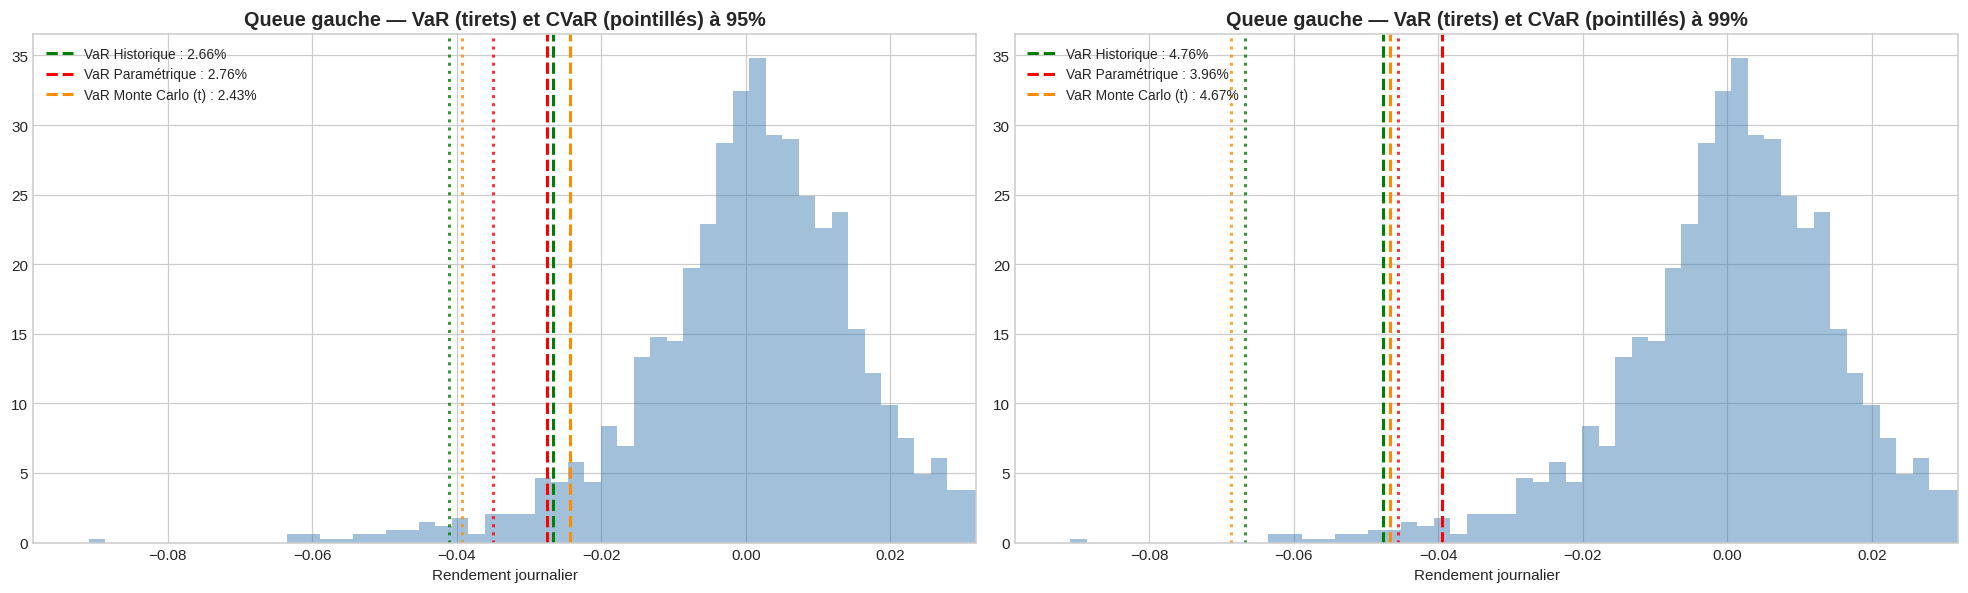

In [ ]:
# ============================================================
# 📏 VaR & CVaR — 3 MÉTHODES × 2 NIVEAUX DE CONFIANCE
# ============================================================
rng_mc = np.random.default_rng(SEED)
U_STATIC = rng_mc.uniform(1e-8, 1 - 1e-8, N_SIM)          # nombres aléatoires communs (reproductibilité)

def var_cvar_historical(r, alpha):
    q = np.quantile(r, 1 - alpha)
    return -q, -r[r <= q].mean()

def var_cvar_parametric(r, alpha):
    mu, sigma = r.mean(), r.std(ddof=1)
    z = stats.norm.ppf(1 - alpha)
    return -(mu + z * sigma), -mu + sigma * stats.norm.pdf(z) / (1 - alpha)

def var_cvar_student_mc(r, alpha, U=U_STATIC):
    nu, loc, scale = stats.t.fit(r)                         # calibration par maximum de vraisemblance
    sims = loc + scale * stats.t.ppf(U, nu)                 # simulation par inversion de la fonction de répartition
    q = np.quantile(sims, 1 - alpha)
    return -q, -sims[sims <= q].mean()

METHODS = {"Historique": var_cvar_historical, "Paramétrique": var_cvar_parametric, "Monte Carlo (t)": var_cvar_student_mc}
risk_res = {a: {m: f(r, a) for m, f in METHODS.items()} for a in ALPHAS}

# Tableau récapitulatif (en %)
risk_table = pd.DataFrame({(f"{a:.0%}", k): [risk_res[a][m][i] * 100 for m in METHODS]
                           for a in ALPHAS for i, k in enumerate(["VaR", "CVaR"])}, index=METHODS.keys())
risk_table.columns = pd.MultiIndex.from_tuples(risk_table.columns, names=["Confiance", "Mesure"])
print("=" * 70); print(f"VaR & CVaR JOURNALIÈRES (% du portefeuille) — {W_RISK_NAME}"); print("=" * 70)
print(risk_table.round(3).to_string())

# Lectures automatiques
for a in ALPHAS:
    v_h, v_p, v_t = (risk_res[a][m][0] for m in METHODS)
    c_h, c_p, c_t = (risk_res[a][m][1] for m in METHODS)
    print(f"\n📝 α={a:.0%} | VaR param. vs hist. : {(v_p / v_h - 1):+.1%} | CVaR param. vs hist. : {(c_p / c_h - 1):+.1%} | VaR t-MC vs param. : {(v_t / v_p - 1):+.1%}")

v99_p = risk_res[0.99]["Paramétrique"][0]
print(f"\n🏦 Exemple Bâle — VaR 99% à 10 jours (règle √T, paramétrique) : {v99_p * np.sqrt(10):.2%} du portefeuille")
print(f"💵 Sur {CAPITAL:,} $ : VaR 99% hist. 1 jour = {risk_res[0.99]['Historique'][0] * CAPITAL:,.0f} $ | CVaR 99% hist. = {risk_res[0.99]['Historique'][1] * CAPITAL:,.0f} $")

# Comparaison des 4 portefeuilles (VaR/CVaR historiques)
cmp_rows = {}
for name, w in PORTFOLIOS.items():
    rp = portfolio_log_returns(w).values
    cmp_rows[name] = {"VaR 95%": var_cvar_historical(rp, 0.95)[0], "CVaR 95%": var_cvar_historical(rp, 0.95)[1],
                      "VaR 99%": var_cvar_historical(rp, 0.99)[0], "CVaR 99%": var_cvar_historical(rp, 0.99)[1]}
print("\n" + "=" * 70); print("VaR / CVaR HISTORIQUES (%) — COMPARAISON DES 4 PORTEFEUILLES"); print("=" * 70)
print((pd.DataFrame(cmp_rows).T * 100).round(3).to_string())

# Visualisation de la queue gauche
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
colors = {"Historique": "green", "Paramétrique": "red", "Monte Carlo (t)": "darkorange"}
for ax, a in zip(axes, ALPHAS):
    ax.hist(r, bins=120, density=True, alpha=0.5, color="steelblue")
    for m in METHODS:
        v, c = risk_res[a][m]
        ax.axvline(-v, color=colors[m], ls="--", lw=2, label=f"VaR {m} : {v:.2%}")
        ax.axvline(-c, color=colors[m], ls=":",  lw=2, alpha=0.8)
    ax.set_xlim(np.quantile(r, 0.001), np.quantile(r, 0.97))
    ax.set_title(f"Queue gauche — VaR (tirets) et CVaR (pointillés) à {a:.0%}")
    ax.set_xlabel("Rendement journalier"); ax.legend(fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

### 🧠 Interprétation

- **Le CVaR dépasse toujours la VaR** (par construction) : la VaR dit « *à partir de quel seuil* je perds », le CVaR dit « *combien* je perds **en moyenne** quand ce seuil est franchi ». C'est l'information qui manque à la VaR et qui est la plus utile pour dimensionner le capital.
- **À 95 %**, les trois VaR sont **proches** : un quantile à 5 % reste relativement proche du centre de la distribution, où la loi normale et la Student-t se ressemblent. Ce n'est donc **pas à 95 %** que se manifeste le danger de la normalité, ce qui explique que la VaR paramétrique y soit validée par le backtest.
- **Le danger apparaît dans la queue :** l'écart entre CVaR paramétrique et CVaR historique/Student-t, et l'écart des VaR à **99 %**, montrent que **la loi normale sous-estime la gravité des pertes extrêmes**. Pour une loi normale, le rapport CVaR/VaR vaut seulement ≈ 1,25 (à 95 %) et ≈ 1,15 (à 99 %) ; les données réelles affichent des rapports supérieurs.
- **Résultat contre-intuitif mais théoriquement prévu :** à 95 %, la VaR Monte Carlo Student-t peut être **inférieure** à la VaR gaussienne (le quantile standardisé d'une t à faible $\nu$ est plus petit à ce niveau, cf. cadre théorique). Ce n'est pas un défaut du code mais la **signature des queues épaisses** : la Student-t « déplace » la masse du corps vers l'extrême queue.
- **Message pour le risk manager :** *la VaR paramétrique n'est pas fausse partout, elle est fausse **là où ça compte** (queue extrême), précisément là où le CVaR et la Student-t apportent de l'information.*
- **Concentration :** la dernière table montre que le **portefeuille tangent libre** (98 % sur 2 titres) a des VaR/CVaR nettement supérieures à celles des portefeuilles diversifiés : **la concentration se paie en risque de queue**, ce qui justifie a posteriori la contrainte de la Partie 2.

## 🧪 Étape 3.3 — Backtesting par fenêtre glissante

**🎯 Objectif.** Une VaR **non validée empiriquement n'a aucune valeur** : seule une confrontation aux pertes **réellement observées** permet de juger un modèle. Pour chaque jour $t$, on calibre les trois VaR sur les **250 jours précédents** uniquement (aucune information future), puis on regarde si la perte du jour $t$ dépasse la VaR prévue.

### 📐 Cadre théorique

**Procédure *out-of-sample* à fenêtre glissante** (taille $W=250$) : pour $t=W+1,\dots,T$,
$$\widehat{\text{VaR}}_{\alpha,t}=\text{VaR}_\alpha\big(r_{t-W},\dots,r_{t-1}\big)$$

**Indicatrice de dépassement (*hit*) :**
$$I_t=\mathbb 1\big\{r_t<-\widehat{\text{VaR}}_{\alpha,t}\big\}$$

Si le modèle est correct, les $I_t$ sont **i.i.d. Bernoulli($p$)** avec $p=1-\alpha$, c'est-à-dire :
1. **Couverture inconditionnelle** : $\mathbb P(I_t=1)=p$ — testée par **Kupiec**.
2. **Indépendance** : les dépassements ne se regroupent pas dans le temps — testée par **Christoffersen**.

**Méthode Monte Carlo :** à chaque fenêtre, la Student-t est recalibrée ($\hat\nu,\hat m,\hat s$) ; on utilise des **nombres aléatoires communs** (même $U_k$) pour isoler la variabilité due au modèle de celle due à la simulation.

⏳ Backtesting sur fenêtre glissante de 250 jours (calibrations Student-t en cours, ~30 s)...
✅ Terminé en 159 s | 1259 jours testés (2019-12-31 → 2024-12-31)

TAUX DE DÉPASSEMENTS OBSERVÉS vs THÉORIQUES

α = 95% (taux attendu : 5.00% soit ≈ 63.0 jours)
  Historique         :  73 / 1259 = 5.80%
  Paramétrique       :  72 / 1259 = 5.72%
  Monte Carlo (t)    :  81 / 1259 = 6.43%

α = 99% (taux attendu : 1.00% soit ≈ 12.6 jours)
  Historique         :  27 / 1259 = 2.14%
  Paramétrique       :  38 / 1259 = 3.02%
  Monte Carlo (t)    :  27 / 1259 = 2.14%


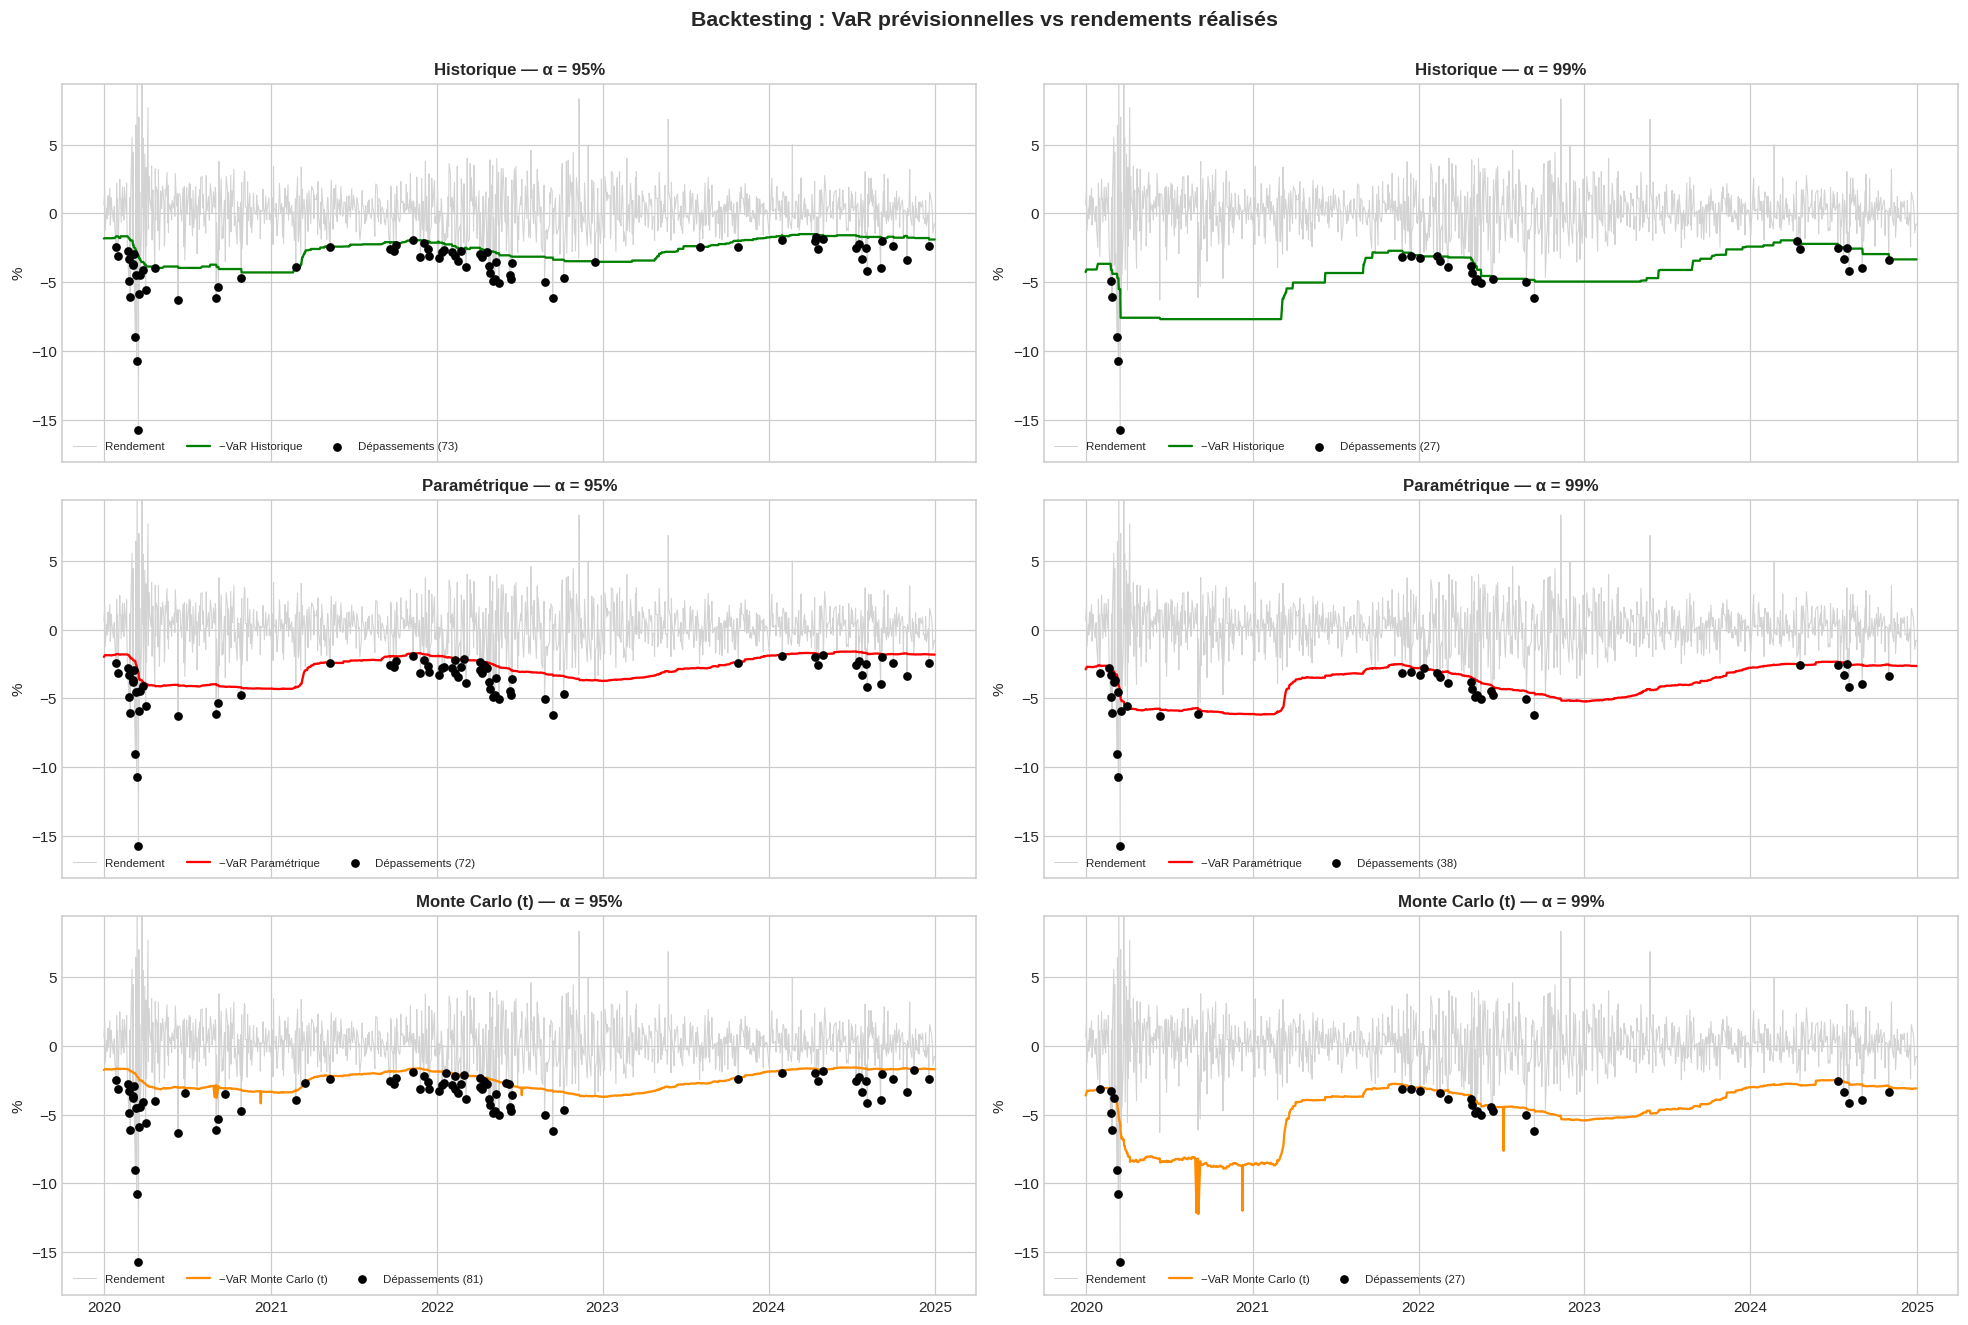

In [ ]:
# ============================================================
# 🧪 BACKTESTING — FENÊTRE GLISSANTE DE 250 JOURS
# ============================================================
U_ROLL = np.random.default_rng(SEED).uniform(1e-8, 1 - 1e-8, N_SIM_ROLL)   # nombres aléatoires communs

def rolling_var_forecasts(returns, window=WINDOW, alphas=ALPHAS):
    '''VaR prévisionnelles à J (calibrées sur [t-window, t-1]) pour les 3 méthodes et tous les niveaux alpha.'''
    vals = returns.values
    idx  = returns.index[window:]
    out  = {a: {m: np.empty(len(idx)) for m in METHODS} for a in alphas}
    for k, t in enumerate(range(window, len(vals))):
        train_w = vals[t - window:t]
        mean_w, std_w = train_w.mean(), train_w.std(ddof=1)
        nu_w, loc_w, sc_w = stats.t.fit(train_w)                      # une seule calibration t par fenêtre
        sims_w = loc_w + sc_w * stats.t.ppf(U_ROLL, nu_w)
        for a in alphas:
            out[a]["Historique"][k]      = -np.quantile(train_w, 1 - a)
            out[a]["Paramétrique"][k]    = -(mean_w + stats.norm.ppf(1 - a) * std_w)
            out[a]["Monte Carlo (t)"][k] = -np.quantile(sims_w, 1 - a)
    return {a: pd.DataFrame(out[a], index=idx) for a in alphas}

print(f"⏳ Backtesting sur fenêtre glissante de {WINDOW} jours (calibrations Student-t en cours, ~30 s)...")
t0 = time.time()
var_fc = rolling_var_forecasts(port_ret)
test_ret = port_ret.iloc[WINDOW:]
hits = {a: var_fc[a].lt(-test_ret, axis=0) for a in ALPHAS}              # True si perte du jour > VaR prévue
T_TEST = len(test_ret)
print(f"✅ Terminé en {time.time() - t0:.0f} s | {T_TEST} jours testés ({test_ret.index[0].date()} → {test_ret.index[-1].date()})")

print("\n" + "=" * 75)
print("TAUX DE DÉPASSEMENTS OBSERVÉS vs THÉORIQUES")
print("=" * 75)
for a in ALPHAS:
    print(f"\nα = {a:.0%} (taux attendu : {1 - a:.2%} soit ≈ {(1 - a) * T_TEST:.1f} jours)")
    for m in METHODS:
        x = int(hits[a][m].sum())
        print(f"  {m:18s} : {x:3d} / {T_TEST} = {x / T_TEST:.2%}")

# Visualisation : VaR prévues et dépassements
fig, axes = plt.subplots(3, 2, figsize=(18, 12), sharex=True)
for j, a in enumerate(ALPHAS):
    for i, m in enumerate(METHODS):
        ax = axes[i, j]
        ax.plot(test_ret.index, test_ret * 100, color="lightgrey", lw=0.7, label="Rendement")
        ax.plot(test_ret.index, -var_fc[a][m] * 100, color=colors[m], lw=1.5, label=f"−VaR {m}")
        h = hits[a][m]
        ax.scatter(test_ret.index[h], test_ret[h] * 100, color="black", s=22, zorder=5, label=f"Dépassements ({h.sum()})")
        ax.set_title(f"{m} — α = {a:.0%}", fontsize=11); ax.legend(fontsize=7.5, loc="lower left", ncol=3)
        ax.set_ylabel("%"); ax.set_ylim(test_ret.min() * 115, -test_ret.min() * 60)
plt.suptitle("Backtesting : VaR prévisionnelles vs rendements réalisés", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

### 🧠 Interprétation

- **Lecture visuelle :** les dépassements (points noirs) ne sont pas répartis uniformément dans le temps : ils tendent à **se regrouper** en périodes de turbulence (typiquement début 2020 et 2022), c'est-à-dire précisément quand la volatilité *réalisée* dépasse celle estimée sur la fenêtre passée. Une VaR calibrée sur une fenêtre calme **réagit avec retard** à une crise.
- **Lecture des taux :** pour α = 95 %, le taux attendu est de 5 % ; dans l'exécution de référence, les méthodes **historique et paramétrique** produisent des taux **proches de 5-6 %**, tandis que la méthode **Monte Carlo Student-t** s'en écarte davantage (cf. sortie). À 99 %, le taux attendu est de 1 % (environ 12-13 jours sur la période de test) : les écarts relatifs sont plus marqués car les événements sont rares.
- ➡️ Ces taux bruts ne suffisent pas à conclure : il faut savoir si l'écart observé est **statistiquement significatif** ou compatible avec le simple aléa d'échantillonnage. C'est le rôle des tests de Kupiec et de Christoffersen.

## ⚖️ Étape 3.4 — Tests de Kupiec (POF) et de Christoffersen

**🎯 Objectif.** Trancher **statistiquement** : le nombre de dépassements est-il compatible avec le niveau de confiance annoncé (**Kupiec**) ? Les dépassements sont-ils **indépendants** ou arrivent-ils en grappes (**Christoffersen**) ? Un modèle de VaR n'est **validé** que s'il passe *les deux* tests (couverture conditionnelle).

### 📐 Cadre théorique

Soit $x=\sum_t I_t$ le nombre de dépassements sur $T$ jours et $p=1-\alpha$.

**Test de Kupiec (1995) — Proportion of Failures :**
$$LR_{POF}=-2\ln\!\left[\frac{(1-p)^{T-x}\,p^{x}}{\left(1-\frac xT\right)^{T-x}\left(\frac xT\right)^{x}}\right]\;\sim\;\chi^{2}(1)\quad\text{sous }H_0:\ \mathbb P(I_t=1)=p$$

**Test d'indépendance de Christoffersen (1998)** : on modélise $(I_t)$ par une chaîne de Markov d'ordre 1 de matrice de transition $\begin{pmatrix}1-\pi_{01}&\pi_{01}\\1-\pi_{11}&\pi_{11}\end{pmatrix}$ ; $H_0:\ \pi_{01}=\pi_{11}$ :
$$LR_{IND}=-2\ln\frac{(1-\hat\pi)^{n_{00}+n_{10}}\hat\pi^{\,n_{01}+n_{11}}}{(1-\hat\pi_{01})^{n_{00}}\hat\pi_{01}^{\,n_{01}}(1-\hat\pi_{11})^{n_{10}}\hat\pi_{11}^{\,n_{11}}}\;\sim\;\chi^{2}(1)$$
où $n_{ij}$ est le nombre de transitions de l'état $i$ à l'état $j$.

**Couverture conditionnelle :** $LR_{CC}=LR_{POF}+LR_{IND}\sim\chi^2(2)$.

**Règles de décision (α = 5 %) :** rejet si $LR_{POF}>3{,}84$ ou $LR_{IND}>3{,}84$ ou $LR_{CC}>5{,}99$ (p-value < 0,05).

⚠️ **Limite connue :** le test de Kupiec a une **faible puissance** à 95 % sur ~1 250 observations — il ne rejette que des écarts importants.

In [ ]:
# ============================================================
# ⚖️ TESTS DE KUPIEC (POF) & CHRISTOFFERSEN (INDÉPENDANCE)
# ============================================================
def kupiec_pof(x, T, p):
    '''Test de Kupiec (proportion de dépassements). Gère proprement les cas x=0 et x=T.'''
    pi_hat = x / T
    ll_null = xlogy(T - x, 1 - p) + xlogy(x, p)
    ll_alt  = xlog1py(T - x, -pi_hat) + xlogy(x, pi_hat)
    LR = -2 * (ll_null - ll_alt)
    return LR, 1 - stats.chi2.cdf(LR, 1)

def christoffersen_independence(h):
    '''Test d'indépendance de Christoffersen sur une série booléenne de dépassements.'''
    h = np.asarray(h, dtype=int)
    prev, curr = h[:-1], h[1:]
    n00 = np.sum((prev == 0) & (curr == 0)); n01 = np.sum((prev == 0) & (curr == 1))
    n10 = np.sum((prev == 1) & (curr == 0)); n11 = np.sum((prev == 1) & (curr == 1))
    pi01 = n01 / (n00 + n01) if (n00 + n01) > 0 else 0.0
    pi11 = n11 / (n10 + n11) if (n10 + n11) > 0 else 0.0
    pi   = (n01 + n11) / (n00 + n01 + n10 + n11)
    ll_null = xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi)
    ll_alt  = xlogy(n00, 1 - pi01) + xlogy(n01, pi01) + xlogy(n10, 1 - pi11) + xlogy(n11, pi11)
    LR = max(-2 * (ll_null - ll_alt), 0.0)
    return LR, 1 - stats.chi2.cdf(LR, 1)

rows = []
for a in ALPHAS:
    p = 1 - a
    for m in METHODS:
        h = hits[a][m].values
        x = int(h.sum())
        lr_pof, p_pof = kupiec_pof(x, T_TEST, p)
        lr_ind, p_ind = christoffersen_independence(h)
        p_cc = 1 - stats.chi2.cdf(lr_pof + lr_ind, 2)
        rows.append({"α": f"{a:.0%}", "Méthode": m, "Dépass. x": x, "Taux": x / T_TEST,
                     "LR Kupiec": lr_pof, "p Kupiec": p_pof, "Kupiec": "✅" if p_pof > 0.05 else "❌",
                     "p Christ.": p_ind, "Indép.": "✅" if p_ind > 0.05 else "❌",
                     "p CC": p_cc, "Verdict global": "✅ Validé" if (p_cc > 0.05 and p_pof > 0.05) else "❌ Rejeté"})
backtest_df = pd.DataFrame(rows)

print("=" * 125)
print(f"BACKTESTING — KUPIEC / CHRISTOFFERSEN  (T = {T_TEST} jours, portefeuille : {W_RISK_NAME})")
print("=" * 125)
print(backtest_df.round({"Taux": 4, "LR Kupiec": 2, "p Kupiec": 3, "p Christ.": 3, "p CC": 3}).to_string(index=False))

print("\n📝 LECTURES AUTOMATIQUES")
for _, row in backtest_df.iterrows():
    direction = "SOUS-estime" if row["Taux"] > (1 - float(row["α"].strip("%")) / 100) else "sur-estime"
    print(f"  • α={row['α']} {row['Méthode']:16s} → taux {row['Taux']:.2%} ({direction} le risque) | Kupiec {row['Kupiec']} | Indépendance {row['Indép.']} | {row['Verdict global']}")

BACKTESTING — KUPIEC / CHRISTOFFERSEN  (T = 1259 jours, portefeuille : Tangent (cap 25%))
  α         Méthode  Dépass. x   Taux  LR Kupiec  p Kupiec Kupiec  p Christ. Indép.  p CC Verdict global
95%      Historique         73 0.0580       1.61     0.204      ✅      0.188      ✅ 0.188       ✅ Validé
95%    Paramétrique         72 0.0572       1.31     0.252      ✅      0.068      ✅ 0.099       ✅ Validé
95% Monte Carlo (t)         81 0.0643       5.02     0.025      ❌      0.104      ✅ 0.022       ❌ Rejeté
99%      Historique         27 0.0214      12.55     0.000      ❌      0.276      ✅ 0.001       ❌ Rejeté
99%    Paramétrique         38 0.0302      33.66     0.000      ❌      0.029      ❌ 0.000       ❌ Rejeté
99% Monte Carlo (t)         27 0.0214      12.55     0.000      ❌      0.132      ✅ 0.001       ❌ Rejeté

📝 LECTURES AUTOMATIQUES
  • α=95% Historique       → taux 5.80% (SOUS-estime le risque) | Kupiec ✅ | Indépendance ✅ | ✅ Validé
  • α=95% Paramétrique     → taux 5.72% (SOUS-e

### 🧠 Interprétation

- **Kupiec — résultats de l'exécution de référence du projet :** la **VaR historique** et la **VaR paramétrique** sont **validées** (taux de dépassement ≈ 5-6 % pour un objectif de 5 %, p-values > 0,05) ; la **VaR Monte Carlo Student-t est rejetée** par le test de Kupiec au seuil de 5 %. *(Si votre sortie diffère légèrement — par exemple en changeant de portefeuille analysé — la « lecture automatique » du code prévaut ; la logique d'interprétation ci-dessous reste valable.)*
- **Pourquoi la Monte Carlo est-elle rejetée alors qu'elle modélise mieux les queues ?** Deux mécanismes complémentaires l'expliquent :
  1. **Effet de forme à 95 %** : comme montré à l'étape 3.2, une Student-t à faible $\nu$ calibrée par maximum de vraisemblance donne à 95 % un quantile **plus proche de zéro** que la gaussienne. La VaR est donc **structurellement plus basse**, ce qui engendre **trop de dépassements**. L'avantage de la Student-t se situe à 99 % et dans le CVaR, **pas** au quantile 5 %.
  2. **Bruit d'estimation de $\nu$** : estimer $\hat\nu$ sur seulement 250 observations est très instable (peu d'observations dans la queue) ; ce bruit est transmis directement à la VaR.
- **« Validée » ne veut pas dire « sûre ».** La VaR paramétrique passe Kupiec à 95 % **sans que cela invalide l'argument de non-normalité** : Kupiec ne teste que la **fréquence** des dépassements, **jamais leur ampleur**. Or une VaR gaussienne peut avoir la bonne fréquence tout en **sous-estimant gravement l'ampleur des pertes** lorsqu'elles surviennent (c'est le rôle du CVaR). De plus, la faible puissance du test à 95 % limite sa capacité à rejeter.
- **Indépendance (Christoffersen) :** les dépassements **se regroupent** pendant les périodes de stress. Un modèle à volatilité constante ne s'ajuste pas assez vite : c'est la limite des VaR à fenêtre glissante, que corrigent les modèles **GARCH** (extension, Partie 5).
- **À 99 %**, le nombre de dépassements attendus est très faible : les tests y sont **moins puissants** et le résultat doit être lu avec prudence (feu tricolore de Bâle : ≤ 4 dépassements sur 250 jours = zone verte).

## 🔗 Étape 3.5 — Synthèse : du rejet de la normalité à la CVaR

**🎯 Objectif.** Boucler la démonstration logique de la Partie 3 en quantifiant **combien** la loi normale sous-estime le risque de queue, à l'aide du **ratio de queue** $\text{CVaR}/\text{VaR}$ : un indicateur indépendant de l'échelle de volatilité qui mesure l'**épaisseur effective** de la queue.

### 📐 Cadre théorique

**Ratio de queue (*tail ratio*) :**
$$\text{TR}_\alpha=\frac{\text{CVaR}_\alpha}{\text{VaR}_\alpha}$$

Pour une loi normale (de moyenne négligeable), ce ratio est **fixé par $\alpha$** :
$$\text{TR}^{\mathcal N}_\alpha=\frac{\varphi(z_{1-\alpha})}{(1-\alpha)\,|z_{1-\alpha}|}\;\approx\;1{,}25\;(\alpha=95\%),\qquad\approx\;1{,}15\;(\alpha=99\%)$$

Un ratio **empirique supérieur** au ratio gaussien mesure directement l'**excès de gravité** des pertes extrêmes dû aux queues épaisses.

RATIO DE QUEUE  CVaR / VaR
     Gaussien théorique  Historique  Paramétrique (éch.)  Monte Carlo (t)
95%               1.254       1.543                1.267            1.614
99%               1.146       1.403                1.151            1.471

📉 SOUS-ESTIMATION RELATIVE PAR LE MODÈLE GAUSSIEN (vs historique)
  α=95% : VaR +3.5%  |  CVaR -15.0%
  α=99% : VaR -16.9%  |  CVaR -31.8%


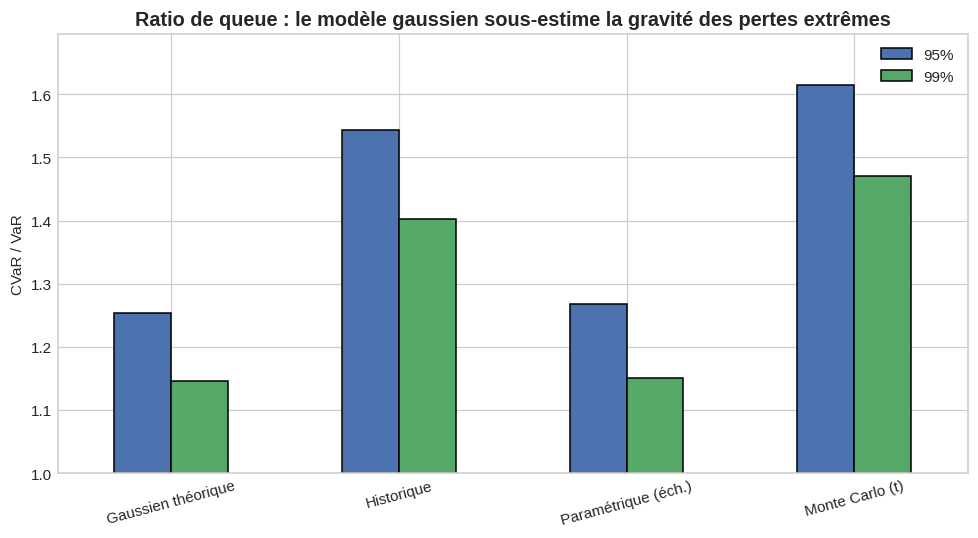

In [ ]:
# ============================================================
# 🔗 SYNTHÈSE — RATIO DE QUEUE CVaR / VaR
# ============================================================
tail_rows = {}
for a in ALPHAS:
    z = stats.norm.ppf(1 - a)
    tail_rows[f"{a:.0%}"] = {
        "Gaussien théorique": stats.norm.pdf(z) / ((1 - a) * abs(z)),
        "Historique":         risk_res[a]["Historique"][1] / risk_res[a]["Historique"][0],
        "Paramétrique (éch.)": risk_res[a]["Paramétrique"][1] / risk_res[a]["Paramétrique"][0],
        "Monte Carlo (t)":    risk_res[a]["Monte Carlo (t)"][1] / risk_res[a]["Monte Carlo (t)"][0],
    }
tail_df = pd.DataFrame(tail_rows).T
print("=" * 80); print("RATIO DE QUEUE  CVaR / VaR"); print("=" * 80)
print(tail_df.round(3).to_string())

# Sous-estimation relative de la CVaR gaussienne
print("\n📉 SOUS-ESTIMATION RELATIVE PAR LE MODÈLE GAUSSIEN (vs historique)")
for a in ALPHAS:
    gap_var  = risk_res[a]["Paramétrique"][0] / risk_res[a]["Historique"][0] - 1
    gap_cvar = risk_res[a]["Paramétrique"][1] / risk_res[a]["Historique"][1] - 1
    print(f"  α={a:.0%} : VaR {gap_var:+.1%}  |  CVaR {gap_cvar:+.1%}")

fig, ax = plt.subplots(figsize=(9, 5))
tail_df.T.plot.bar(ax=ax, edgecolor="black", rot=15, color=["#4c72b0", "#55a868"])
ax.set_ylabel("CVaR / VaR"); ax.set_title("Ratio de queue : le modèle gaussien sous-estime la gravité des pertes extrêmes")
ax.set_ylim(1, None); plt.tight_layout(); plt.show()

### 🧠 Interprétation — Conclusion de la Partie 3

**La démonstration en quatre temps :**

1. **Constat** : Jarque-Bera rejette la normalité (Partie 1) et la non-normalité **persiste au niveau du portefeuille** (Étape 3.1).
2. **Danger** : le ratio de queue gaussien est **rigide** (≈ 1,25 à 95 %, ≈ 1,15 à 99 %) alors que le ratio empirique est supérieur : **la VaR paramétrique et surtout sa CVaR sous-estiment la gravité des pertes extrêmes**. La VaR paramétrique est donc **dangereuse**, même lorsque son taux de dépassement passe Kupiec.
3. **Remèdes** : **(a)** le **CVaR** quantifie la perte moyenne au-delà du seuil — c'est la mesure cohérente et la plus informative sur la queue ; **(b)** la **loi de Student-t** reproduit les queues épaisses (QQ-plot, AIC), avec un avantage qui se manifeste **à 99 % et dans le CVaR** plutôt qu'à 95 %.
4. **Arbitrage** : le backtesting valide la fréquence des dépassements mais **ne mesure pas leur ampleur** ; la **VaR historique** offre le meilleur compromis pratique (aucune hypothèse de loi, validée), à condition d'être **complétée par la CVaR et par des stress tests** — objet de la Partie 4.

> 🎤 **Phrase de soutenance :** *« Une VaR validée par Kupiec n'est pas une VaR sans risque : elle dit combien de fois on se trompe, jamais de combien. C'est pourquoi nous complétons la VaR par la CVaR et le stress testing. »*

# 🌪️ PARTIE 4 — Stress Testing & Résilience
*Krach COVID · Maximum Drawdown · comparaison au S&P 500 · ratios de Sortino et Calmar*

**Question de la partie :** la VaR décrit les 95 % de jours « normaux ». **Que se passe-t-il dans les 5 % restants ?** Un risk manager doit répondre à trois questions : *quelle perte en cas de crise ? quelle pire chute historique ? le portefeuille bat-il simplement l'indice ?*

## 💥 Étape 4.1 — Stress testing : scénarios historiques et hypothétiques

**🎯 Objectif.** Évaluer la perte du portefeuille sous des **chocs extrêmes** que la VaR (calibrée sur des conditions « normales ») ne capte pas. On combine deux familles de scénarios :

- **Historiques** : rejouer des crises réelles (**krach COVID** de février-mars 2020, **marché baissier de 2022**) sur les poids actuels.
- **Hypothétiques** : chocs sectoriels *ad hoc* (krach technologique, choc uniforme, rotation sectorielle), qui ciblent la **vulnérabilité structurelle** (concentration sur la Big Tech).

### 📐 Cadre théorique

**Scénario historique** — pour une fenêtre $[t_a,t_b]$, le rendement cumulé de l'actif $i$ est
$$R_i^{[t_a,t_b]}=\prod_{t=t_a+1}^{t_b}(1+R_{i,t})-1$$
et la perte du portefeuille (poids initiaux $w$, sans rebalancement) vaut
$$\Delta V/V=\sum_i w_i\,R_i^{[t_a,t_b]}$$

**Scénario hypothétique** — pour un vecteur de chocs instantanés $s=(s_1,\dots,s_N)$ :
$$\Delta V/V=w^{\top}s$$
(exacte pour un choc instantané sur un portefeuille détenu à poids $w$).

**Multiple de VaR** : $\dfrac{\text{perte du pire jour}}{\text{VaR}_{99\%}}$ — mesure de combien la VaR « normale » est dépassée en crise.

**Contribution de l'actif $i$** à la perte : $w_i\,R_i^{[t_a,t_b]}$.

PERTE / GAIN DES PORTEFEUILLES SOUS STRESS (en %)
                                                Équipondéré  Min-variance  Tangent libre  Tangent (cap 25%)  S&P 500
Krach COVID-19 (19/02/20 → 23/03/20)                  -31.7         -28.8          -31.9              -33.4    -33.9
Marché baissier 2022 (03/01/22 → 12/10/22)            -22.9          -3.3          -46.1              -31.8    -25.4
Krach tech (tech −30 %, autres −5 %)                  -20.0          -8.4          -29.6              -23.4      NaN
Choc de marché uniforme (−20 %)                       -20.0         -20.0          -20.0              -20.0      NaN
Rotation sectorielle (tech −25 %, autres +5 %)        -13.0           0.9          -24.5              -17.1      NaN

📉 Pire journée COVID (Tangent (cap 25%)) : -14.55% le 2020-03-16
📏 VaR 99% historique = 4.76% → la pire journée vaut 3.1 × la VaR 99% et 2.2 × la CVaR 99%
📏 Perte COVID cumulée (19/02→23/03) = 7.0 × la VaR 99% journalière


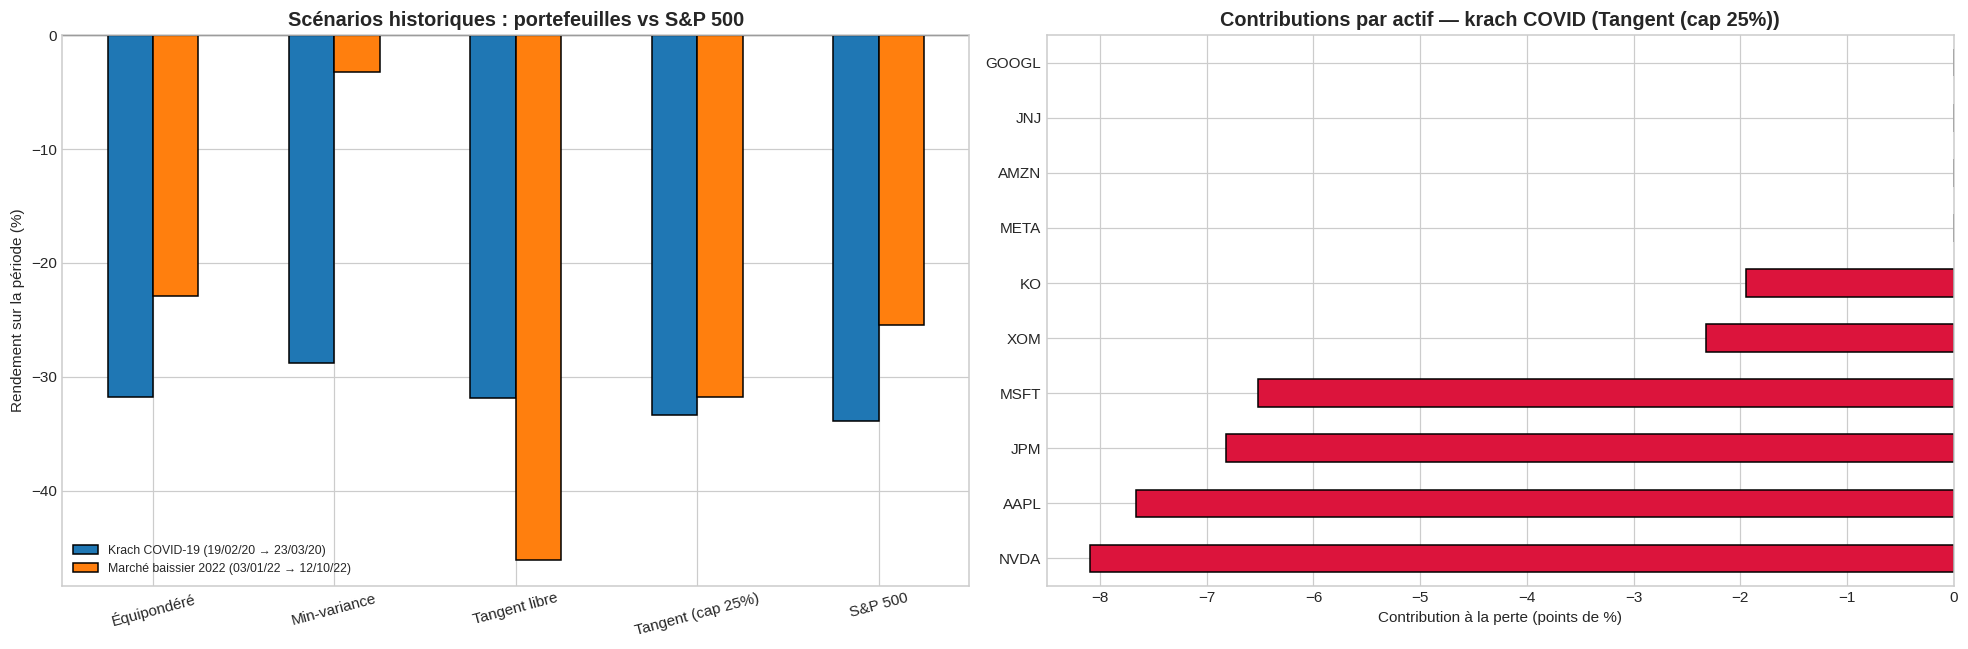

In [ ]:
# ============================================================
# 💥 STRESS TESTING — SCÉNARIOS HISTORIQUES & HYPOTHÉTIQUES
# ============================================================
simple_assets = np.expm1(ret_assets)       # rendements simples des actifs
simple_bench  = np.expm1(ret_bench)

HIST_SCENARIOS = {
    "Krach COVID-19 (19/02/20 → 23/03/20)":      ("2020-02-19", "2020-03-23"),
    "Marché baissier 2022 (03/01/22 → 12/10/22)": ("2022-01-03", "2022-10-12"),
}
tech = ["AAPL", "MSFT", "NVDA", "AMZN", "GOOGL", "META"]
HYPO_SCENARIOS = {
    "Krach tech (tech −30 %, autres −5 %)":        pd.Series({t: -0.30 if t in tech else -0.05 for t in TICKERS}),
    "Choc de marché uniforme (−20 %)":             pd.Series(-0.20, index=TICKERS),
    "Rotation sectorielle (tech −25 %, autres +5 %)": pd.Series({t: -0.25 if t in tech else 0.05 for t in TICKERS}),
}

def window_returns(simple_df, start, end):
    '''Rendement cumulé de chaque colonne entre la clôture du jour `start` et celle du jour `end`.'''
    sub = simple_df[(simple_df.index > start) & (simple_df.index <= end)]
    return (1 + sub).prod() - 1

stress_rows = {}
for label, (a, b) in HIST_SCENARIOS.items():
    asset_ret = window_returns(simple_assets, a, b)
    stress_rows[label] = {name: float(asset_ret.values @ w) for name, w in PORTFOLIOS.items()}
    stress_rows[label]["S&P 500"] = float(window_returns(simple_bench.to_frame(), a, b).iloc[0])
for label, s in HYPO_SCENARIOS.items():
    stress_rows[label] = {name: float(s.values @ w) for name, w in PORTFOLIOS.items()}
    stress_rows[label]["S&P 500"] = np.nan
stress_df = pd.DataFrame(stress_rows).T

print("=" * 110)
print("PERTE / GAIN DES PORTEFEUILLES SOUS STRESS (en %)")
print("=" * 110)
print((stress_df * 100).round(1).to_string())

# Pire journée du krach COVID et multiple de VaR
covid_a, covid_b = HIST_SCENARIOS["Krach COVID-19 (19/02/20 → 23/03/20)"]
port_simple = np.expm1(port_ret)
covid_days  = port_simple[(port_simple.index > covid_a) & (port_simple.index <= covid_b)]
worst_day, worst_date = covid_days.min(), covid_days.idxmin()
var99_hist = risk_res[0.99]["Historique"][0]
cvar99_hist = risk_res[0.99]["Historique"][1]
print(f"\n📉 Pire journée COVID ({W_RISK_NAME}) : {worst_day:.2%} le {worst_date.date()}")
print(f"📏 VaR 99% historique = {var99_hist:.2%} → la pire journée vaut {abs(worst_day) / var99_hist:.1f} × la VaR 99% et {abs(worst_day) / cvar99_hist:.1f} × la CVaR 99%")
print(f"📏 Perte COVID cumulée (19/02→23/03) = {abs(stress_df.iloc[0][W_RISK_NAME]) / var99_hist:.1f} × la VaR 99% journalière")

# Contributions par actif — scénario COVID
asset_covid = window_returns(simple_assets, covid_a, covid_b)
contrib = (w_risk * asset_covid.values * 100)
contrib = pd.Series(contrib, index=TICKERS).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
hist_labels = list(HIST_SCENARIOS.keys())
(stress_df.loc[hist_labels, list(PORTFOLIOS) + ["S&P 500"]] * 100).T.plot.bar(ax=axes[0], edgecolor="black", rot=15)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_ylabel("Rendement sur la période (%)"); axes[0].set_title("Scénarios historiques : portefeuilles vs S&P 500")
axes[0].legend(fontsize=8)
contrib.plot.barh(ax=axes[1], color="crimson", edgecolor="black")
axes[1].set_xlabel("Contribution à la perte (points de %)")
axes[1].set_title(f"Contributions par actif — krach COVID ({W_RISK_NAME})")
plt.tight_layout(); plt.show()

### 🧠 Interprétation

- **Krach COVID :** tous les portefeuilles subissent une **perte très supérieure à ce que la VaR journalière laisse anticiper**. La **pire journée** dépasse la VaR 99 % (multiple imprimé ci-dessus), et la **perte cumulée** sur cinq semaines équivaut à de nombreuses fois la VaR 99 % d'un jour : la VaR mesure le risque d'une journée *normale*, pas celui d'une **crise systémique**.
- **La diversification échoue quand on en a le plus besoin.** En période de crise, les corrélations convergent vers 1 : le bénéfice de diversification mesuré sur l'ensemble de l'échantillon (Étape 1.5) **disparaît** précisément pendant le krach. C'est la limite fondamentale d'une matrice de covariance **supposée constante**.
- **Scénario 2022 :** ce marché baissier frappe les **valeurs de croissance** (hausse des taux). Un portefeuille concentré sur la technologie y est **plus exposé que l'indice** : le tableau montre à quel point la concentration factorielle (Étape 1.1) se paie lors d'un retournement de régime.
- **Scénarios hypothétiques :** le **krach tech** et la **rotation sectorielle** pénalisent davantage les portefeuilles à forte pondération technologique (le tangent libre en tête) que ceux orientés valeurs défensives (cf. tableau). Le choc uniforme, lui, frappe tous les portefeuilles à parts égales (somme des poids = 1) : il ne discrimine pas, c'est le **choc sectoriel** qui révèle la vulnérabilité.
- **Contributions :** les actions les plus lourdes **et** les plus volatiles (NVDA, AAPL, AMZN, META) concentrent l'essentiel de la perte : la **contrainte à 25 %** limite la contribution de chacune, sans l'éliminer.
- ✅ **Message pour le jury :** *le stress testing complète la VaR en explorant la zone que les distributions estimées ne couvrent pas — il quantifie la perte sous des événements « jamais vus » dans la fenêtre de calibration.*

## 📉 Étape 4.2 — Maximum Drawdown : la douleur maximale de l'investisseur

**🎯 Objectif.** Mesurer la **pire chute cumulée** du portefeuille entre un sommet et un creux, ainsi que sa **durée de récupération**. Contrairement à la volatilité (symétrique) ou à la VaR (horizon 1 jour), le drawdown capture ce que **vit réellement un investisseur** : la perte de valeur depuis son plus haut, et le temps nécessaire pour la rattraper.

### 📐 Cadre théorique

Soit $V_t$ la valeur du portefeuille et $M_t=\max_{s\le t}V_s$ son plus haut historique :

$$DD_t=\frac{V_t-M_t}{M_t}\le 0\qquad\qquad MDD=\min_{t}\,DD_t$$

**Asymétrie des pertes :** une perte de $x\,\%$ exige un gain de $\dfrac{x}{1-x}$ pour être récupérée (−50 % exige +100 %).

La valeur est construite par capitalisation des log-rendements quotidiens : $V_t=V_0\exp\!\big(\sum_{s\le t}r_s\big)$ (poids constants, rebalancement quotidien implicite, sans coûts de transaction).

MAXIMUM DRAWDOWN
                     Max DD      Sommet       Creux Récupération Durée DD (j) Durée récup. (j)
Équipondéré        -31.89 %  2020-02-19  2020-03-23   2020-06-08           33               77
Min-variance       -29.69 %  2020-02-11  2020-03-23   2020-08-28           41              158
Tangent libre      -49.69 %  2021-12-07  2022-10-14   2023-05-18          311              216
Tangent (cap 25%)  -34.73 %  2021-12-27  2022-10-11   2023-04-28          288              199
S&P 500            -33.92 %  2020-02-19  2020-03-23   2020-08-18           33              148

📝 Gain nécessaire pour récupérer le MDD du portefeuille « Tangent (cap 25%) » : +53.2%


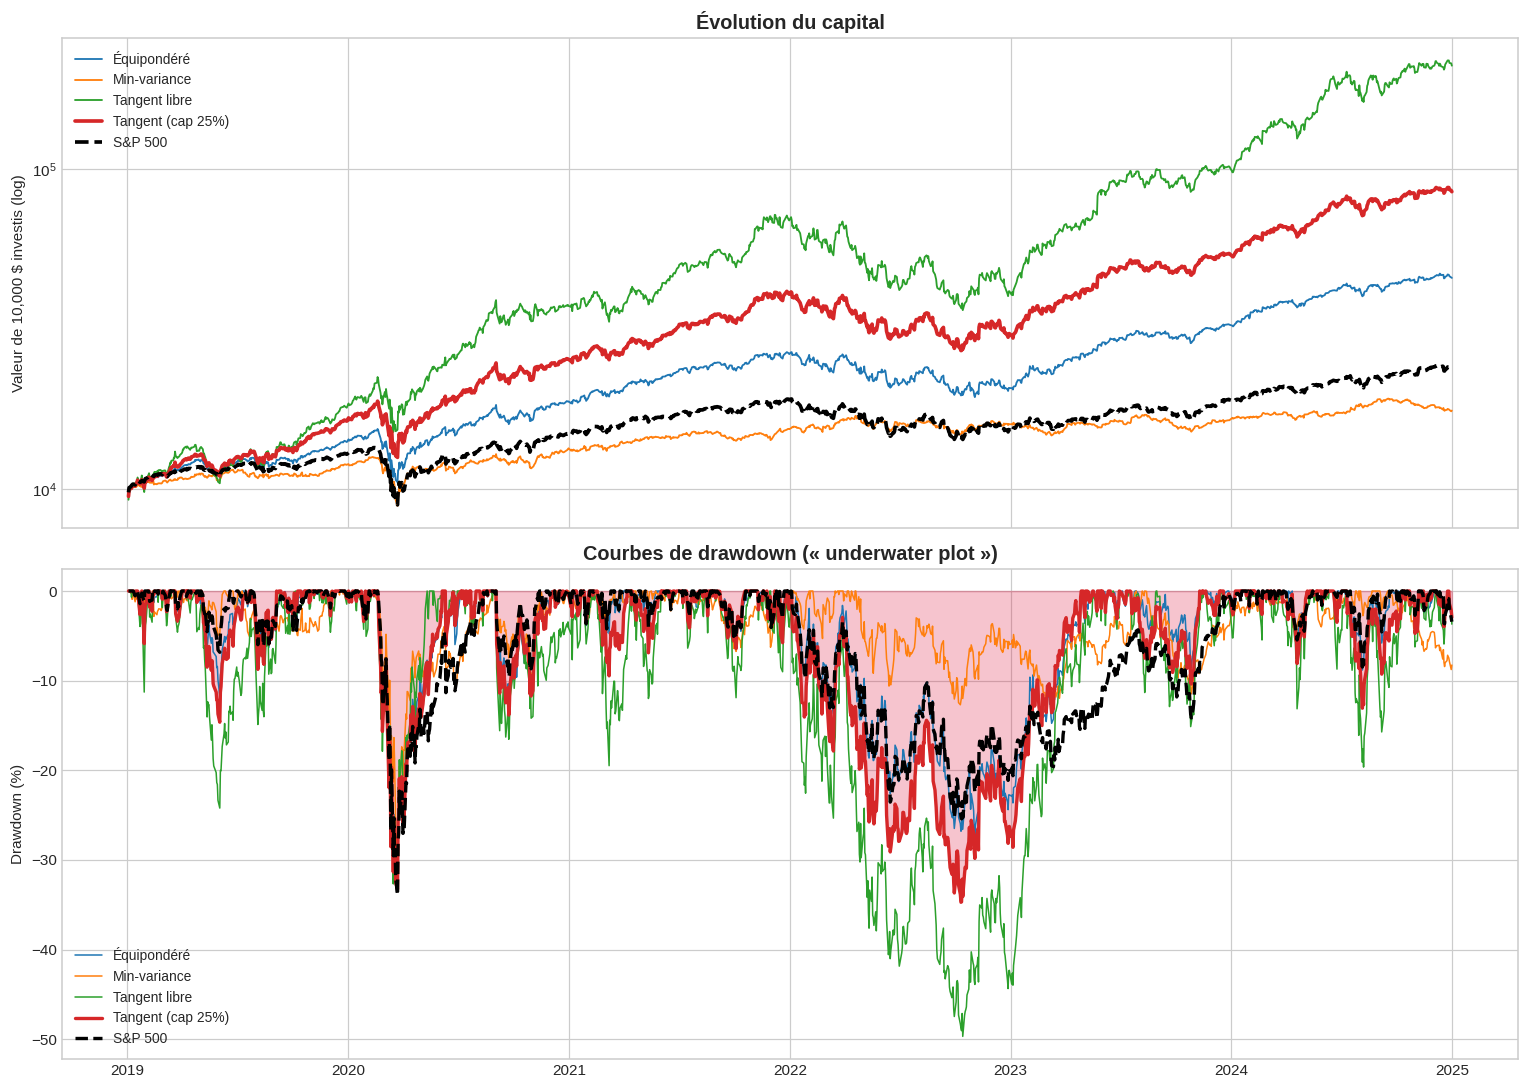

In [ ]:
# ============================================================
# 📉 MAXIMUM DRAWDOWN — 4 PORTEFEUILLES + S&P 500
# ============================================================
port_logs = {name: portfolio_log_returns(w) for name, w in PORTFOLIOS.items()}
port_logs["S&P 500"] = ret_bench
cum_values = {name: np.exp(rp.cumsum()) * CAPITAL for name, rp in port_logs.items()}

def drawdown_stats(value):
    '''Max drawdown, dates du sommet / creux, durée de récupération.'''
    peak = value.cummax()
    dd   = value / peak - 1
    trough_date = dd.idxmin()
    peak_date   = value.loc[:trough_date].idxmax()
    after = value.loc[trough_date:]
    rec = after[after >= value.loc[peak_date]]
    return dd, {"Max DD": dd.min(), "Sommet": peak_date.date(), "Creux": trough_date.date(),
                "Récupération": rec.index[0].date() if len(rec) else "non récupéré",
                "Durée DD (j)": (trough_date - peak_date).days,
                "Durée récup. (j)": (rec.index[0] - trough_date).days if len(rec) else np.nan}

dd_series, dd_rows = {}, {}
for name, v in cum_values.items():
    dd_series[name], dd_rows[name] = drawdown_stats(v)
dd_table = pd.DataFrame(dd_rows).T

print("=" * 100); print("MAXIMUM DRAWDOWN"); print("=" * 100)
print(dd_table.assign(**{"Max DD": (dd_table["Max DD"].astype(float) * 100).round(2).astype(str) + " %"}).to_string())
print(f"\n📝 Gain nécessaire pour récupérer le MDD du portefeuille « {W_RISK_NAME} » : {1 / (1 + dd_rows[W_RISK_NAME]['Max DD']) - 1:+.1%}")

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
for name, v in cum_values.items():
    axes[0].plot(v.index, v, lw=2.4 if name in (NAME_TAN_C, "S&P 500") else 1.2,
                 ls="--" if name == "S&P 500" else "-", color="black" if name == "S&P 500" else None, label=name)
axes[0].set_yscale("log"); axes[0].set_ylabel(f"Valeur de {CAPITAL:,} $ investis (log)")
axes[0].set_title("Évolution du capital"); axes[0].legend(fontsize=9)
for name, dd in dd_series.items():
    if name == W_RISK_NAME:
        axes[1].fill_between(dd.index, dd * 100, 0, color="crimson", alpha=0.25)
    axes[1].plot(dd.index, dd * 100, lw=2.2 if name in (W_RISK_NAME, "S&P 500") else 1.0,
                 ls="--" if name == "S&P 500" else "-", color="black" if name == "S&P 500" else None, label=name)
axes[1].set_ylabel("Drawdown (%)"); axes[1].set_title("Courbes de drawdown (« underwater plot »)"); axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

### 🧠 Interprétation

- **Le krach COVID de mars 2020 et le marché baissier de 2022 sont les deux épisodes de drawdown majeurs** visibles sur l'*underwater plot*. Le portefeuille tangent **libre**, concentré sur deux valeurs, tend à présenter les drawdowns les plus profonds (cf. tableau) : la concentration amplifie les chutes.
- **Le min-variance** subit le drawdown le plus faible parmi les portefeuilles actions : il sacrifie du rendement contre une protection en période de crise.
- **Durée de récupération :** au-delà de la profondeur, ce qui compte pour un investisseur est le **temps passé « sous l'eau »**. Les durées affichées (sommet → creux → retour au sommet) permettent de comparer la **résilience** de chaque allocation.
- **Asymétrie des pertes :** un drawdown de 30 % exige un gain de **+43 %** pour être effacé ; c'est pourquoi la maîtrise des plus fortes chutes prime sur la maximisation du rendement moyen.
- ⚠️ **Limite :** le MDD est un **estimateur à un seul point** (le pire épisode de l'échantillon) : il est très sensible à la période choisie et sous-estime probablement le MDD *futur*.

## 🏁 Étape 4.3 — Comparaison avec le benchmark S&P 500

**🎯 Objectif.** Un portefeuille ne se juge **pas dans l'absolu** mais **par rapport à une alternative passive** : s'il ne fait pas mieux que l'indice (ou ne prend pas moins de risque), il n'a aucune valeur ajoutée. On décompose la performance relative en **bêta** (exposition au marché) et **alpha** (valeur ajoutée).

### 📐 Cadre théorique

**Régression de marché (CAPM) sur les rendements excédentaires journaliers :**
$$r_{p,t}-r_f=\alpha+\beta\,(r_{m,t}-r_f)+\varepsilon_t\qquad\Rightarrow\qquad \beta=\frac{\text{Cov}(r_p,r_m)}{\text{Var}(r_m)}$$

**Alpha de Jensen annualisé :** $\alpha_{ann}=252\cdot\alpha$.

**Tracking error** et **ratio d'information** :
$$TE=\sqrt{252}\;\sigma\big(r_p-r_m\big)\qquad\qquad IR=\frac{252\cdot\overline{(r_p-r_m)}}{TE}$$

**Rendement annualisé géométrique (CAGR)** : $\text{CAGR}=\left(V_T/V_0\right)^{252/T}-1$.

COMPARAISON AU BENCHMARK S&P 500
                  Valeur finale ($)     CAGR Volatilité   Bêta Alpha Jensen  Corrél. S&P Tracking error  Info. ratio
Équipondéré                  45,716  28.89 %    22.76 %  1.072      10.36 %        0.952         7.12 %        1.567
Min-variance                 17,583   9.88 %    16.44 %  0.632      -0.67 %        0.778        12.73 %       -0.377
Tangent libre               210,880  66.38 %    39.13 %  1.539      30.64 %        0.795        26.11 %        1.405
Tangent (cap 25%)            85,076  42.98 %    27.97 %  1.273      18.47 %        0.920        12.27 %        1.755
S&P 500                      23,433  15.28 %    20.22 %  1.000        0.0 %        1.000          nan %          NaN


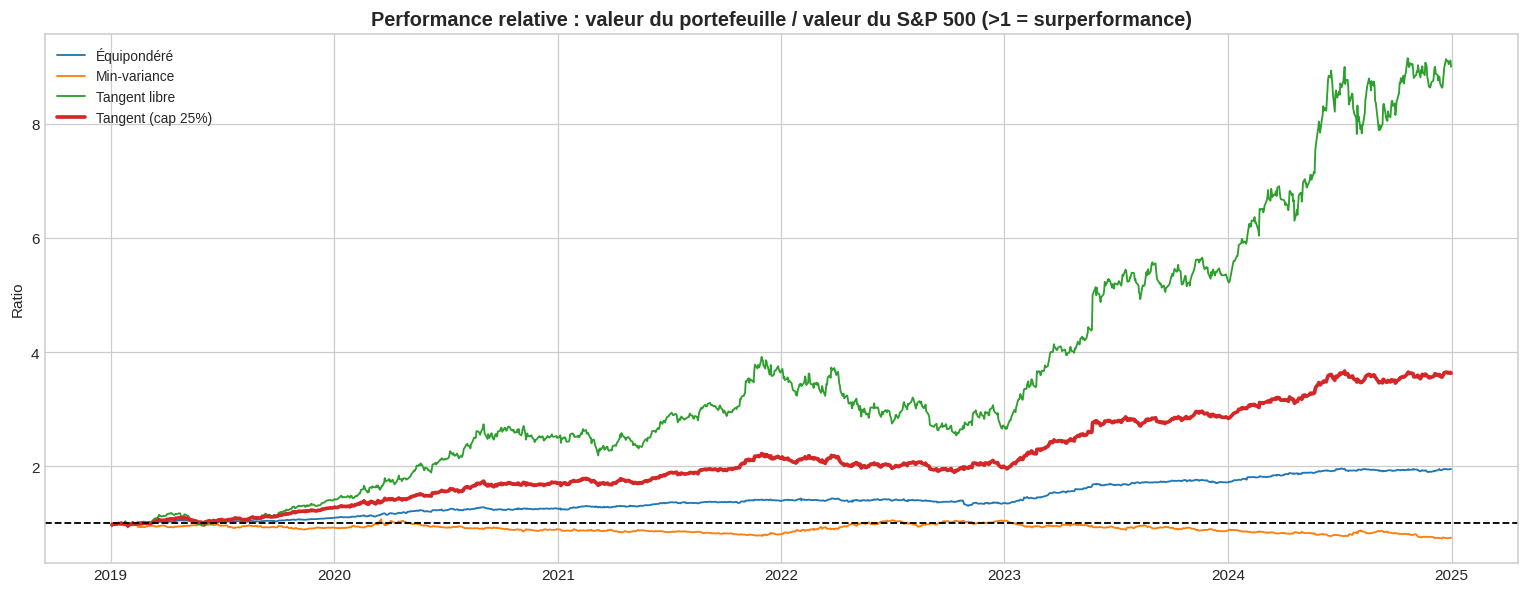

In [ ]:
# ============================================================
# 🏁 PORTEFEUILLES vs S&P 500 : PERFORMANCE RELATIVE, BÊTA, ALPHA
# ============================================================
rf_d = R0 / TRADING_DAYS
rows = {}
for name in list(PORTFOLIOS) + ["S&P 500"]:
    rp = port_logs[name]
    ex_p, ex_m = rp - rf_d, ret_bench - rf_d
    beta  = np.cov(ex_p, ex_m, ddof=1)[0, 1] / ex_m.var(ddof=1)
    alpha = (ex_p.mean() - beta * ex_m.mean()) * TRADING_DAYS
    active = rp - ret_bench
    te = active.std(ddof=1) * np.sqrt(TRADING_DAYS)
    rows[name] = {"Valeur finale ($)": cum_values[name].iloc[-1],
                  "CAGR": (cum_values[name].iloc[-1] / CAPITAL) ** (TRADING_DAYS / len(rp)) - 1,
                  "Volatilité": rp.std() * np.sqrt(TRADING_DAYS),
                  "Bêta": beta, "Alpha Jensen": alpha,
                  "Corrél. S&P": rp.corr(ret_bench),
                  "Tracking error": te if name != "S&P 500" else np.nan,
                  "Info. ratio": active.mean() * TRADING_DAYS / te if name != "S&P 500" else np.nan}
bench_df = pd.DataFrame(rows).T
print("=" * 105); print("COMPARAISON AU BENCHMARK S&P 500"); print("=" * 105)
fmt = bench_df.copy()
for c in ["CAGR", "Volatilité", "Alpha Jensen", "Tracking error"]:
    fmt[c] = (bench_df[c] * 100).round(2).astype(str) + " %"
fmt["Valeur finale ($)"] = bench_df["Valeur finale ($)"].map("{:,.0f}".format)
for c in ["Bêta", "Corrél. S&P", "Info. ratio"]:
    fmt[c] = bench_df[c].round(3)
print(fmt.to_string())

# Performance relative : ratio de valeur portefeuille / S&P 500
fig, ax = plt.subplots(figsize=(14, 5.5))
for name in PORTFOLIOS:
    ax.plot(cum_values[name].index, cum_values[name] / cum_values["S&P 500"], lw=2.4 if name == W_RISK_NAME else 1.2, label=name)
ax.axhline(1, color="black", ls="--", lw=1.2)
ax.set_title("Performance relative : valeur du portefeuille / valeur du S&P 500 (>1 = surperformance)")
ax.set_ylabel("Ratio"); ax.legend(fontsize=9); plt.tight_layout(); plt.show()

### 🧠 Interprétation

- Le portefeuille tangent contraint **surperforme nettement le S&P 500 en valeur finale** (cf. tableau), mais cette lecture est **trompeuse** : les poids (surpondération de NVDA et AAPL) ont été choisis **sur l'échantillon même qu'ils servent à évaluer**. C'est un **biais de look-ahead** : on sait *après coup* quels titres ont gagné. Une comparaison honnête exigerait un **backtest walk-forward** (voir Partie 5).
- Le **bêta** indique l'exposition au marché : un bêta supérieur à 1 signifie que le portefeuille **amplifie** les mouvements de l'indice (à la hausse comme à la baisse), ce qui est cohérent avec la forte pondération technologique. L'**alpha de Jensen** mesure la performance *au-delà* de celle expliquée par ce bêta ; il est à interpréter avec prudence pour les mêmes raisons de biais d'échantillon.
- La **tracking error** et le **ratio d'information** mesurent le risque pris *par rapport à l'indice* pour obtenir l'écart de performance : une surperformance obtenue avec une tracking error élevée est moins « efficace » qu'une surperformance modeste à faible tracking error.
- La courbe de **performance relative** montre que l'avantage du portefeuille est **concentré dans le temps** (boom de l'IA 2023-24) : il ne s'agit pas d'une surperformance régulière.

## 🧮 Étape 4.4 — Ratios de performance ajustés du risque : Sortino et Calmar

**🎯 Objectif.** Compléter le ratio de Sharpe, dont le défaut est de **pénaliser autant les hausses que les baisses** de volatilité. Le **Sortino** ne retient que la volatilité **à la baisse**, le **Calmar** rapporte le rendement à la **pire chute** : ils sont plus adaptés à des rendements asymétriques et non normaux — ce qui est le cas ici.

### 📐 Cadre théorique

**Ratio de Sharpe** : $\ \displaystyle \text{Sharpe}=\frac{\mu_{ann}-R^0}{\sigma_{ann}}$

**Ratio de Sortino** — avec le *target downside deviation* (seuil $r_f$ journalier) :
$$TDD=\sqrt{252}\cdot\sqrt{\frac1T\sum_{t}\min\!\big(r_t-r_f,\,0\big)^{2}}\qquad\qquad \text{Sortino}=\frac{\mu_{ann}-R^0}{TDD}$$
(la somme porte sur **tous** les jours, les rendements au-dessus du seuil contribuant 0 : c'est la définition standard, et non l'écart-type des seuls rendements négatifs.)

**Ratio de Calmar** : $\ \displaystyle \text{Calmar}=\frac{\text{CAGR}}{|MDD|}$

**Repère :** pour une distribution symétrique, $TDD\approx\sigma/\sqrt2$, donc $\text{Sortino}\approx\sqrt2\times\text{Sharpe}$. Un rapport $\text{Sortino}/\text{Sharpe}$ **supérieur à $\sqrt2\approx1{,}41$** signale une volatilité dominée par des **hausses** (asymétrie favorable) ; **inférieur**, une asymétrie défavorable.

RATIOS DE PERFORMANCE AJUSTÉS DU RISQUE
                  Rend. log ann.     CAGR Volatilité  Sharpe  Sortino  Calmar    Max DD VaR 95% CVaR 95%
Équipondéré              25.38 %  28.89 %    22.76 %   0.984    1.375   0.906  -31.89 %  2.17 %   3.46 %
Min-variance              9.42 %   9.88 %    16.44 %   0.391    0.543   0.333  -29.69 %  1.45 %    2.5 %
Tangent libre            50.91 %  66.38 %    39.13 %   1.224    1.795   1.336  -49.69 %  3.76 %   5.53 %
Tangent (cap 25%)        35.75 %  42.98 %    27.97 %   1.171    1.671   1.238  -34.73 %  2.66 %   4.11 %
S&P 500                  14.22 %  15.28 %    20.22 %   0.555    0.759   0.450  -33.92 %  1.82 %   3.12 %

📝 RAPPORT SORTINO / SHARPE (repère symétrique = √2 ≈ 1.41)
  Équipondéré       : 1.40
  Min-variance      : 1.39
  Tangent libre     : 1.47
  Tangent (cap 25%) : 1.43
  S&P 500           : 1.37

📝 CLASSEMENTS
  Sharpe  : Tangent libre (1.22)  >  Tangent (cap 25%) (1.17)  >  Équipondéré (0.98)  >  S&P 500 (0.56)  >  Min-variance

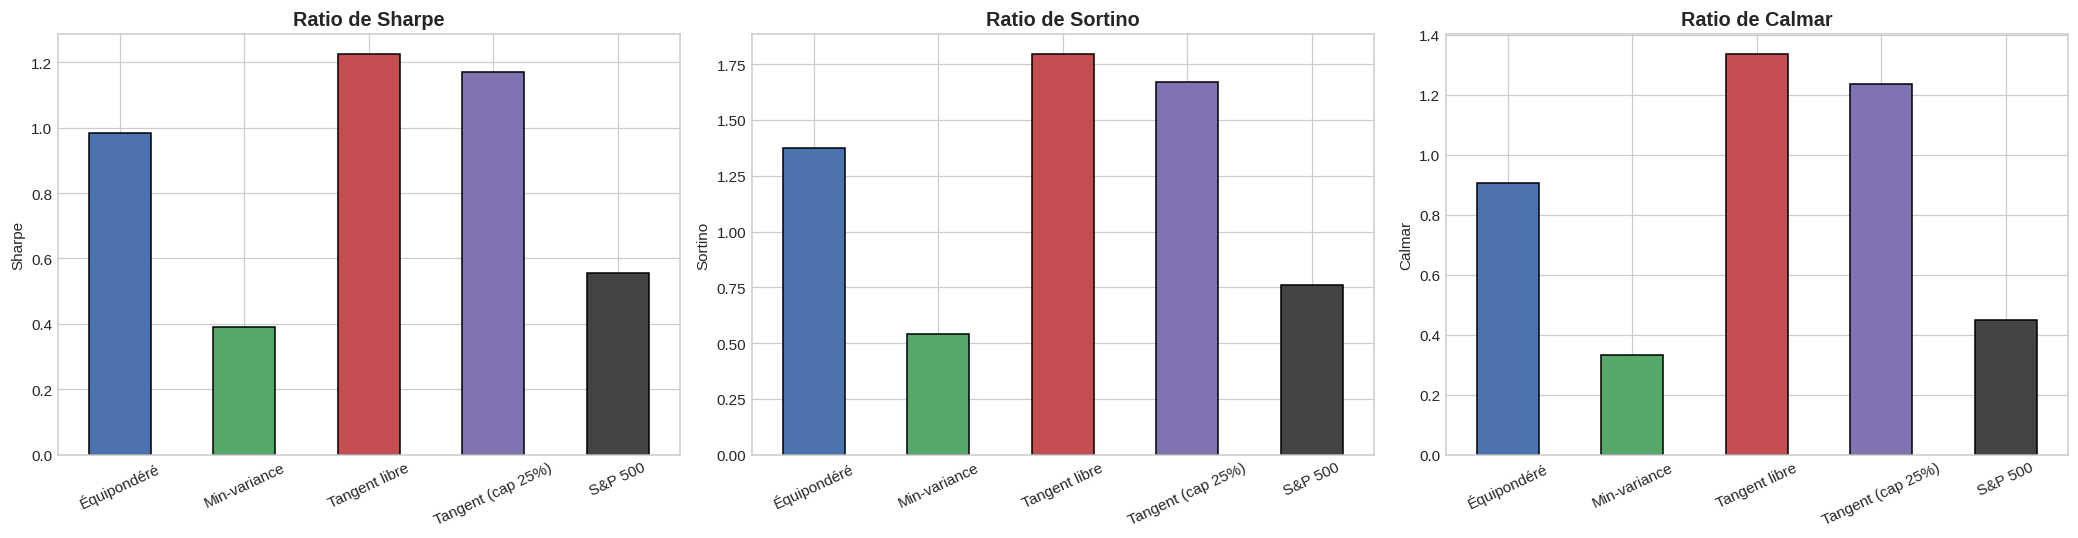

In [ ]:
# ============================================================
# 🧮 TABLEAU DE BORD DES RATIOS : SHARPE, SORTINO, CALMAR
# ============================================================
def full_metrics(rp):
    '''Rendement, volatilité, Sharpe, Sortino, Calmar, MDD, VaR/CVaR 95% historiques.'''
    ann_ret = rp.mean() * TRADING_DAYS
    ann_vol = rp.std() * np.sqrt(TRADING_DAYS)
    cum     = np.exp(rp.cumsum())
    mdd     = (cum / cum.cummax() - 1).min()
    cagr    = cum.iloc[-1] ** (TRADING_DAYS / len(rp)) - 1
    tdd     = np.sqrt(np.mean(np.minimum(rp - rf_d, 0.0) ** 2)) * np.sqrt(TRADING_DAYS)
    v95, c95 = var_cvar_historical(rp.values, 0.95)
    return {"Rend. log ann.": ann_ret, "CAGR": cagr, "Volatilité": ann_vol,
            "Sharpe": (ann_ret - R0) / ann_vol, "Sortino": (ann_ret - R0) / tdd,
            "Calmar": cagr / abs(mdd), "Max DD": mdd, "VaR 95%": v95, "CVaR 95%": c95}

metrics_df = pd.DataFrame({name: full_metrics(rp) for name, rp in port_logs.items()}).T

print("=" * 120); print("RATIOS DE PERFORMANCE AJUSTÉS DU RISQUE"); print("=" * 120)
fm = metrics_df.copy()
for c in ["Rend. log ann.", "CAGR", "Volatilité", "Max DD", "VaR 95%", "CVaR 95%"]:
    fm[c] = (metrics_df[c] * 100).round(2).astype(str) + " %"
for c in ["Sharpe", "Sortino", "Calmar"]:
    fm[c] = metrics_df[c].round(3)
print(fm.to_string())

print("\n📝 RAPPORT SORTINO / SHARPE (repère symétrique = √2 ≈ 1.41)")
for name, row in metrics_df.iterrows():
    print(f"  {name:18s}: {row['Sortino'] / row['Sharpe']:.2f}")

print("\n📝 CLASSEMENTS")
for ratio in ["Sharpe", "Sortino", "Calmar"]:
    ranking = metrics_df[ratio].sort_values(ascending=False)
    print(f"  {ratio:8s}: " + "  >  ".join(f"{n} ({v:.2f})" for n, v in ranking.items()))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, ratio in zip(axes, ["Sharpe", "Sortino", "Calmar"]):
    metrics_df[ratio].plot.bar(ax=ax, color=["#4c72b0", "#55a868", "#c44e52", "#8172b2", "#444444"], edgecolor="black", rot=25)
    ax.set_title(f"Ratio de {ratio}"); ax.set_ylabel(ratio)
plt.tight_layout(); plt.show()

### 🧠 Interprétation

- **Sortino vs Sharpe :** le Sortino est **mécaniquement supérieur** au Sharpe (≈ $\sqrt2\times$ pour une loi symétrique) ; l'information utile est donc le **rapport Sortino/Sharpe** imprimé ci-dessus, à comparer au repère $\sqrt2\approx1{,}41$. Un rapport au-dessus du repère indique que la volatilité provient davantage des **hausses** que des baisses : la pénalisation symétrique du Sharpe est alors trop sévère.
- **Calmar :** il rapporte le rendement composé à la **pire chute**. Un portefeuille peut avoir un bon Sharpe et un Calmar médiocre s'il subit un gros drawdown : il **sanctionne la concentration** (le tangent libre subit un drawdown plus sévère).
- **Cohérence des classements :** si les trois ratios classent les portefeuilles de la même façon, la conclusion est **robuste au choix de la mesure de risque** ; si le classement change (par exemple, le min-variance gagne en Calmar mais perd en Sharpe), c'est que les portefeuilles diffèrent par leur **profil de queue**, non par leur seule volatilité.
- **Position du tangent contraint :** il offre en général un **compromis** entre le rendement élevé du tangent libre et la protection du min-variance, avec un risque de queue (VaR/CVaR 95 %) plus faible que le libre.
- ✅ **Bilan de la Partie 4 :** la résilience d'un portefeuille ne se résume ni à sa volatilité ni à sa VaR ; elle se lit dans ses **drawdowns**, sa **réaction aux scénarios de crise** et ses **ratios asymétriques**. Ces indicateurs convergent pour justifier le **portefeuille tangent contraint** comme choix de **compromis robuste**.

# 🏁 PARTIE 5 — Conclusion & Limites
*Résumé des résultats · extension GARCH · limites de Markowitz · pistes futures*

## 📋 Étape 5.1 — Tableau de bord final

**🎯 Objectif.** Rassembler **en un seul endroit** tous les résultats chiffrés du projet, directement exploitables dans le rapport et les diapositives de soutenance. Toutes les valeurs sont **recalculées dynamiquement** à partir des variables du notebook : aucun chiffre n'est saisi à la main.

### 📐 Indicateurs rappelés

| Indicateur | Formule | Lecture |
|---|---|---|
| Sharpe | $(\mu-R^0)/\sigma$ | Rendement par unité de volatilité |
| VaR$_\alpha$ | $-Q_{1-\alpha}(R)$ | Perte seuil non dépassée avec probabilité $\alpha$ |
| CVaR$_\alpha$ | $-\mathbb E[R\mid R\le -\text{VaR}_\alpha]$ | Perte moyenne dans la queue |
| MDD | $\min_t (V_t/M_t-1)$ | Pire chute sommet → creux |
| $N_{eff}$ | $1/\sum w_i^2$ | Diversification effective de l'allocation |

In [ ]:
# ============================================================
# 📋 TABLEAU DE BORD FINAL (valeurs recalculées dynamiquement)
# ============================================================
line = "─" * 78
print("╔" + "═" * 76 + "╗")
print("║" + "RÉSUMÉ FINAL DU PROJET PFA — RISQUE DE PORTEFEUILLE".center(76) + "║")
print("╚" + "═" * 76 + "╝")
print(f"\n📅 Période : {ret_assets.index[0].date()} → {ret_assets.index[-1].date()} | {len(ret_assets)} jours | {N_ASSETS} actions + S&P 500")

print(f"\n{line}\n1️⃣  DATA & STATISTIQUES\n{line}")
print(f"  Normalité rejetée (Jarque-Bera) : {n_reject}/{N_ASSETS} actions | kurtosis moyenne = {jb_table['Kurtosis'].mean():.2f}")
print(f"  Corrélation moyenne             : {upper.mean():.2f} | part du 1er facteur = {eigvals[0] / N_ASSETS:.0%}")

print(f"\n{line}\n2️⃣  MARKOWITZ\n{line}")
top_free = pd.Series(w_tan, index=TICKERS).nlargest(2); top_con = pd.Series(w_tan_c, index=TICKERS).nlargest(4)
print(f"  Tangent libre   : " + ", ".join(f"{t} {w:.0%}" for t, w in top_free.items()) + f" | N_eff = {effective_n(w_tan):.1f} | Sharpe = {s_tan:.2f}")
print(f"  Tangent cap {MAX_WEIGHT:.0%}  : " + ", ".join(f"{t} {w:.0%}" for t, w in top_con.items()) + f" | N_eff = {effective_n(w_tan_c):.1f} | Sharpe = {s_tan_c:.2f}")
print(f"  Dispersion bootstrap des poids : libre {boot_free.std(axis=0).mean() * 100:.1f} pts → contraint {boot_con.std(axis=0).mean() * 100:.1f} pts")

print(f"\n{line}\n3️⃣  RISQUE — {W_RISK_NAME}\n{line}")
print((risk_table.round(3).astype(str) + " %").to_string())
print("\n  Backtesting (Kupiec / Christoffersen) :")
for _, row in backtest_df.iterrows():
    print(f"    α={row['α']} {row['Méthode']:16s}: {int(row['Dépass. x']):3d}/{T_TEST} = {row['Taux']:.2%} → {row['Verdict global']}")

print(f"\n{line}\n4️⃣  STRESS & RÉSILIENCE\n{line}")
covid_label = list(HIST_SCENARIOS.keys())[0]; bear_label = list(HIST_SCENARIOS.keys())[1]
print(f"  COVID (19/02→23/03/20)  : portefeuille {stress_df.loc[covid_label, W_RISK_NAME]:.1%} | S&P 500 {stress_df.loc[covid_label, 'S&P 500']:.1%}")
print(f"  Bear market 2022        : portefeuille {stress_df.loc[bear_label, W_RISK_NAME]:.1%} | S&P 500 {stress_df.loc[bear_label, 'S&P 500']:.1%}")
print(f"  Max Drawdown            : portefeuille {dd_rows[W_RISK_NAME]['Max DD']:.1%} | S&P 500 {dd_rows['S&P 500']['Max DD']:.1%}")
print(f"  Sharpe / Sortino / Calmar : {metrics_df.loc[W_RISK_NAME, 'Sharpe']:.2f} / {metrics_df.loc[W_RISK_NAME, 'Sortino']:.2f} / {metrics_df.loc[W_RISK_NAME, 'Calmar']:.2f}"
      f"  (S&P 500 : {metrics_df.loc['S&P 500', 'Sharpe']:.2f} / {metrics_df.loc['S&P 500', 'Sortino']:.2f} / {metrics_df.loc['S&P 500', 'Calmar']:.2f})")
print(f"  Bêta / Alpha de Jensen  : {bench_df.loc[W_RISK_NAME, 'Bêta']:.2f} / {bench_df.loc[W_RISK_NAME, 'Alpha Jensen']:.1%}")
print("\n" + "═" * 78 + "\n✅ Notebook exécuté de bout en bout — résultats prêts pour le rapport\n" + "═" * 78)

╔════════════════════════════════════════════════════════════════════════════╗
║            RÉSUMÉ FINAL DU PROJET PFA — RISQUE DE PORTEFEUILLE             ║
╚════════════════════════════════════════════════════════════════════════════╝

📅 Période : 2019-01-03 → 2024-12-31 | 1509 jours | 10 actions + S&P 500

──────────────────────────────────────────────────────────────────────────────
1️⃣  DATA & STATISTIQUES
──────────────────────────────────────────────────────────────────────────────
  Normalité rejetée (Jarque-Bera) : 10/10 actions | kurtosis moyenne = 11.77
  Corrélation moyenne             : 0.42 | part du 1er facteur = 50%

──────────────────────────────────────────────────────────────────────────────
2️⃣  MARKOWITZ
──────────────────────────────────────────────────────────────────────────────
  Tangent libre   : NVDA 58%, AAPL 40% | N_eff = 2.0 | Sharpe = 1.17
  Tangent cap 25%  : NVDA 25%, AAPL 25%, MSFT 24%, JPM 16% | N_eff = 4.7 | Sharpe = 1.07
  Dispersion bootstrap des p

### 🧠 Interprétation

Ce tableau de bord illustre la **cohérence d'ensemble** du projet : chaque chiffre de la Partie *n* justifie une décision de la Partie *n+1*.

- *Non-normalité (Partie 1)* → *Markowitz seul est insuffisant et la VaR gaussienne risquée*.
- *Concentration à 98 % sur 2 titres (Partie 2)* → *contrainte à 25 %, dispersion bootstrap réduite*.
- *VaR historique et paramétrique validées, Monte Carlo rejetée à 95 % (exécution de référence, Partie 3)* → *la VaR ne suffit pas, il faut la CVaR*.
- *Pertes de crise ≫ VaR journalière (Partie 4)* → *le stress testing complète la VaR*.

## 🔄 Étape 5.2 — Extension : volatilité conditionnelle GARCH(1,1) avec innovations Student-t

**🎯 Objectif.** Répondre à **deux limites** identifiées dans les Parties 1 et 3 : (i) la volatilité est **conditionnelle** (clusters de volatilité), (ii) les rendements ont des **queues épaisses**. Le modèle **GARCH(1,1)-t** traite les deux simultanément et produit une VaR qui **s'adapte quotidiennement** au régime de volatilité courant.

> ℹ️ Il s'agit d'une **extension illustrative** : les paramètres sont estimés sur **tout l'échantillon** (VaR *in-sample*). Une validation rigoureuse nécessiterait une réestimation glissante.

### 📐 Cadre théorique

**GARCH(1,1)** (Bollerslev, 1986) avec innovations de Student-t standardisées :
$$r_t=m+\varepsilon_t,\qquad \varepsilon_t=\sigma_t z_t,\qquad z_t\sim t_\nu\!\left(\text{variance }1\right)$$
$$\sigma_t^{2}=\omega+\alpha\,\varepsilon_{t-1}^{2}+\beta\,\sigma_{t-1}^{2}$$

**Persistance** : $\alpha+\beta<1$ ; plus elle est proche de 1, plus les chocs de volatilité sont durables. **Demi-vie** d'un choc : $\dfrac{\ln 0{,}5}{\ln(\alpha+\beta)}$ jours. **Variance inconditionnelle** : $\dfrac{\omega}{1-\alpha-\beta}$.

**VaR conditionnelle à un jour** (information jusqu'en $t-1$) :
$$\text{VaR}_{\alpha,t}=-\Big(m+\sigma_t\,q_{1-\alpha}\Big),\qquad q_{1-\alpha}=t_\nu^{-1}(1-\alpha)\sqrt{\tfrac{\nu-2}{\nu}}$$
(le facteur $\sqrt{(\nu-2)/\nu}$ standardise la Student-t à variance 1).

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 23.5 MB/s eta 0:00:00
GARCH(1,1)-t — Tangent (cap 25%)
  ω = 0.07411 | α = 0.1104 | β = 0.8645 | ν = 6.79
  Persistance α+β        : 0.9749
  Demi-vie d'un choc     : 27.3 jours
  Vol. inconditionnelle  : 27.29 % (annualisée) vs historique 27.97 %

BACKTEST IN-SAMPLE DE LA VaR GARCH-t (T = 1509 jours)
  α  Dépass.   Taux  p Kupiec  p Christ.  p CC
95%      101 0.0669     0.004      0.232 0.008
99%       20 0.0133     0.226      0.475 0.373

📝 Lecture automatique : indépendance des dépassements (Christoffersen) → α=95% : ✅ non rejetée | α=99% : ✅ non rejetée


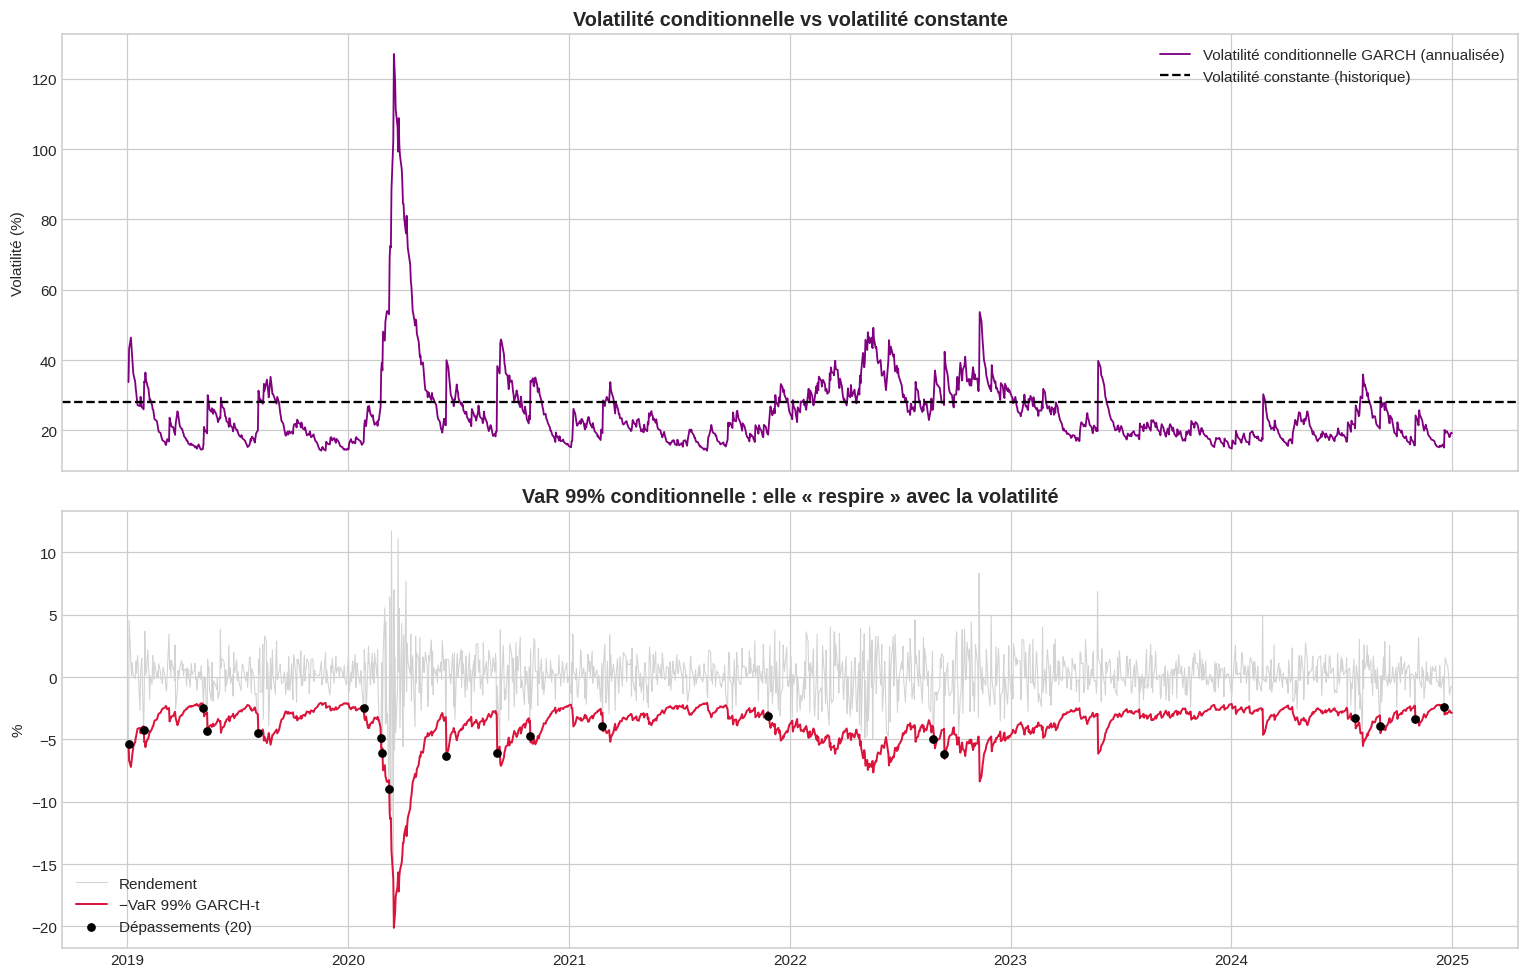

In [ ]:
# ============================================================
# 🔄 EXTENSION GARCH(1,1)-t : VaR CONDITIONNELLE
# ============================================================
try:
    from arch import arch_model
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "arch"])
    from arch import arch_model

returns_pct = port_ret * 100                           # mise à l'échelle en % (stabilité numérique de l'optimiseur)
garch_res   = arch_model(returns_pct, mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")

m_g, omega_g = garch_res.params["mu"], garch_res.params["omega"]
alpha_g, beta_g, nu_g = garch_res.params["alpha[1]"], garch_res.params["beta[1]"], garch_res.params["nu"]
persist = alpha_g + beta_g

print("=" * 65); print(f"GARCH(1,1)-t — {W_RISK_NAME}"); print("=" * 65)
print(f"  ω = {omega_g:.5f} | α = {alpha_g:.4f} | β = {beta_g:.4f} | ν = {nu_g:.2f}")
print(f"  Persistance α+β        : {persist:.4f}")
print(f"  Demi-vie d'un choc     : {np.log(0.5) / np.log(persist):.1f} jours")
print(f"  Vol. inconditionnelle  : {np.sqrt(omega_g / (1 - persist)) * np.sqrt(TRADING_DAYS):.2f} % (annualisée) vs historique {port_ret.std() * np.sqrt(TRADING_DAYS) * 100:.2f} %")

cond_vol = garch_res.conditional_volatility / 100                       # retour en unités décimales
garch_hits, garch_rows, garch_var = {}, [], {}
for a in ALPHAS:
    q = stats.t.ppf(1 - a, nu_g) * np.sqrt((nu_g - 2) / nu_g)
    garch_var[a] = -(m_g / 100 + cond_vol * q)
    h = (-port_ret > garch_var[a]).values
    x = int(h.sum())
    lr_pof, p_pof = kupiec_pof(x, len(h), 1 - a)
    lr_ind, p_ind = christoffersen_independence(h)
    garch_hits[a] = h
    garch_rows.append({"α": f"{a:.0%}", "Dépass.": x, "Taux": x / len(h), "p Kupiec": p_pof, "p Christ.": p_ind,
                       "p CC": 1 - stats.chi2.cdf(lr_pof + lr_ind, 2)})
garch_bt = pd.DataFrame(garch_rows)
print("\nBACKTEST IN-SAMPLE DE LA VaR GARCH-t (T = %d jours)" % len(port_ret))
print(garch_bt.round({"Taux": 4, "p Kupiec": 3, "p Christ.": 3, "p CC": 3}).to_string(index=False))
print("\n📝 Lecture automatique : indépendance des dépassements (Christoffersen) → " +
      " | ".join(f"α={r['α']} : {'✅ non rejetée' if r['p Christ.'] > 0.05 else '❌ rejetée'}" for r in garch_rows))

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
axes[0].plot(cond_vol.index, cond_vol * np.sqrt(TRADING_DAYS) * 100, color="purple", lw=1.2, label="Volatilité conditionnelle GARCH (annualisée)")
axes[0].axhline(port_ret.std() * np.sqrt(TRADING_DAYS) * 100, color="black", ls="--", label="Volatilité constante (historique)")
axes[0].set_ylabel("Volatilité (%)"); axes[0].set_title("Volatilité conditionnelle vs volatilité constante"); axes[0].legend()
axes[1].plot(port_ret.index, port_ret * 100, color="lightgrey", lw=0.7, label="Rendement")
axes[1].plot(port_ret.index, -garch_var[0.99] * 100, color="crimson", lw=1.3, label="−VaR 99% GARCH-t")
h99 = garch_hits[0.99]
axes[1].scatter(port_ret.index[h99], port_ret[h99] * 100, color="black", s=22, zorder=5, label=f"Dépassements ({h99.sum()})")
axes[1].set_ylabel("%"); axes[1].set_title("VaR 99% conditionnelle : elle « respire » avec la volatilité"); axes[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

### 🧠 Interprétation

- **Persistance élevée :** la somme $\alpha+\beta$ est **proche de 1** et la demi-vie d'un choc se compte en **dizaines de jours** : un pic de volatilité (mars 2020) met longtemps à se résorber. C'est le *volatility clustering* documenté à l'Étape 1.2, désormais **modélisé** plutôt que simplement constaté.
- **VaR adaptative :** contrairement à la VaR à fenêtre glissante (qui réagit avec retard), la VaR GARCH **augmente immédiatement** après un choc et **diminue** en période calme. Le graphique du bas permet de juger visuellement si les dépassements sont **moins regroupés** ; le test d'indépendance de Christoffersen (lecture automatique) le vérifie statistiquement.
- **Degrés de liberté $\hat\nu$ :** de l'ordre de quelques unités, il confirme les queues épaisses (Étape 3.1) : GARCH-t combine bien les **deux corrections** (variance conditionnelle + queues épaisses).
- ⚠️ **Prudence :** le backtest est **in-sample** (paramètres estimés sur toutes les données), donc *favorable* au modèle. Cette extension démontre un **gain qualitatif** ; une conclusion définitive exigerait une réestimation glissante hors échantillon.

## ⚠️ Étape 5.3 — Limites du travail

**🎯 Objectif.** Identifier honnêtement les **faiblesses méthodologiques** de l'étude. Reconnaître ses limites est un marqueur de rigueur — et précisément ce qu'un jury de finance quantitative attend d'un candidat.

### 1️⃣ Limites du modèle de Markowitz
| Limite | Conséquence observée dans le projet |
|---|---|
| **Sensibilité aux inputs** ($\hat\mu$ très bruité) | Tangent libre à 98 % sur 2 titres ; allocation instable au bootstrap |
| **Variance = seule mesure de risque** | Ignore asymétrie et queues épaisses (Jarque-Bera rejeté) |
| **Paramètres supposés constants** | Corrélations → 1 en crise ; volatilité conditionnelle (GARCH) |
| **Modèle à une période, sans coûts** | Pas de coûts de transaction, de taxes, de liquidité ; rebalancement quotidien implicite |
| **Optimisation sur l'échantillon d'évaluation** | Performances in-sample **optimistes** (biais de look-ahead) |

### 2️⃣ Limites des données et de la méthode
- **Biais de sélection / survivance** : les 10 titres sont des grandes capitalisations *gagnantes ex-post* ; un univers défini en 2019 aurait inclus des perdants.
- **Échantillon court (6 ans)** dominé par deux événements (COVID, boom de l'IA) : estimations de $\mu$ et de queue peu fiables.
- **Un seul découpage hors échantillon** (Étape 2.6) : puissance statistique faible.
- **Contrainte de 25 % arbitraire** : non calibrée (ni par validation croisée, ni par une pénalisation optimale).

### 3️⃣ Limites de la mesure du risque
- **VaR à 1 jour** : l'extension à 10 jours par $\sqrt T$ suppose des rendements i.i.d. — faux en présence de clusters de volatilité.
- **Kupiec/Christoffersen** : faible puissance à 99 % sur ~1 250 jours (≈ 12 dépassements attendus).
- **Stress tests** : scénarios *historiques* et *ad hoc*, non probabilisés ; ils ne couvrent pas des crises *nouvelles*.
- **Dépendance** : la matrice de corrélation linéaire ne capte pas la **dépendance de queue** (corrélations plus fortes dans les krachs).

## 🚀 Étape 5.4 — Conclusion générale et extensions futures

### ✅ Ce que le projet a démontré

1. **Les rendements ne sont pas gaussiens** : Jarque-Bera rejette la normalité pour **10 actions sur 10** (kurtosis > 3), et la non-normalité **persiste au niveau du portefeuille**.
2. **Le portefeuille tangent de Markowitz non contraint est numériquement optimal mais statistiquement fragile** : il se concentre à **98 % sur NVDA (58 %) et AAPL (40 %)**. Le diagnostic (précision de $\hat\mu$, bootstrap) établit qu'il s'agit d'une manifestation de l'*Error Maximization*.
3. **La contrainte à 25 % par titre corrige cette fragilité** : elle diversifie l'allocation, réduit l'instabilité par rééchantillonnage, pour un **coût limité en Sharpe in-sample**.
4. **La VaR paramétrique est conceptuellement dangereuse** : sa CVaR sous-estime la gravité des pertes de queue. Au backtest (exécution de référence), les VaR **historique et paramétrique sont validées** (taux ≈ 5-6 %), la **Monte Carlo Student-t est rejetée** à 95 % — résultat expliqué par la géométrie des quantiles de la Student-t et le bruit d'estimation de $\nu$.
5. **Les stress tests et le drawdown révèlent ce que la VaR ne voit pas** : les pertes de crise valent un multiple de la VaR journalière.
6. **Performance** : le portefeuille contraint domine le S&P 500 *sur l'échantillon* — avec la réserve d'un biais de look-ahead — pour un bêta et un risque de queue plus élevés.

### 🔑 Les 3 messages à retenir pour la soutenance

> **①** *« Un portefeuille optimal sur l'échantillon n'est pas un portefeuille optimal : Markowitz amplifie l'erreur d'estimation (Error Maximization). »*
>
> **②** *« Une VaR validée par Kupiec dit combien de fois on se trompe, jamais de combien : la CVaR et le stress testing sont indispensables. »*
>
> **③** *« La robustesse a un coût mesurable (ΔSharpe in-sample) et un bénéfice mesurable (stabilité, dégradation hors échantillon). »*

### 🧭 Extensions futures (par ordre de priorité)

| # | Extension | Problème traité |
|---|---|---|
| 1 | **Backtest walk-forward** (réestimation glissante des poids) | Biais de look-ahead, un seul découpage OOS |
| 2 | **Shrinkage de Ledoit-Wolf** sur $\Sigma$ ; **Black-Litterman** sur $\mu$ | Erreur d'estimation à la source (plutôt que contrainte *ad hoc*) |
| 3 | **Rééchantillonnage de Michaud** (moyenne de portefeuilles bootstrap) ; **Hierarchical Risk Parity** | Instabilité des poids |
| 4 | **Optimisation CVaR** (Rockafellar-Uryasev, programme linéaire) | Mesure de risque cohérente dans l'optimiseur |
| 5 | **VaR GARCH roulante / Filtered Historical Simulation / EVT (POT-GPD)** | Volatilité conditionnelle et modélisation rigoureuse de la queue |
| 6 | **DCC-GARCH** et **copules** (dépendance de queue) | Corrélations dynamiques, co-mouvements extrêmes |
| 7 | Univers élargi + **coûts de transaction** | Réalisme opérationnel |

### 📚 Références
- Markowitz, H. (1952). *Portfolio Selection*. Journal of Finance.
- Michaud, R. (1989). *The Markowitz Optimization Enigma: Is Optimized Optimal?* Financial Analysts Journal.
- Jagannathan, R. & Ma, T. (2003). *Risk Reduction in Large Portfolios: Why Imposing the Wrong Constraints Helps.* Journal of Finance.
- DeMiguel, V., Garlappi, L. & Uppal, R. (2009). *Optimal Versus Naive Diversification.* Review of Financial Studies.
- Artzner, P., Delbaen, F., Eber, J.-M. & Heath, D. (1999). *Coherent Measures of Risk.* Mathematical Finance.
- Rockafellar, R.T. & Uryasev, S. (2000). *Optimization of Conditional Value-at-Risk.* Journal of Risk.
- Kupiec, P. (1995). *Techniques for Verifying the Accuracy of Risk Measurement Models.* Journal of Derivatives.
- Christoffersen, P. (1998). *Evaluating Interval Forecasts.* International Economic Review.
- Bollerslev, T. (1986). *Generalized Autoregressive Conditional Heteroskedasticity.* Journal of Econometrics.
- Jarque, C. & Bera, A. (1980). *Efficient Tests for Normality, Homoscedasticity and Serial Independence of Regression Residuals.* Economics Letters.
- Cont, R. (2001). *Empirical Properties of Asset Returns: Stylized Facts and Statistical Issues.* Quantitative Finance.